# AIML506 — GraphRAG vs Vector RAG on DrugRev

**Course:** AIML506 — Artificial Intelligence and Machine Learning  
**Institution:** Department of Computer Science and Engineering, East West University, Dhaka, Bangladesh  
**Instructor:** Dr. Mohammad Rifat Ahmmad Rashid  
**Student:** [Enter your full name]  
**Student ID:** [Enter your student ID]  
**Dataset:** *DrugRev: A comprehensive customers reviews on drugs purchasing and satisfaction*  
**Source:** Mendeley Data, Version 1  
**DOI:** [10.17632/64cc5w5dxy.1](https://doi.org/10.17632/64cc5w5dxy.1)  
**Licence:** Creative Commons Attribution 4.0 International (CC BY 4.0)

---

## Read this before selecting Run All

This notebook is designed for Kaggle. It performs the complete computational workflow: data acquisition and preprocessing, expanded EDA, graph construction in Neo4j Aura, vector indexing in ChromaDB, four-model ablation, a 30-question benchmark, required evaluation metrics, comparison tables, error analysis, and export of result files. **The written IEEE report is intentionally not included; it will be prepared after the final results are available.**

### Kaggle settings and one-time setup

1. Create a new Kaggle notebook and upload this `.ipynb` file.
2. In **Settings**, enable **Internet** and select a **GPU accelerator** (T4 is suitable for the 4-bit model configuration; availability depends on your Kaggle account quota).
3. Use a **fresh Neo4j Aura instance** if possible, especially if earlier credentials were exposed. Otherwise rotate any exposed credentials: this repaired notebook uses dedicated `AIML506*` labels and new constraint/index names to avoid conflicts with older generic `Drug` / `Condition` unique constraints. Add your active credentials to Kaggle Secrets. Do not reuse an exposed password.
4. Add these entries under **Add-ons → Secrets** in Kaggle:
   - `NEO4J_URI`
   - `NEO4J_USERNAME`
   - `NEO4J_PASSWORD`
   - `NEO4J_DATABASE` (optional; defaults to `neo4j`)
5. For the final public Kaggle submission, attach the original Mendeley `DrugReviews.csv` as a Kaggle input. The notebook can also download it directly from the official Mendeley Data file record when testing if it is not attached.
6. Run all cells from top to bottom. Do not skip the graph, model, or evaluation cells.

**No Groq API key is required.** The four language models are downloaded from their public Hugging Face repositories and run locally in 4-bit mode. Model downloads and inference require Internet and a working Kaggle GPU. If Neo4j secrets are absent, the notebook stops at the connection cell and explains which secret is missing; this is intentional because the assignment requires a live Neo4j Aura graph.

### Models used

| Model | Hugging Face repository | Experiment role |
|---|---|---|
| Mistral 7B Instruct v0.3 | `mistralai/Mistral-7B-Instruct-v0.3` | Primary generator for the main 30-question comparison |
| Qwen 2.5 7B Instruct | `Qwen/Qwen2.5-7B-Instruct` | Ablation model and independent LLM judge |
| Zephyr 7B Beta | `HuggingFaceH4/zephyr-7b-beta` | Additional ablation model |
| Phi-3.5 Mini Instruct | `microsoft/Phi-3.5-mini-instruct` | Additional ablation model |

The primary comparison uses the same Mistral generator, system prompt, temperature, output limit, context budget, benchmark questions, and source sample for GraphRAG and Vector RAG. The retrieval mechanisms are the intended experimental difference.

### Important research-integrity note

This notebook does not invent human annotations. It creates two audit templates: one for manual validation of the rule-based adverse-reaction extraction and one for checking the LLM judge against at least ten human-labelled answers. These templates must be completed by a human before claiming that those two manual-validation requirements have been satisfied. The notebook reports their status honestly.


**Final viva requirement:** keep the Neo4j Aura instance available and resume it before the viva.


## 0. Assignment coverage and reproducibility plan

The notebook follows the assignment tasks in order:

1. **Problem and data understanding:** domain, user needs, data card, source DOI/licence, sampling, data-quality checks, and exploratory analysis.
2. **Graph model design:** property-graph diagram, node and relationship tables, uniqueness constraints, full-text index, provenance, batched parameterized `UNWIND` loading, graph counts, and five exploratory Cypher queries.
3. **GraphRAG:** entity linking, graph query templates, multi-hop retrieval, evidence-grounded generation, and out-of-scope refusal.
4. **Vector RAG:** document serialization, MiniLM embeddings, ChromaDB cosine search, and top-5 retrieval.
5. **LLM selection:** four locally loaded 4-bit models, documented generation settings, one common main generator, a separate judge model, and model ablation.
6. **Benchmark:** 30 data-grounded questions, six in each of the five required categories, with dynamically generated gold answers, key items, and evidence IDs.
7. **Comparison:** retrieval, answer, grounding, refusal, entity-linking, citation, latency, context-size, build/indexing, per-type, ablation, and error-analysis outputs.

**Why this domain is suitable:** DrugRev links medications, conditions, patient narratives, intake durations, and lexicon-matched adverse-reaction mentions. This supports multi-hop and aggregation questions for a property graph while also containing narrative text suitable for semantic vector retrieval. The ten-condition sample makes the scope manageable while retaining a few thousand reviews.

**Reproducibility:** fixed random seed, deterministic sampling, temperature 0, `do_sample=False`, stable evidence IDs, saved benchmark/results CSVs, and project-scoped Neo4j nodes. The graph loader replaces only nodes belonging to this notebook's project namespace; it does not delete unrelated data in the Aura database.


## 1. Install dependencies


In [1]:
# Kaggle Internet must be enabled for package installation and model/data downloads.
%pip install -q "neo4j>=5.25,<6" "chromadb>=0.5.23,<1.0" "transformers==4.48.3" "tokenizers>=0.21,<0.22" "accelerate>=1.1" "bitsandbytes>=0.45" "seaborn>=0.13" "huggingface_hub>=0.26,<1.0" "safetensors>=0.4" "onnxruntime>=1.17" "sentencepiece>=0.2" "einops>=0.8"


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
aiobotocore 2.26.0 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 4.0.0 which is incompatible.
botocore 1.41.5 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.107 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
tweepy 4.17.0 requires oau

## 2. Imports, configuration, and reproducibility


In [2]:
import os, re, glob, json, time, math, gc, hashlib, shutil, zipfile, warnings, textwrap
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

SEED = 42
np.random.seed(SEED)

HF_CACHE_ROOT = "/kaggle/temp/aiml506_hf_cache" if os.path.exists("/kaggle") else os.path.abspath("hf_cache")
os.makedirs(HF_CACHE_ROOT, exist_ok=True)
os.environ["HF_HOME"] = HF_CACHE_ROOT
os.environ["TRANSFORMERS_CACHE"] = HF_CACHE_ROOT
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["CHROMA_TELEMETRY"] = "FALSE"

WORKING_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else os.path.abspath("outputs")
os.makedirs(WORKING_DIR, exist_ok=True)
PROJECT_ID = "AIML506_DRUGREV_GRAPHRAG_VECTORRAG_V3"
DATASET_DOI = "10.17632/64cc5w5dxy.1"
DATASET_TITLE = "DrugRev: A comprehensive customers reviews on drugs purchasing and satisfaction"
DATASET_SOURCE_URL = "https://data.mendeley.com/datasets/64cc5w5dxy/1"
DATASET_FILE_URL = "https://data.mendeley.com/public-files/datasets/64cc5w5dxy/files/288e24c1-4605-4c4b-9a88-c789f94dbe35/file_downloaded"

TARGET_CONDITIONS = [
    "Depression", "Anxiety", "Pain", "Insomnia", "Diabetes, Type 2",
    "High Blood Pressure", "Bipolar Disorder", "Weight Loss (Obesity/Overweight)",
    "Acne", "ADHD"
]
SAMPLE_PER_CONDITION = 450
TOP_K = 5
MAX_INPUT_TOKENS = 3072
MAX_CONTEXT_TOKENS = 1800  # Evidence portion of the input prompt, after chat-template overhead.
MAX_NEW_TOKENS = 160
TEMPERATURE = 0.0
PRIMARY_MODEL_KEY = "mistral_v03"
JUDGE_MODEL_KEY = "qwen25_7b"
RUN_MODEL_ABLATION = True
ABLATION_QUESTIONS_PER_TYPE = 1  # one representative question from each of the five categories

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 130
plt.rcParams["savefig.dpi"] = 180
pd.set_option("display.max_colwidth", 140)

print("Working directory:", WORKING_DIR)
print("Project namespace:", PROJECT_ID)
print("Seed:", SEED)


Working directory: /kaggle/working
Project namespace: AIML506_DRUGREV_GRAPHRAG_VECTORRAG_V3
Seed: 42


## TASK 1 — Problem and data understanding

### 1.1 Domain, intended users, and question types

**Domain:** clinical pharmacology, pharmacovigilance, and patient-reported medication experiences.  
**Intended users:** clinical researchers, pharmacovigilance analysts, hospital formulary committees, and healthcare professionals exploring patterns in patient-submitted reviews. The system is a research-support tool, not a diagnostic or prescribing system.

The benchmark covers the five question types required by the assignment:

- **Single-hop:** one medication-condition fact, such as the sample rating and review count.
- **Multi-hop:** a condition is linked to a medication and then to a patient-reported adverse reaction.
- **Aggregation:** ranking, counting, comparing, or grouping across records.
- **Semantic/descriptive:** retrieval and summarization of free-text patient narratives.
- **Unanswerable:** requests for information not contained in customer reviews, such as chemical binding affinity or official dosing guidance.

### 1.2 Data source and acquisition

The original source is the Mendeley Data record, not a Kaggle mirror. The record describes a CSV containing 392,510 customer reviews. The notebook samples up to 450 records from each of ten selected conditions (maximum target sample: 4,500 records), using a fixed seed. Any smaller condition group is retained in full and reported; no missing condition group is silently fabricated.


### 1.3 Locate or download the original Mendeley CSV


In [3]:
def locate_dataset_file():
    # Prefer an exact official filename in Kaggle inputs.
    candidates = glob.glob("/kaggle/input/**/DrugReviews.csv", recursive=True)
    candidates += glob.glob(os.path.join(WORKING_DIR, "DrugReviews.csv"))
    candidates += glob.glob("./DrugReviews.csv")
    candidates = [p for p in candidates if os.path.isfile(p) and os.path.getsize(p) > 10000]
    if candidates:
        return candidates[0]

    print("DrugReviews.csv was not found among attached Kaggle inputs. Downloading from Mendeley Data...")
    target = os.path.join(WORKING_DIR, "DrugReviews_download")
    os.makedirs(target, exist_ok=True)
    download_path = os.path.join(target, "DrugReviews_download")
    response = requests.get(DATASET_FILE_URL, stream=True, timeout=180, allow_redirects=True)
    response.raise_for_status()
    with open(download_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    # Mendeley may return a direct CSV or a ZIP container.
    if zipfile.is_zipfile(download_path):
        with zipfile.ZipFile(download_path) as zf:
            csv_members = [n for n in zf.namelist() if n.lower().endswith(".csv")]
            if not csv_members:
                raise RuntimeError("The downloaded Mendeley archive contains no CSV file.")
            member = next((n for n in csv_members if os.path.basename(n).lower() == "drugreviews.csv"), csv_members[0])
            extracted = os.path.join(target, "DrugReviews.csv")
            with zf.open(member) as src, open(extracted, "wb") as dst:
                shutil.copyfileobj(src, dst)
            return extracted

    final_path = os.path.join(target, "DrugReviews.csv")
    os.replace(download_path, final_path)
    if os.path.getsize(final_path) < 10000:
        raise RuntimeError("The downloaded file is unexpectedly small; verify Kaggle Internet access and the Mendeley file URL.")
    return final_path

DATA_FILE = locate_dataset_file()
print("Dataset file:", DATA_FILE)
print("File size (MB):", round(os.path.getsize(DATA_FILE) / (1024**2), 2))


Dataset file: /kaggle/input/datasets/shaikjasheen/drug-reviews-dataset/DrugReviews.csv
File size (MB): 162.56


### 1.4 Column mapping, cleaning, and reproducible stratified sampling


In [4]:
raw = pd.read_csv(DATA_FILE, low_memory=False)
RAW_ROWS_LOADED=int(len(raw))
print("Raw shape:", raw.shape)
print("Raw columns:", raw.columns.tolist())

# Resolve source column names robustly while retaining the original source fields.
def resolve_column(frame, aliases, required=True):
    lookup = {str(c).strip().lower(): c for c in frame.columns}
    for alias in aliases:
        if alias.lower() in lookup:
            return lookup[alias.lower()]
    if required:
        raise KeyError(f"Could not find any of these required source columns: {aliases}. Available columns: {list(frame.columns)}")
    return None

col_drug = resolve_column(raw, ["MedicineName", "Drug", "DrugName", "Medicine", "drug_name"])
col_condition = resolve_column(raw, ["MedicineFor", "Condition", "Indication", "medicine_for"])
col_review = resolve_column(raw, ["Reviews", "Review", "ReviewText", "Text", "review_text"])
col_rating = resolve_column(raw, ["Rating", "Score", "rating"])
col_user = resolve_column(raw, ["UserName", "Username", "User", "Patient"], required=False)
col_intake = resolve_column(raw, ["IntakeTime", "IntakeDuration", "Duration", "TimeTaken"], required=False)
col_likes = resolve_column(raw, ["NumberOfLikes", "Likes", "UsefulCount", "Helpful"], required=False)
col_length = resolve_column(raw, ["ReviewLength", "Length"], required=False)

SOURCE_MISSING_COUNTS={
    "MedicineName":int(raw[col_drug].isna().sum()),
    "Condition":int(raw[col_condition].isna().sum()),
    "Reviews":int(raw[col_review].isna().sum()),
    "Rating":int(raw[col_rating].isna().sum()),
    "UserName":int(raw[col_user].isna().sum()) if col_user else RAW_ROWS_LOADED,
    "IntakeDuration":int(raw[col_intake].isna().sum()) if col_intake else RAW_ROWS_LOADED,
    "NumberOfLikes":int(raw[col_likes].isna().sum()) if col_likes else RAW_ROWS_LOADED,
    "ReviewLength":int(raw[col_length].isna().sum()) if col_length else RAW_ROWS_LOADED
}
SOURCE_DUPLICATE_ROWS=int(raw.duplicated(subset=[col_drug,col_condition,col_rating,col_review]).sum())

condition_aliases = {
    "diabetes type 2": "Diabetes, Type 2", "type 2 diabetes": "Diabetes, Type 2",
    "diabetes, type 2": "Diabetes, Type 2", "high blood pressure": "High Blood Pressure",
    "hypertension": "High Blood Pressure", "weight loss": "Weight Loss (Obesity/Overweight)",
    "obesity": "Weight Loss (Obesity/Overweight)", "overweight": "Weight Loss (Obesity/Overweight)",
    "attention deficit hyperactivity disorder": "ADHD", "adhd": "ADHD"
}

def canonical_condition(value):
    s = str(value).strip()
    s = re.sub(r"^for\s+", "", s, flags=re.I).strip()
    low = re.sub(r"\s+", " ", s.lower())
    if low in condition_aliases:
        return condition_aliases[low]
    target_lookup = {re.sub(r"\s+", " ", x.lower()): x for x in TARGET_CONDITIONS}
    return target_lookup.get(low, s)

work = pd.DataFrame({
    "_source_row": raw.index.astype(int),
    "MedicineName": raw[col_drug].astype("string").str.strip(),
    "Condition": raw[col_condition].map(canonical_condition),
    "Reviews": raw[col_review].fillna("").astype(str).str.strip(),
    "Rating": pd.to_numeric(raw[col_rating], errors="coerce"),
    "UserName": raw[col_user].fillna("Anonymous_User").astype(str).str.strip() if col_user else "Anonymous_User",
    "IntakeDuration": raw[col_intake].fillna("Not Specified").astype(str).str.strip() if col_intake else "Not Specified",
    "NumberOfLikes": pd.to_numeric(raw[col_likes], errors="coerce").fillna(0) if col_likes else 0,
    "ReviewLength": pd.to_numeric(raw[col_length], errors="coerce") if col_length else np.nan
})

work["MedicineName"] = work["MedicineName"].replace({"<NA>": np.nan, "nan": np.nan, "": np.nan})
work["Condition"] = work["Condition"].replace({"<NA>": np.nan, "nan": np.nan, "": np.nan})
work = work.dropna(subset=["MedicineName", "Condition", "Rating"]).copy()
work["ReviewLength"] = work["ReviewLength"].fillna(work["Reviews"].str.len()).astype(int)
work["NumberOfLikes"] = pd.to_numeric(work["NumberOfLikes"], errors="coerce").fillna(0).astype(int)

# Normalize duration labels without inferring a duration that is not in the source.
DURATION_LABELS = [
    "Taken for less than 1 month", "Taken for 1 to 6 months", "Taken for 6 months to 1 year",
    "Taken for 1 to 2 years", "Taken for 2 to 5 years", "Taken for 5 to 10 years",
    "Taken for 10 years or more"
]
def normalize_duration(x):
    s = str(x).strip()
    if not s or s.lower() in {"nan", "none", "<na>", "not specified"}:
        return "Not Specified"
    for label in DURATION_LABELS:
        if s.lower() == label.lower():
            return label
    return "Other / Unclassified"
work["IntakeDuration"] = work["IntakeDuration"].map(normalize_duration)

available_conditions = set(work["Condition"].unique())
missing_target_conditions = [c for c in TARGET_CONDITIONS if c not in available_conditions]
print("Target conditions absent from this source version:", missing_target_conditions)
filtered = work[work["Condition"].isin(TARGET_CONDITIONS)].copy()
if filtered.empty:
    raise ValueError("No target conditions matched the dataset. Inspect the printed source columns and condition values before proceeding.")

sample_parts = []
for condition, group in filtered.groupby("Condition", sort=True):
    n = min(SAMPLE_PER_CONDITION, len(group))
    sample_parts.append(group.sample(n=n, random_state=SEED))
df = pd.concat(sample_parts, ignore_index=False).sort_values(["Condition", "MedicineName", "_source_row"]).reset_index(drop=True)
df["ReviewId"] = df["_source_row"].map(lambda x: f"REV_{int(x):07d}")
# Hash usernames before graph insertion; raw usernames are not loaded into Neo4j.
def pseudonymize_user(x):
    value = str(x).strip() or "Anonymous_User"
    return hashlib.sha256(value.encode("utf-8")).hexdigest()[:16]
df["PatientID"] = df["UserName"].map(pseudonymize_user)

del raw, work, filtered, sample_parts
gc.collect()
print("Sample shape:", df.shape)
print("Unique medications:", df["MedicineName"].nunique())
print("Unique conditions:", df["Condition"].nunique())
print("Rows by condition:")
display(df["Condition"].value_counts().reindex(TARGET_CONDITIONS).fillna(0).astype(int).to_frame("sample_reviews"))


Raw shape: (392510, 9)
Raw columns: ['MedicineName', 'MedicineFor', 'ReviewDate', 'UserName', 'IntakeTime', 'Reviews', 'ReviewLength', 'Rating', 'NumberOfLikes']
Target conditions absent from this source version: []
Sample shape: (4500, 11)
Unique medications: 470
Unique conditions: 10
Rows by condition:


,sample_reviews
Condition,
Depression,450
Anxiety,450
Pain,450
Insomnia,450
"Diabetes, Type 2",450
High Blood Pressure,450
Bipolar Disorder,450
Weight Loss (Obesity/Overweight),450
Acne,450


### 1.5 Rule-based adverse-reaction extraction and validation plan


In [5]:
# This is a transparent lexicon/regex extraction step, not clinical causality detection.
SE_CAT_MAP = {
    "nausea": "Gastrointestinal", "headache": "Neurological", "dizziness": "Neurological",
    "fatigue": "General", "insomnia": "Psychiatric", "drowsiness": "General",
    "dry mouth": "Gastrointestinal", "weight gain": "Metabolic", "weight loss": "Metabolic",
    "tremor": "Neurological", "diarrhea": "Gastrointestinal", "constipation": "Gastrointestinal",
    "brain zaps": "Neurological", "sweating": "General", "loss of appetite": "Metabolic",
    "blurred vision": "Neurological", "stomach pain": "Gastrointestinal", "vomiting": "Gastrointestinal",
    "restlessness": "Psychiatric", "palpitations": "Cardiovascular", "agitation": "Psychiatric",
    "nightmares": "Psychiatric", "tinnitus": "Neurological", "muscle pain": "General",
    "sexual dysfunction": "Endocrine", "hair loss": "Dermatological", "brain fog": "Cognitive"
}

def extract_adrs(text):
    if not isinstance(text, str) or not text.strip():
        return []
    text_low = text.lower()
    found = []
    for term in SE_CAT_MAP:
        if re.search(r"(?<!\w)" + re.escape(term) + r"(?!\w)", text_low):
            found.append(term)
    return found

df["ExtractedADRs"] = df["Reviews"].map(extract_adrs)
df["SideEffects_Str"] = df["ExtractedADRs"].map(lambda x: "; ".join(x) if x else "None Reported")

# Unit tests verify that the lexicon behaves as intended on known test strings.
adr_unit_tests = [
    ("nausea and dizziness were reported", ["nausea", "dizziness"]),
    ("dry mouth with fatigue", ["dry mouth", "fatigue"]),
    ("brain zaps after a missed dose", ["brain zaps"]),
    ("blurred vision and palpitations", ["blurred vision", "palpitations"]),
    ("constipation and diarrhea", ["diarrhea", "constipation"]),
    ("no adverse reaction term appears here", []),
    ("weight gain and loss of appetite", ["weight gain", "loss of appetite"]),
    ("nightmares, sweating, and tremor", ["nightmares", "sweating", "tremor"]),
    ("the review describes improved mood only", []),
    ("sexual dysfunction and hair loss", ["sexual dysfunction", "hair loss"])
]
unit_rows=[]
for text, expected in adr_unit_tests:
    predicted=extract_adrs(text)
    unit_rows.append({"text":text,"expected":";".join(expected),"predicted":";".join(predicted),"exact_match":set(expected)==set(predicted)})
df_adr_unit = pd.DataFrame(unit_rows)
display(df_adr_unit)
print("ADR lexicon unit-test exact match:", round(df_adr_unit["exact_match"].mean(), 3))

# Human audit template: fill ManualADRs with semicolon-separated labels, then rerun this cell.
adr_audit_path = os.path.join(WORKING_DIR, "adr_manual_validation_template.csv")
adr_completed_candidates = glob.glob("/kaggle/input/**/adr_manual_validation_completed.csv", recursive=True) + [os.path.join(WORKING_DIR, "adr_manual_validation_completed.csv")]
adr_completed_file = next((p for p in adr_completed_candidates if os.path.isfile(p)), None)
if adr_completed_file:
    adr_manual = pd.read_csv(adr_completed_file).fillna("")
    if {"RegexPredictions", "ManualADRs"}.issubset(adr_manual.columns):
        tp=fp=fn=0
        for _,r in adr_manual.iterrows():
            pred={x.strip().lower() for x in str(r["RegexPredictions"]).split(";") if x.strip()}
            gold={x.strip().lower() for x in str(r["ManualADRs"]).split(";") if x.strip()}
            tp += len(pred & gold); fp += len(pred - gold); fn += len(gold - pred)
        p_score=tp/(tp+fp) if tp+fp else 0.0
        r_score=tp/(tp+fn) if tp+fn else 0.0
        f_score=2*p_score*r_score/(p_score+r_score) if p_score+r_score else 0.0
        adr_validation_metrics=pd.DataFrame([{"n_human_labelled_reviews":len(adr_manual),"precision":p_score,"recall":r_score,"f1":f_score,"true_positive_terms":tp,"false_positive_terms":fp,"false_negative_terms":fn}])
        adr_validation_metrics.to_csv(os.path.join(WORKING_DIR,"adr_manual_validation_metrics.csv"),index=False)
        display(adr_validation_metrics)
    else:
        print("Completed ADR audit file is missing RegexPredictions or ManualADRs columns.")
else:
    if not os.path.exists(adr_audit_path):
        adr_audit = df.sample(min(100, len(df)), random_state=SEED)[["ReviewId", "MedicineName", "Condition", "Reviews", "SideEffects_Str"]].copy()
        adr_audit = adr_audit.rename(columns={"Reviews":"ReviewText", "SideEffects_Str":"RegexPredictions"})
        adr_audit["ManualADRs"] = ""
        adr_audit.to_csv(adr_audit_path, index=False)
    print("Human ADR audit template saved:", adr_audit_path)
    print("Status: regex unit tests are complete; dataset-specific manual precision/recall requires a human to fill ManualADRs, save as adr_manual_validation_completed.csv, and attach it to Kaggle.")


,text,expected,predicted,exact_match
0,nausea and dizziness were reported,nausea;dizziness,nausea;dizziness,True
1,dry mouth with fatigue,dry mouth;fatigue,fatigue;dry mouth,True
2,brain zaps after a missed dose,brain zaps,brain zaps,True
3,blurred vision and palpitations,blurred vision;palpitations,blurred vision;palpitations,True
4,constipation and diarrhea,diarrhea;constipation,diarrhea;constipation,True
5,no adverse reaction term appears here,,,True
6,weight gain and loss of appetite,weight gain;loss of appetite,weight gain;loss of appetite,True
7,"nightmares, sweating, and tremor",nightmares;sweating;tremor,tremor;sweating;nightmares,True
8,the review describes improved mood only,,,True
9,sexual dysfunction and hair loss,sexual dysfunction;hair loss,sexual dysfunction;hair loss,True


ADR lexicon unit-test exact match: 1.0
Human ADR audit template saved: /kaggle/working/adr_manual_validation_template.csv
Status: regex unit tests are complete; dataset-specific manual precision/recall requires a human to fill ManualADRs, save as adr_manual_validation_completed.csv, and attach it to Kaggle.


### 1.6 Data card and data-quality profile


In [6]:
data_card = {
    "dataset_title": DATASET_TITLE,
    "source": "Mendeley Data",
    "source_url": DATASET_SOURCE_URL,
    "doi": DATASET_DOI,
    "version": "Version 1",
    "publication_date": "2023-08-13",
    "authors": ["Tanvir Ahmed", "Md Mohsin Mia", "Md Bakhtiar Mazrur", "Md Sajib Rana", "Romana Idress Ekfa", "Wahidur Rahman"],
    "license": "Creative Commons Attribution 4.0 International (CC BY 4.0)",
    "raw_source_rows_reported_by_repository": 392510,
    "raw_rows_loaded": RAW_ROWS_LOADED,
    "source_missing_counts_by_field": SOURCE_MISSING_COUNTS,
    "source_exact_duplicate_rows_on_drug_condition_rating_review": SOURCE_DUPLICATE_ROWS,
    "sample_rows": int(len(df)),
    "sampling": {"method":"stratified random sample by selected condition", "maximum_per_condition":SAMPLE_PER_CONDITION, "random_seed":SEED, "target_conditions":TARGET_CONDITIONS, "missing_target_conditions":missing_target_conditions},
    "sample_unique_drugs": int(df["MedicineName"].nunique()),
    "sample_unique_conditions": int(df["Condition"].nunique()),
    "sample_unique_pseudonymous_patients": int(df["PatientID"].nunique()),
    "fields_used": ["MedicineName", "Condition", "Rating", "Reviews", "UserName (hashed before graph load)", "IntakeDuration", "NumberOfLikes", "ReviewLength"],
    "quality_and_preprocessing": [
        "Mapped source column aliases to a consistent internal schema",
        "Removed rows missing medication, condition, or numeric rating",
        "Removed a leading 'For ' prefix from condition names and standardized selected condition aliases",
        "Trimmed medication names and review text fields",
        "Filled missing user identifiers with Anonymous_User before pseudonymization",
        "Normalized intake-duration categories without inferring missing values",
        "Derived review length when absent; converted likes to numeric values and filled missing likes with zero for aggregation",
        "Extracted a transparent lexicon of 27 adverse-reaction terms using boundary-aware regular expressions",
        "Used source-row-based stable review identifiers and SHA-256 pseudonyms for users"
    ],
    "limitations": [
        "Patient reviews are self-reported and do not establish drug causality or clinical effectiveness",
        "The selected-condition sample is not representative of all 392,510 source records",
        "Lexicon extraction may miss synonyms, negation, context, and adverse reactions outside the 27-term vocabulary",
        "The sample is intended for an educational RAG systems comparison, not clinical decision-making"
    ]
}
with open(os.path.join(WORKING_DIR, "data_card.json"), "w", encoding="utf-8") as f:
    json.dump(data_card, f, indent=2, ensure_ascii=False)

quality_rows=[]
for col in ["MedicineName","Condition","Reviews","Rating","UserName","IntakeDuration","NumberOfLikes","ReviewLength"]:
    quality_rows.append({"field":col,"source_missing_count":int(SOURCE_MISSING_COUNTS.get(col,0)),
        "sample_missing_count_after_cleaning":int(df[col].isna().sum()),
        "sample_missing_pct_after_cleaning":round(float(df[col].isna().mean()*100),2),
        "unique_non_null_in_sample":int(df[col].nunique(dropna=True))})
df_quality = pd.DataFrame(quality_rows)
df_quality.to_csv(os.path.join(WORKING_DIR,"data_quality_report.csv"),index=False)
display(df_quality)
print("Exact duplicate source rows (drug, condition, rating, review):", SOURCE_DUPLICATE_ROWS)
print("Exact duplicate rows in selected sample:", int(df.duplicated(subset=["MedicineName","Condition","Rating","Reviews"]).sum()))
print("Rating range:", float(df["Rating"].min()), "to", float(df["Rating"].max()))


,field,source_missing_count,sample_missing_count_after_cleaning,sample_missing_pct_after_cleaning,unique_non_null_in_sample
0,MedicineName,0,0,0.0,470
1,Condition,0,0,0.0,10
2,Reviews,0,0,0.0,4491
3,Rating,0,0,0.0,10
4,UserName,56,0,0.0,3395
5,IntakeDuration,0,0,0.0,9
6,NumberOfLikes,0,0,0.0,232
7,ReviewLength,0,0,0.0,894


Exact duplicate source rows (drug, condition, rating, review): 5281
Exact duplicate rows in selected sample: 2
Rating range: 1.0 to 10.0


### 1.7 Expanded exploratory data analysis


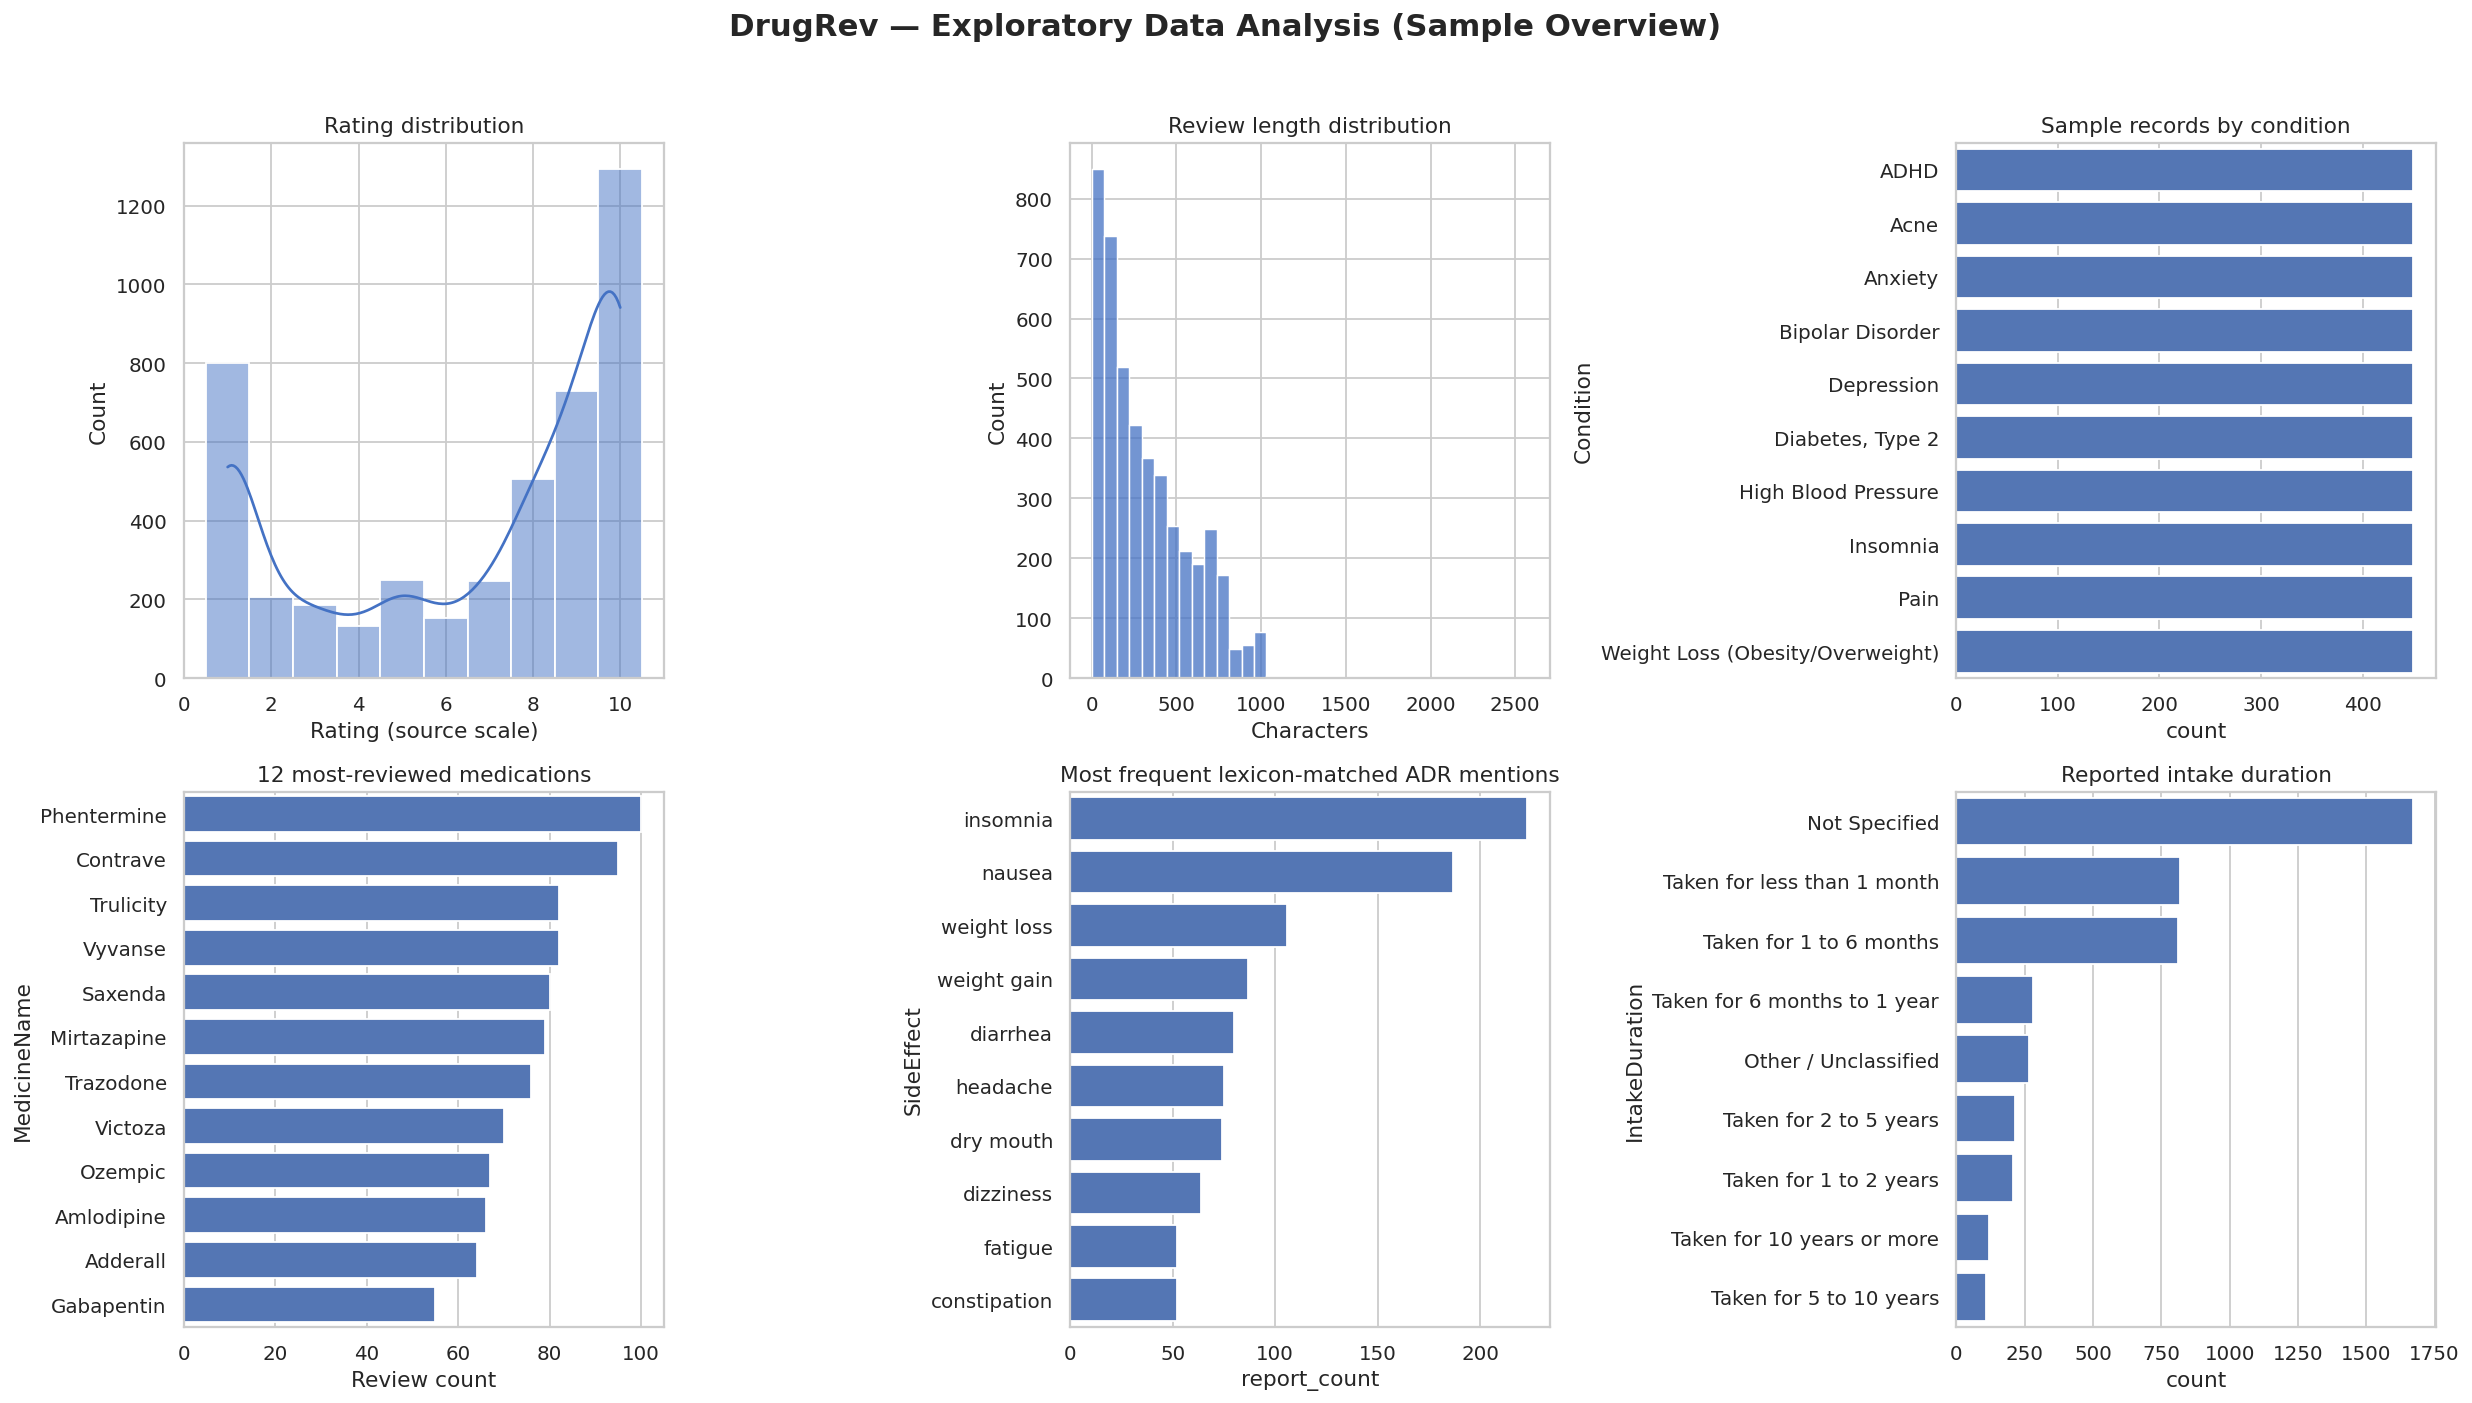

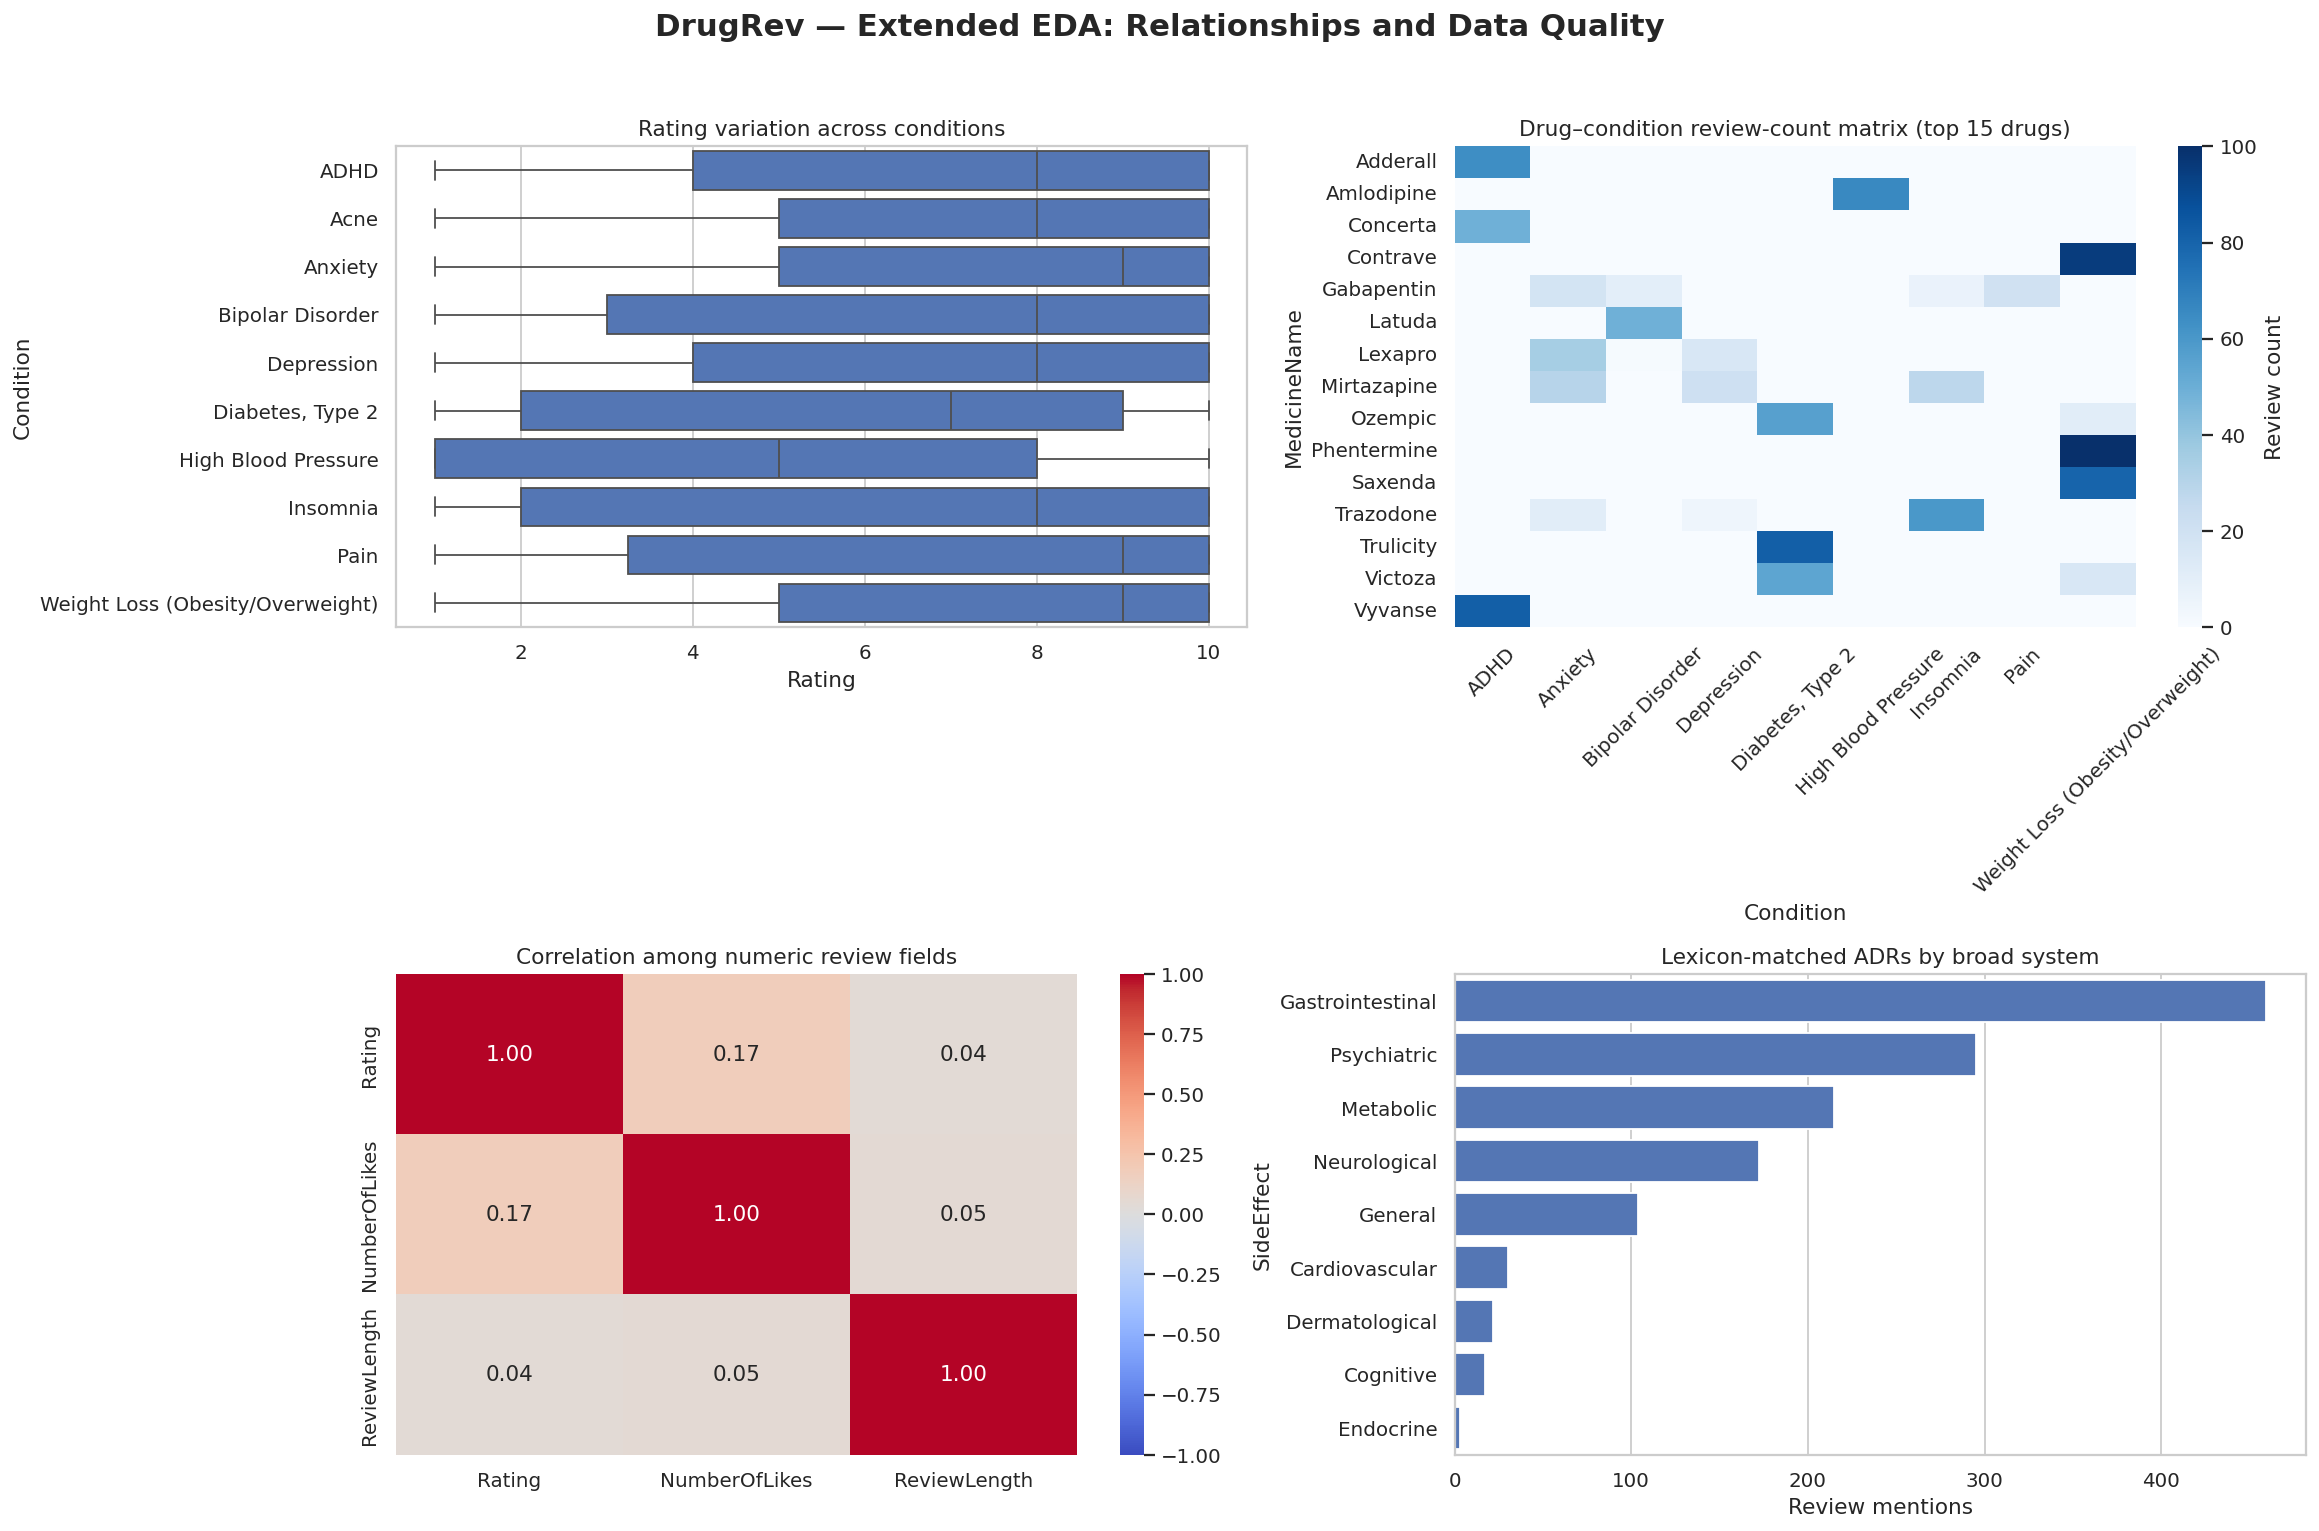

In [7]:
# Summary tables used to explain graph density and the benchmark design.
pair_stats = (df.groupby(["MedicineName","Condition"], as_index=False)
    .agg(avg_rating=("Rating","mean"), review_count=("ReviewId","nunique"),
         avg_likes=("NumberOfLikes","mean"), avg_review_length=("ReviewLength","mean")))
pair_stats["avg_rating"] = pair_stats["avg_rating"].round(3)

adr_long = df[["ReviewId","MedicineName","Condition","ExtractedADRs"]].explode("ExtractedADRs")
adr_long = adr_long.dropna(subset=["ExtractedADRs"]).rename(columns={"ExtractedADRs":"SideEffect"})
adr_stats = (adr_long.groupby("SideEffect", as_index=False)
    .agg(report_count=("ReviewId","nunique"), drug_count=("MedicineName","nunique"), condition_count=("Condition","nunique")))
adr_stats = adr_stats.sort_values("report_count", ascending=False)

condition_stats = (df.groupby("Condition", as_index=False)
    .agg(review_count=("ReviewId","nunique"), drug_count=("MedicineName","nunique"), avg_rating=("Rating","mean")))
condition_stats["avg_rating"] = condition_stats["avg_rating"].round(3)

drug_stats = (df.groupby("MedicineName", as_index=False)
    .agg(review_count=("ReviewId","nunique"), condition_count=("Condition","nunique"), avg_rating=("Rating","mean")))
drug_stats["avg_rating"] = drug_stats["avg_rating"].round(3)

fig, axes = plt.subplots(2,3,figsize=(19,11))
fig.suptitle("DrugRev — Exploratory Data Analysis (Sample Overview)", fontsize=17, fontweight="bold")
sns.histplot(df["Rating"], bins=np.arange(0.5,10.6,1), kde=True, ax=axes[0,0], color="#4472C4")
axes[0,0].set_title("Rating distribution"); axes[0,0].set_xlabel("Rating (source scale)")
sns.histplot(df["ReviewLength"], bins=35, ax=axes[0,1], color="#4472C4"); axes[0,1].set_title("Review length distribution"); axes[0,1].set_xlabel("Characters")
cond_order=df["Condition"].value_counts().index
sns.countplot(data=df,y="Condition",order=cond_order,ax=axes[0,2],color="#4472C4"); axes[0,2].set_title("Sample records by condition")
top_drugs=df["MedicineName"].value_counts().head(12)
sns.barplot(x=top_drugs.values,y=top_drugs.index,ax=axes[1,0],color="#4472C4"); axes[1,0].set_title("12 most-reviewed medications"); axes[1,0].set_xlabel("Review count")
if not adr_stats.empty:
    sns.barplot(data=adr_stats.head(10),x="report_count",y="SideEffect",ax=axes[1,1],color="#4472C4"); axes[1,1].set_title("Most frequent lexicon-matched ADR mentions")
intake_order=df["IntakeDuration"].value_counts().index
sns.countplot(data=df,y="IntakeDuration",order=intake_order,ax=axes[1,2],color="#4472C4"); axes[1,2].set_title("Reported intake duration")
plt.tight_layout(rect=[0,0,1,0.96]); plt.savefig(os.path.join(WORKING_DIR,"task1_eda.png"),bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(2,2,figsize=(18,12))
fig.suptitle("DrugRev — Extended EDA: Relationships and Data Quality", fontsize=17, fontweight="bold")
# Ratings by condition
sns.boxplot(data=df,x="Rating",y="Condition",order=cond_order,ax=axes[0,0],showfliers=False,color="#4472C4")
axes[0,0].set_title("Rating variation across conditions")
# Drug-condition sample density heatmap (top drugs only)
top_names=df["MedicineName"].value_counts().head(15).index
hm=df[df["MedicineName"].isin(top_names)].pivot_table(index="MedicineName",columns="Condition",values="ReviewId",aggfunc="count",fill_value=0)
sns.heatmap(hm, cmap="Blues", ax=axes[0,1], cbar_kws={"label":"Review count"})
axes[0,1].set_title("Drug–condition review-count matrix (top 15 drugs)"); axes[0,1].tick_params(axis="x",rotation=45)
# Numeric correlation
num=df[["Rating","NumberOfLikes","ReviewLength"]].corr(numeric_only=True)
sns.heatmap(num,annot=True,fmt=".2f",vmin=-1,vmax=1,cmap="coolwarm",ax=axes[1,0]); axes[1,0].set_title("Correlation among numeric review fields")
# ADR system counts
if not adr_long.empty:
    cat_counts=adr_long["SideEffect"].map(SE_CAT_MAP).value_counts()
    sns.barplot(x=cat_counts.values,y=cat_counts.index,ax=axes[1,1],color="#4472C4"); axes[1,1].set_title("Lexicon-matched ADRs by broad system"); axes[1,1].set_xlabel("Review mentions")
plt.tight_layout(rect=[0,0,1,0.96]); plt.savefig(os.path.join(WORKING_DIR,"task1_eda_extended.png"),bbox_inches="tight"); plt.show()

# Export analytical summaries for transparent downstream use.
pair_stats.to_csv(os.path.join(WORKING_DIR,"drug_condition_summary.csv"),index=False)
adr_stats.to_csv(os.path.join(WORKING_DIR,"adverse_reaction_summary.csv"),index=False)
condition_stats.to_csv(os.path.join(WORKING_DIR,"condition_summary.csv"),index=False)
drug_stats.to_csv(os.path.join(WORKING_DIR,"drug_summary.csv"),index=False)


## TASK 2 — Property-graph model design and Neo4j Aura

### 2.1 Graph design rationale

The graph represents medication, condition, patient-review, adverse-reaction, patient-pseudonym, and intake-duration entities. A `TREATS` relationship represents a medication-condition pair and stores pair-specific sample statistics. Review-level relationships preserve provenance, so a condition-specific adverse-reaction query can be traced through the same review rather than incorrectly combining unrelated conditions.

The global `CAUSES_SIDE_EFFECT` relationship is an **aggregate association in this review sample**, not evidence of clinical causality. Review-level `REPORTS_SIDE_EFFECT` relationships are used for condition-specific multi-hop retrieval.


### 2.2 Create a graph schema diagram and schema tables


,label,key,properties,rationale
0,AIML506Drug,"(project_id, name)","name, doc_id, summary, avg_rating, review_count",Represents a medication and its sample-level review profile.
1,AIML506Condition,"(project_id, name)","name, doc_id, summary, review_count, drug_count, avg_rating",Represents a condition associated with medication reviews.
2,AIML506Review,"(project_id, id)","id, rating, text, length, likes, source_row",Preserves the original review narrative and its provenance.
3,AIML506SideEffect,"(project_id, name)","name, category, doc_id, summary, report_count",Represents a lexicon-matched adverse-reaction mention.
4,AIML506Patient,"(project_id, patient_id)","patient_id (SHA-256 pseudonym), review_count",Connects reviews to pseudonymous source-user identifiers without loading usernames.
5,AIML506IntakeDuration,"(project_id, duration)","duration, doc_id, summary, review_count",Represents the reported duration of medication intake.


,type,direction,properties,cardinality,rationale
0,TREATS,Drug → Condition,"doc_id, summary, avg_rating, review_count",Many-to-many; one edge per drug-condition pair,Stores condition-specific medication review statistics.
1,REVIEWS_DRUG,Review → Drug,project_id,Many reviews to one drug,Links each review to the medication it discusses.
2,FOR_CONDITION,Review → Condition,project_id,Many reviews to one condition,Preserves the condition stated in the same review.
3,REPORTS_SIDE_EFFECT,Review → SideEffect,project_id,Many-to-many,Connects a review to each lexicon-matched adverse-reaction term.
4,CAUSES_SIDE_EFFECT,Drug → SideEffect,"report_count, frequency_pct, project_id",Many-to-many aggregate association,Summarizes mentions by medication; it is not a causal clinical claim.
5,POSTED,Patient → Review,project_id,One pseudonymous patient to many reviews,Preserves source-user linkage using a pseudonymous identifier.
6,HAS_INTAKE,Review → IntakeDuration,project_id,Many reviews to one duration category,Connects each review to its reported intake-duration category.


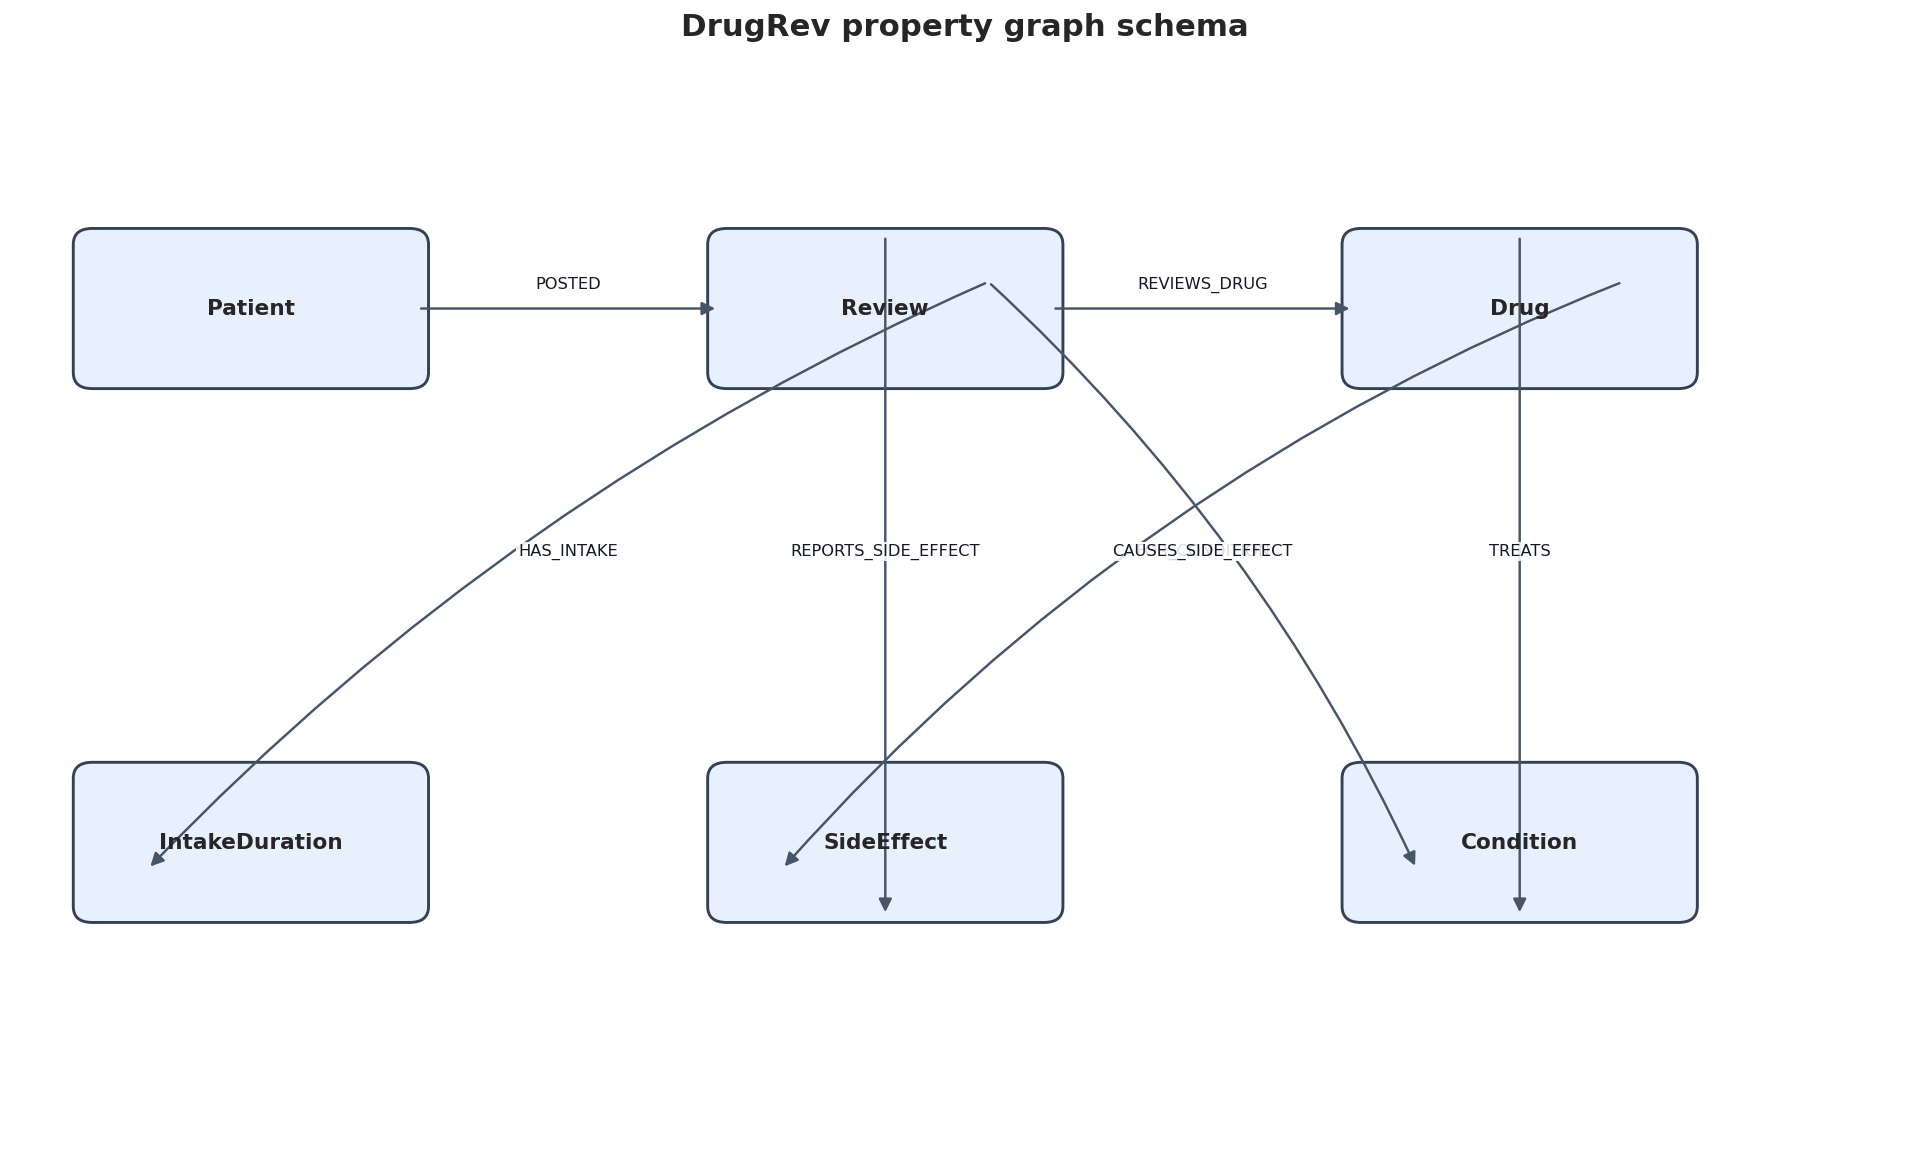

In [8]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

NODE_SCHEMA = [
    {"label":"AIML506Drug","key":"(project_id, name)","properties":"name, doc_id, summary, avg_rating, review_count","rationale":"Represents a medication and its sample-level review profile."},
    {"label":"AIML506Condition","key":"(project_id, name)","properties":"name, doc_id, summary, review_count, drug_count, avg_rating","rationale":"Represents a condition associated with medication reviews."},
    {"label":"AIML506Review","key":"(project_id, id)","properties":"id, rating, text, length, likes, source_row","rationale":"Preserves the original review narrative and its provenance."},
    {"label":"AIML506SideEffect","key":"(project_id, name)","properties":"name, category, doc_id, summary, report_count","rationale":"Represents a lexicon-matched adverse-reaction mention."},
    {"label":"AIML506Patient","key":"(project_id, patient_id)","properties":"patient_id (SHA-256 pseudonym), review_count","rationale":"Connects reviews to pseudonymous source-user identifiers without loading usernames."},
    {"label":"AIML506IntakeDuration","key":"(project_id, duration)","properties":"duration, doc_id, summary, review_count","rationale":"Represents the reported duration of medication intake."}
]
REL_SCHEMA = [
    {"type":"TREATS","direction":"Drug → Condition","properties":"doc_id, summary, avg_rating, review_count","cardinality":"Many-to-many; one edge per drug-condition pair","rationale":"Stores condition-specific medication review statistics."},
    {"type":"REVIEWS_DRUG","direction":"Review → Drug","properties":"project_id","cardinality":"Many reviews to one drug","rationale":"Links each review to the medication it discusses."},
    {"type":"FOR_CONDITION","direction":"Review → Condition","properties":"project_id","cardinality":"Many reviews to one condition","rationale":"Preserves the condition stated in the same review."},
    {"type":"REPORTS_SIDE_EFFECT","direction":"Review → SideEffect","properties":"project_id","cardinality":"Many-to-many","rationale":"Connects a review to each lexicon-matched adverse-reaction term."},
    {"type":"CAUSES_SIDE_EFFECT","direction":"Drug → SideEffect","properties":"report_count, frequency_pct, project_id","cardinality":"Many-to-many aggregate association","rationale":"Summarizes mentions by medication; it is not a causal clinical claim."},
    {"type":"POSTED","direction":"Patient → Review","properties":"project_id","cardinality":"One pseudonymous patient to many reviews","rationale":"Preserves source-user linkage using a pseudonymous identifier."},
    {"type":"HAS_INTAKE","direction":"Review → IntakeDuration","properties":"project_id","cardinality":"Many reviews to one duration category","rationale":"Connects each review to its reported intake-duration category."}
]

df_node_schema=pd.DataFrame(NODE_SCHEMA)
df_rel_schema=pd.DataFrame(REL_SCHEMA)
display(df_node_schema)
display(df_rel_schema)
df_node_schema.to_csv(os.path.join(WORKING_DIR,"graph_node_schema.csv"),index=False)
df_rel_schema.to_csv(os.path.join(WORKING_DIR,"graph_relationship_schema.csv"),index=False)

fig, ax = plt.subplots(figsize=(15,9)); ax.set_xlim(0,12); ax.set_ylim(0,8); ax.axis("off")
positions={"Patient":(1.5,6.2),"Review":(5.5,6.2),"Drug":(9.5,6.2),"Condition":(9.5,2.2),"SideEffect":(5.5,2.2),"IntakeDuration":(1.5,2.2)}
for label,(x,y) in positions.items():
    patch=FancyBboxPatch((x-1.0,y-0.48),2.0,0.96,boxstyle="round,pad=0.12",linewidth=1.6,edgecolor="#334155",facecolor="#e8f0fe")
    ax.add_patch(patch); ax.text(x,y,label,ha="center",va="center",fontsize=12,fontweight="bold")

def arrow(a,b,label,rad=0.0,offset=(0,0)):
    x1,y1=positions[a]; x2,y2=positions[b]
    ar=FancyArrowPatch((x1+offset[0],y1+offset[1]),(x2-offset[0],y2-offset[1]),arrowstyle="-|>",mutation_scale=15,linewidth=1.35,color="#475569",connectionstyle=f"arc3,rad={rad}")
    ax.add_patch(ar); mx=(x1+x2)/2; my=(y1+y2)/2
    ax.text(mx,my+0.18,label,ha="center",va="center",fontsize=9,color="#111827",bbox=dict(facecolor="white",edgecolor="none",alpha=.85,pad=1))
arrow("Patient","Review","POSTED",offset=(1.05,0))
arrow("Review","Drug","REVIEWS_DRUG",offset=(1.05,0))
arrow("Review","Condition","FOR_CONDITION",rad=-0.10,offset=(0.65,0.2))
arrow("Review","SideEffect","REPORTS_SIDE_EFFECT",offset=(0,0.55))
arrow("Review","IntakeDuration","HAS_INTAKE",rad=0.10,offset=(0.65,0.2))
arrow("Drug","Condition","TREATS",offset=(0,0.55))
arrow("Drug","SideEffect","CAUSES_SIDE_EFFECT",rad=0.12,offset=(0.65,0.2))
ax.set_title("DrugRev property graph schema",fontsize=17,fontweight="bold",pad=18)
plt.tight_layout(); plt.savefig(os.path.join(WORKING_DIR,"graph_schema.png"),bbox_inches="tight"); plt.show()


### 2.3 Neo4j Aura connection — credentials only from Kaggle Secrets

The connection cell intentionally has no hard-coded URI, username, password, or environment fallback. Add your rotated/new Aura credentials to Kaggle Secrets before running it. The database name defaults to `neo4j` unless you explicitly add `NEO4J_DATABASE`.

**Neo4j fix:** This version stores nodes under `AIML506Drug`, `AIML506Condition`, `AIML506Review`, `AIML506SideEffect`, `AIML506Patient`, and `AIML506IntakeDuration`, instead of generic labels that may have old uniqueness constraints. It uses the V3 project namespace and new index/constraint names; all queries are updated to use those labels. Rerunning deletes only project-scoped nodes with these six labels.


In [9]:
from neo4j import GraphDatabase

try:
    from kaggle_secrets import UserSecretsClient
except Exception as exc:
    raise RuntimeError("This notebook must be run in Kaggle. Add NEO4J_URI, NEO4J_USERNAME, and NEO4J_PASSWORD under Kaggle Add-ons → Secrets.") from exc

secret_client = UserSecretsClient()
def read_secret(name, required=True, default=None):
    try:
        value = secret_client.get_secret(name)
        if value is not None and str(value).strip():
            return str(value).strip()
    except Exception:
        pass
    if required:
        raise RuntimeError(f"Missing Kaggle Secret: {name}. Add it under Add-ons → Secrets, then rerun this cell.")
    return default

NEO4J_URI = read_secret("NEO4J_URI")
NEO4J_USERNAME = read_secret("NEO4J_USERNAME")
NEO4J_PASSWORD = read_secret("NEO4J_PASSWORD")
NEO4J_DATABASE = read_secret("NEO4J_DATABASE", required=False, default="neo4j")

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USERNAME, NEO4J_PASSWORD), connection_timeout=30)
driver.verify_connectivity()
print("Connected to Neo4j Aura. Database:", NEO4J_DATABASE)


Connected to Neo4j Aura. Database: d4296b49


### 2.4 Stable document IDs and summary records shared by both RAG systems


In [10]:
def stable_doc_id(prefix, *parts):
    payload="||".join(str(x).strip().lower() for x in parts)
    return prefix + "_" + hashlib.sha1(payload.encode("utf-8")).hexdigest()[:12].upper()

pair_stats = pair_stats.copy()
pair_stats["doc_id"] = pair_stats.apply(lambda r: stable_doc_id("PAIR",r["MedicineName"],r["Condition"]),axis=1)

drug_doc_records=[]
for drug, grp in df.groupby("MedicineName",sort=True):
    conds=sorted(grp["Condition"].unique().tolist())
    avg=float(grp["Rating"].mean())
    count=int(grp["ReviewId"].nunique())
    drug_doc_id=stable_doc_id("DRUG",drug)
    summary=f"Medication {drug}. In the selected DrugRev sample it has {count} reviews, average rating {avg:.2f}/10, and is reviewed for these conditions: {', '.join(conds)}. These are customer-reported review statistics, not clinical effectiveness estimates."
    drug_doc_records.append({"id":drug_doc_id,"text":summary,"metadata":{"doc_type":"drug_summary","drug":str(drug),"condition":"; ".join(conds)}})

condition_doc_records=[]
for _,r in condition_stats.iterrows():
    cond=str(r["Condition"]); doc_id=stable_doc_id("COND",cond)
    summary=f"Condition {cond}. In the selected DrugRev sample it appears in {int(r['review_count'])} reviews, across {int(r['drug_count'])} distinct medications, with average customer rating {float(r['avg_rating']):.2f}/10."
    condition_doc_records.append({"id":doc_id,"text":summary,"metadata":{"doc_type":"condition_summary","condition":cond}})

pair_doc_records=[]
for _,r in pair_stats.iterrows():
    drug=str(r["MedicineName"]); cond=str(r["Condition"])
    sub=df[(df["MedicineName"]==drug)&(df["Condition"]==cond)]
    mentions=Counter([x for arr in sub["ExtractedADRs"] for x in arr])
    top_terms=[f"{term} ({n} reviews)" for term,n in mentions.most_common(5)]
    adr_text="; ".join(top_terms) if top_terms else "No lexicon-matched adverse-reaction term was found in this pair's sampled reviews"
    summary=(f"Medication {drug} is reviewed for condition {cond}. In this selected sample there are {int(r['review_count'])} reviews, "
             f"average rating {float(r['avg_rating']):.2f}/10. Lexicon-matched adverse-reaction mentions for this drug-condition pair: {adr_text}. "
             "These are review mentions and do not establish causality.")
    pair_doc_records.append({"id":str(r["doc_id"]),"text":summary,"metadata":{"doc_type":"drug_condition_summary","drug":drug,"condition":cond}})

adr_doc_records=[]
for _,r in adr_stats.iterrows():
    se=str(r["SideEffect"]); doc_id=stable_doc_id("ADR",se)
    top_drugs=(adr_long[adr_long["SideEffect"]==se]["MedicineName"].value_counts().head(5))
    drug_text=", ".join([f"{name} ({int(n)})" for name,n in top_drugs.items()])
    summary=f"Adverse-reaction term {se} ({SE_CAT_MAP.get(se,'Unclassified')}) appears in {int(r['report_count'])} distinct sampled reviews and is associated with {int(r['drug_count'])} medications and {int(r['condition_count'])} conditions. Most frequent medication mentions: {drug_text}. This is lexical co-mention in customer reviews, not a causal safety estimate."
    adr_doc_records.append({"id":doc_id,"text":summary,"metadata":{"doc_type":"adverse_reaction_summary","side_effect":se}})

intake_counts=df["IntakeDuration"].value_counts()
intake_doc_records=[]
for duration,count in intake_counts.items():
    doc_id=stable_doc_id("INTAKE",duration)
    summary=f"Reported intake duration category: {duration}. It appears in {int(count)} reviews in the selected DrugRev sample."
    intake_doc_records.append({"id":doc_id,"text":summary,"metadata":{"doc_type":"intake_summary","intake_duration":str(duration)}})

review_doc_records=[]
for _,r in df.iterrows():
    text=str(r["Reviews"]).strip()
    if len(text)>3000: text=text[:3000]
    adr_text=", ".join(r["ExtractedADRs"]) if r["ExtractedADRs"] else "None lexicon-matched"
    doc=(f"Review ID {r['ReviewId']}. Medication: {r['MedicineName']}. Condition: {r['Condition']}. "
         f"Rating: {float(r['Rating']):.2f}/10. Intake duration: {r['IntakeDuration']}. "
         f"Lexicon-matched adverse-reaction mentions: {adr_text}. Patient review narrative: {text}")
    review_doc_records.append({"id":str(r["ReviewId"]),"text":doc,"metadata":{"doc_type":"review","drug":str(r["MedicineName"]),"condition":str(r["Condition"]),"review_id":str(r["ReviewId"])}})

ALL_DOC_RECORDS = drug_doc_records + condition_doc_records + pair_doc_records + adr_doc_records + intake_doc_records + review_doc_records
DOC_LOOKUP = {x["id"]:x for x in ALL_DOC_RECORDS}
print("Common evidence corpus size:",len(ALL_DOC_RECORDS))
print("Document types:",Counter(x["metadata"]["doc_type"] for x in ALL_DOC_RECORDS))


Common evidence corpus size: 5584
Document types: Counter({'review': 4500, 'drug_condition_summary': 568, 'drug_summary': 470, 'adverse_reaction_summary': 27, 'condition_summary': 10, 'intake_summary': 9})


### 2.5 Constraints, indexes, and project-scoped batched graph loading


In [11]:
# Re-running this notebook replaces only nodes in PROJECT_ID; unrelated Aura data is preserved.
constraint_statements = [
    "CREATE CONSTRAINT aiml506_drug_unique_v3 IF NOT EXISTS FOR (n:AIML506Drug) REQUIRE (n.project_id, n.name) IS UNIQUE",
    "CREATE CONSTRAINT aiml506_condition_unique_v3 IF NOT EXISTS FOR (n:AIML506Condition) REQUIRE (n.project_id, n.name) IS UNIQUE",
    "CREATE CONSTRAINT aiml506_review_unique_v3 IF NOT EXISTS FOR (n:AIML506Review) REQUIRE (n.project_id, n.id) IS UNIQUE",
    "CREATE CONSTRAINT aiml506_sideeffect_unique_v3 IF NOT EXISTS FOR (n:AIML506SideEffect) REQUIRE (n.project_id, n.name) IS UNIQUE",
    "CREATE CONSTRAINT aiml506_patient_unique_v3 IF NOT EXISTS FOR (n:AIML506Patient) REQUIRE (n.project_id, n.patient_id) IS UNIQUE",
    "CREATE CONSTRAINT aiml506_intake_unique_v3 IF NOT EXISTS FOR (n:AIML506IntakeDuration) REQUIRE (n.project_id, n.duration) IS UNIQUE"
]
index_statements = [
    "CREATE FULLTEXT INDEX aiml506_review_text_v3 IF NOT EXISTS FOR (r:AIML506Review) ON EACH [r.text]",
    "CREATE FULLTEXT INDEX aiml506_drug_summary_v3 IF NOT EXISTS FOR (d:AIML506Drug) ON EACH [d.summary]"
]

graph_build_start=time.perf_counter()
with driver.session(database=NEO4J_DATABASE) as session:
    for stmt in constraint_statements:
        session.run(stmt).consume()
    for stmt in index_statements:
        session.run(stmt).consume()
    session.run("CALL db.awaitIndexes(300)").consume()
    session.run("""
        MATCH (n)
        WHERE n.project_id=$project_id AND (
            n:AIML506Drug OR n:AIML506Condition OR n:AIML506Review OR
            n:AIML506SideEffect OR n:AIML506Patient OR n:AIML506IntakeDuration
        )
        DETACH DELETE n
        """, project_id=PROJECT_ID).consume()

    # Conditions - Ensure absolute uniqueness
    cond_records=[]
    seen_conds=set()
    for _,r in condition_stats.iterrows():
        cond=str(r["Condition"])
        if cond in seen_conds: continue
        seen_conds.add(cond)
        cond_records.append({"name":cond,"doc_id":stable_doc_id("COND",cond),"summary":DOC_LOOKUP[stable_doc_id("COND",cond)]["text"],
                             "review_count":int(r["review_count"]),"drug_count":int(r["drug_count"]),"avg_rating":float(r["avg_rating"])})
    session.run("UNWIND $rows AS row MERGE (c:AIML506Condition {project_id:$p,name:row.name}) SET c.doc_id=row.doc_id,c.summary=row.summary,c.review_count=row.review_count,c.drug_count=row.drug_count,c.avg_rating=row.avg_rating",p=PROJECT_ID,rows=cond_records).consume()

    # Side effects - Ensure absolute uniqueness
    se_records=[]
    seen_se=set()
    for _,r in adr_stats.iterrows():
        se=str(r["SideEffect"])
        if se in seen_se: continue
        seen_se.add(se)
        did=stable_doc_id("ADR",se)
        se_records.append({"name":se,"category":SE_CAT_MAP.get(se,"Unclassified"),"doc_id":did,"summary":DOC_LOOKUP[did]["text"],"report_count":int(r["report_count"])})
    session.run("UNWIND $rows AS row MERGE (s:AIML506SideEffect {project_id:$p,name:row.name}) SET s.category=row.category,s.doc_id=row.doc_id,s.summary=row.summary,s.report_count=row.report_count",p=PROJECT_ID,rows=se_records).consume()

    # Drugs - Ensure absolute uniqueness
    drug_records=[]
    seen_drugs=set()
    for _,r in drug_stats.iterrows():
        drug=str(r["MedicineName"])
        if drug in seen_drugs: continue
        seen_drugs.add(drug)
        did=stable_doc_id("DRUG",drug)
        drug_records.append({"name":drug,"doc_id":did,"summary":DOC_LOOKUP[did]["text"],"avg_rating":float(r["avg_rating"]),"review_count":int(r["review_count"])})
    session.run("UNWIND $rows AS row MERGE (d:AIML506Drug {project_id:$p,name:row.name}) SET d.doc_id=row.doc_id,d.summary=row.summary,d.avg_rating=row.avg_rating,d.review_count=row.review_count",p=PROJECT_ID,rows=drug_records).consume()

    # Intake duration nodes - Ensure absolute uniqueness
    intake_records=[]
    seen_intakes=set()
    for duration,count in intake_counts.items():
        dur_str=str(duration)
        if dur_str in seen_intakes: continue
        seen_intakes.add(dur_str)
        did=stable_doc_id("INTAKE",dur_str)
        intake_records.append({"duration":dur_str,"doc_id":did,"summary":DOC_LOOKUP[did]["text"],"review_count":int(count)})
    session.run("UNWIND $rows AS row MERGE (i:AIML506IntakeDuration {project_id:$p,duration:row.duration}) SET i.doc_id=row.doc_id,i.summary=row.summary,i.review_count=row.review_count",p=PROJECT_ID,rows=intake_records).consume()

    # Pseudonymous patients
    patient_counts=df.groupby("PatientID")["ReviewId"].nunique().to_dict()
    patient_records=[{"patient_id":str(pid),"review_count":int(cnt)} for pid,cnt in patient_counts.items()]
    for start in range(0,len(patient_records),500):
        session.run("UNWIND $rows AS row MERGE (p:AIML506Patient {project_id:$p,patient_id:row.patient_id}) SET p.review_count=row.review_count",p=PROJECT_ID,rows=patient_records[start:start+500]).consume()

    # Review nodes and provenance relationships in batches.
    review_records=[]
    for _,r in df.iterrows():
        review_records.append({"id":str(r["ReviewId"]),"patient_id":str(r["PatientID"]),"drug":str(r["MedicineName"]),
            "condition":str(r["Condition"]),"intake":str(r["IntakeDuration"]),"rating":float(r["Rating"]),
            "text":str(r["Reviews"])[:3000],"length":int(r["ReviewLength"]),"likes":int(r["NumberOfLikes"]),
            "adrs":list(r["ExtractedADRs"]),"source_row":int(r["_source_row"])})
    for start in range(0,len(review_records),250):
        batch=review_records[start:start+250]
        session.run("""
        UNWIND $rows AS row
        MERGE (p:AIML506Patient {project_id:$p,patient_id:row.patient_id})
        MERGE (d:AIML506Drug {project_id:$p,name:row.drug})
        MERGE (c:AIML506Condition {project_id:$p,name:row.condition})
        MERGE (i:AIML506IntakeDuration {project_id:$p,duration:row.intake})
        MERGE (r:AIML506Review {project_id:$p,id:row.id})
        SET r.rating=row.rating,r.text=row.text,r.length=row.length,r.likes=row.likes,r.source_row=row.source_row
        MERGE (p)-[:POSTED {project_id:$p}]->(r)
        MERGE (r)-[:REVIEWS_DRUG {project_id:$p}]->(d)
        MERGE (r)-[:FOR_CONDITION {project_id:$p}]->(c)
        MERGE (r)-[:HAS_INTAKE {project_id:$p}]->(i)
        FOREACH (se_name IN row.adrs |
            MERGE (s:AIML506SideEffect {project_id:$p,name:se_name})
            MERGE (r)-[:REPORTS_SIDE_EFFECT {project_id:$p}]->(s)
        )
        """,p=PROJECT_ID,rows=batch).consume()

    # Pair-specific Drug -> Condition aggregate relationships.
    pair_records=[]
    for _,r in pair_stats.iterrows():
        pair_records.append({"drug":str(r["MedicineName"]),"condition":str(r["Condition"]),"doc_id":str(r["doc_id"]),
            "summary":DOC_LOOKUP[str(r["doc_id"])]["text"],"avg_rating":float(r["avg_rating"]),"review_count":int(r["review_count"]),
            "key":stable_doc_id("TREATS",r["MedicineName"],r["Condition"])})
    for start in range(0,len(pair_records),500):
        session.run("""
        UNWIND $rows AS row
        MATCH (d:AIML506Drug {project_id:$p,name:row.drug})
        MATCH (c:AIML506Condition {project_id:$p,name:row.condition})
        MERGE (d)-[t:TREATS {project_id:$p,key:row.key}]->(c)
        SET t.doc_id=row.doc_id,t.summary=row.summary,t.avg_rating=row.avg_rating,t.review_count=row.review_count
        """,p=PROJECT_ID,rows=pair_records[start:start+500]).consume()

    # Aggregate drug-side-effect edges; explicitly labelled as review co-mentions.
    drug_adr=(adr_long.groupby(["MedicineName","SideEffect"],as_index=False)
              .agg(report_count=("ReviewId","nunique")))
    total_by_drug=df.groupby("MedicineName")["ReviewId"].nunique().to_dict()
    adr_edge_records=[]
    for _,r in drug_adr.iterrows():
        drug=str(r["MedicineName"]); se=str(r["SideEffect"]); count=int(r["report_count"])
        adr_edge_records.append({"drug":drug,"side_effect":se,"report_count":count,
            "frequency_pct":round(100*count/max(1,int(total_by_drug.get(drug,1))),2),"key":stable_doc_id("CAUSES",drug,se)})
    for start in range(0,len(adr_edge_records),500):
        session.run("""
        UNWIND $rows AS row
        MATCH (d:AIML506Drug {project_id:$p,name:row.drug})
        MATCH (s:AIML506SideEffect {project_id:$p,name:row.side_effect})
        MERGE (d)-[a:CAUSES_SIDE_EFFECT {project_id:$p,key:row.key}]->(s)
        SET a.report_count=row.report_count,a.frequency_pct=row.frequency_pct
        """,p=PROJECT_ID,rows=adr_edge_records[start:start+500]).consume()

graph_build_time=time.perf_counter()-graph_build_start
print(f"Graph rebuild completed in {graph_build_time:.2f} seconds.")

Graph rebuild completed in 12.81 seconds.


### 2.6 Verify graph counts and run five exploratory Cypher queries


In [12]:
with driver.session(database=NEO4J_DATABASE) as session:
    node_rows=session.run("MATCH (n) WHERE n.project_id=$p UNWIND labels(n) AS label RETURN label,count(n) AS count ORDER BY label",p=PROJECT_ID).data()
    rel_rows=session.run("MATCH ()-[r]->() WHERE r.project_id=$p RETURN type(r) AS relationship,count(r) AS count ORDER BY relationship",p=PROJECT_ID).data()

df_node_counts=pd.DataFrame(node_rows); df_rel_counts=pd.DataFrame(rel_rows)
display(df_node_counts); display(df_rel_counts)
df_node_counts.to_csv(os.path.join(WORKING_DIR,"neo4j_node_counts.csv"),index=False)
df_rel_counts.to_csv(os.path.join(WORKING_DIR,"neo4j_relationship_counts.csv"),index=False)

exploratory_queries = [
    ("Top-rated medication-condition pairs", "MATCH (d:AIML506Drug {project_id:$p})-[t:TREATS {project_id:$p}]->(c:AIML506Condition {project_id:$p}) WHERE t.review_count >= 5 RETURN d.name AS drug,c.name AS condition,t.avg_rating AS avg_rating,t.review_count AS reviews ORDER BY avg_rating DESC LIMIT 5"),
    ("Medication-condition pairs with insomnia mentions", "MATCH (d:AIML506Drug {project_id:$p})-[t:TREATS {project_id:$p}]->(c:AIML506Condition {project_id:$p}) MATCH (r:AIML506Review {project_id:$p})-[:REVIEWS_DRUG]->(d) MATCH (r)-[:FOR_CONDITION]->(c) MATCH (r)-[:REPORTS_SIDE_EFFECT]->(:AIML506SideEffect {project_id:$p,name:'insomnia'}) RETURN d.name AS drug,c.name AS condition,count(DISTINCT r) AS insomnia_reviews ORDER BY insomnia_reviews DESC LIMIT 5"),
    ("Medications reviewed for both Depression and Anxiety", "MATCH (d:AIML506Drug {project_id:$p})-[:TREATS {project_id:$p}]->(:AIML506Condition {project_id:$p,name:'Depression'}),(d)-[:TREATS {project_id:$p}]->(:AIML506Condition {project_id:$p,name:'Anxiety'}) RETURN d.name AS shared_drug,d.review_count AS total_reviews ORDER BY total_reviews DESC LIMIT 5"),
    ("Most frequent lexicon-matched adverse reactions", "MATCH (s:AIML506SideEffect {project_id:$p}) RETURN s.name AS adverse_reaction,s.category AS category,s.report_count AS review_mentions ORDER BY review_mentions DESC LIMIT 5"),
    ("Review provenance for a high-volume condition", "MATCH (r:AIML506Review {project_id:$p})-[:FOR_CONDITION]->(c:AIML506Condition {project_id:$p}) RETURN c.name AS condition,count(r) AS reviews,count(DISTINCT r.id) AS distinct_review_ids ORDER BY reviews DESC LIMIT 5")
]
query_outputs=[]
with driver.session(database=NEO4J_DATABASE) as session:
    for title,query in exploratory_queries:
        rows=session.run(query,p=PROJECT_ID).data()
        print("\n",title); display(pd.DataFrame(rows))
        query_outputs.append({"query_title":title,"cypher":query,"output_json":json.dumps(rows,ensure_ascii=False)})
pd.DataFrame(query_outputs).to_csv(os.path.join(WORKING_DIR,"exploratory_cypher_queries.csv"),index=False)


,label,count
0,AIML506Condition,10
1,AIML506Drug,470
2,AIML506IntakeDuration,9
3,AIML506Patient,3395
4,AIML506Review,4500
5,AIML506SideEffect,27


,relationship,count
0,CAUSES_SIDE_EFFECT,714
1,FOR_CONDITION,4500
2,HAS_INTAKE,4500
3,POSTED,4500
4,REPORTS_SIDE_EFFECT,1317
5,REVIEWS_DRUG,4500
6,TREATS,568



 Top-rated medication-condition pairs


,drug,condition,avg_rating,reviews
0,Flurazepam,Insomnia,10.000,6
1,Valium,Anxiety,9.800,10
2,Mounjaro,Weight Loss (Obesity/Overweight),9.625,8
3,Tazorac,Acne,9.600,5
4,Lortab,Pain,9.500,6



 Medication-condition pairs with insomnia mentions


,drug,condition,insomnia_reviews
0,Trazodone,Insomnia,25
1,Mirtazapine,Insomnia,16
2,Ambien,Insomnia,10
3,Belsomra,Insomnia,8
4,Amitriptyline,Insomnia,8


... (2 outputs left out)


 Most frequent lexicon-matched adverse reactions


,adverse_reaction,category,review_mentions
0,insomnia,Psychiatric,223
1,nausea,Gastrointestinal,187
2,weight loss,Metabolic,106
3,weight gain,Metabolic,87
4,diarrhea,Gastrointestinal,80



 Review provenance for a high-volume condition


,condition,reviews,distinct_review_ids
0,Acne,450,450
1,Anxiety,450,450
2,Bipolar Disorder,450,450
3,Depression,450,450
4,ADHD,450,450


## TASK 3 and TASK 4 — GraphRAG and Vector RAG pipelines

### 3.1 Shared evidence representation

To make retrieval evaluation comparable, both systems are built from the same sampled records and the same serialized evidence corpus. Stable IDs identify medication summaries (`DRUG_*`), medication-condition summaries (`PAIR_*`), condition summaries (`COND_*`), adverse-reaction summaries (`ADR_*`), intake-duration summaries (`INTAKE_*`), and source review records (`REV_*`). GraphRAG retrieves these facts through Neo4j nodes/relationships and review provenance; Vector RAG retrieves the same evidence documents through dense similarity search.

### 4.1 Vector store and embedding configuration

- **Vector store:** ChromaDB persistent collection. ChromaDB is selected because it supports local persistence, metadata storage, and straightforward reproducible indexing in a Kaggle notebook without a separately managed vector server.
- **Embedding model:** ChromaDB default ONNX MiniLM-L6-v2 embedding function (384-dimensional embeddings). Its compact sentence embeddings provide semantic matching while keeping the embedding footprint and inference cost manageable in the notebook environment.
- **Similarity metric:** cosine distance, a standard measure for comparing semantic embedding directions.
- **Retrieval depth:** top-5 documents. A fixed top-k makes the comparison reproducible and limits evidence/context size and query overhead.
- **Document serialization:** drug, drug-condition, condition, adverse-reaction, intake-duration summaries plus individual review narratives. This preserves structured facts as readable records while retaining the original free-text review evidence.


### 4.2 Build the ChromaDB index


In [13]:
import chromadb
from chromadb.utils import embedding_functions

CHROMA_PATH=os.path.join(WORKING_DIR,"chroma_db")
chroma_client=chromadb.PersistentClient(path=CHROMA_PATH)
COLLECTION_NAME="drugrev_shared_evidence_v3"
try:
    chroma_client.delete_collection(COLLECTION_NAME)
except Exception:
    pass
embedding_function=embedding_functions.DefaultEmbeddingFunction()
collection=chroma_client.create_collection(name=COLLECTION_NAME,embedding_function=embedding_function,metadata={"hnsw:space":"cosine","embedding_model":"all-MiniLM-L6-v2","embedding_dimension":384})

vector_index_start=time.perf_counter()
BATCH_SIZE=128
for start in range(0,len(ALL_DOC_RECORDS),BATCH_SIZE):
    batch=ALL_DOC_RECORDS[start:start+BATCH_SIZE]
    collection.add(ids=[x["id"] for x in batch],documents=[x["text"] for x in batch],metadatas=[x["metadata"] for x in batch])
vector_indexing_time=time.perf_counter()-vector_index_start
print("Chroma documents:",collection.count())
print(f"Vector indexing time: {vector_indexing_time:.2f} seconds")


Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given
/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:00<00:00, 103MiB/s]
Failed to send telemetry event CollectionAddEvent: capture() takes 1 positional argument but 3 were given


Chroma documents: 5584
Vector indexing time: 292.90 seconds


## 3.2 Entity linking, query routing, and graph retrieval

Entity linking uses exact, case-insensitive matches against entities in the sampled graph. The benchmark includes gold entity mentions so that entity-linking precision, recall, and F1 are computed rather than hard-coded. Query templates cover single-hop lookups, condition-specific medication/adverse-reaction paths, semantic review retrieval, and graph aggregation.


In [14]:
KNOWN_DRUGS=sorted(df["MedicineName"].dropna().unique().tolist(),key=len,reverse=True)
KNOWN_CONDITIONS=sorted(df["Condition"].dropna().unique().tolist(),key=len,reverse=True)
KNOWN_ADRS=sorted(SE_CAT_MAP.keys(),key=len,reverse=True)

CONDITION_ALIASES={
    "type 2 diabetes":"Diabetes, Type 2","diabetes":"Diabetes, Type 2",
    "hypertension":"High Blood Pressure","obesity":"Weight Loss (Obesity/Overweight)",
    "overweight":"Weight Loss (Obesity/Overweight)","weight loss":"Weight Loss (Obesity/Overweight)"
}

def find_mentions(question, candidates):
    q=question.lower(); found=[]
    for item in candidates:
        pattern=r"(?<!\w)"+re.escape(str(item).lower())+r"(?!\w)"
        if re.search(pattern,q): found.append(item)
    return list(dict.fromkeys(found))

def link_entities(question):
    q=question.lower()
    drugs=find_mentions(question,KNOWN_DRUGS)
    conditions=find_mentions(question,KNOWN_CONDITIONS)
    for alias,canonical in CONDITION_ALIASES.items():
        if alias in q and canonical in KNOWN_CONDITIONS and canonical not in conditions:
            conditions.append(canonical)

    # Prefer the clause that explicitly names the adverse-reaction term. This prevents
    # "Insomnia" or "Weight Loss" in a condition name from being mistaken for an ADR.
    adr_clause=q
    explicit_adr_context=False
    for cue in ["mentioning", "reports of", "reported ", "reporting ", "side effect", "adverse reaction", "adverse-reaction"]:
        if cue in q:
            adr_clause=q.split(cue,1)[1]
            explicit_adr_context=True
            break
    side_effects=find_mentions(adr_clause,KNOWN_ADRS)
    norm_key=lambda x: re.sub(r"\s+"," ",re.sub(r"[^a-z0-9]+"," ",str(x).lower())).strip()
    if explicit_adr_context:
        side_effect_norm={norm_key(x) for x in side_effects}
        conditions=[x for x in conditions if not any(se in norm_key(x) or norm_key(x) in se for se in side_effect_norm)]
    else:
        condition_norm=[norm_key(x) for x in conditions]
        side_effects=[x for x in side_effects if not any(norm_key(x) in cond or cond in norm_key(x) for cond in condition_norm)]
    return {"drugs":drugs,"conditions":conditions,"side_effects":side_effects}

OUT_OF_SCOPE_PATTERNS=[
    r"molecular weight",r"chemical synthesis",r"binding affinity",r"serotonin transporter",
    r"fda-approved",r"pediatric dosage",r"dosage schedule",r"commercial patent",r"patent owner",
    r"hazard ratio",r"phase\s*iii",r"p-value",r"pharmacopeia",r"contraindications",
    r"wholesale acquisition cost",r"copay coupon",r"manufacturer coupon"
]

def is_out_of_scope(question):
    q=question.lower()
    return any(re.search(p,q) for p in OUT_OF_SCOPE_PATTERNS)

def infer_intent(question, linked):
    q=question.lower()
    if is_out_of_scope(question): return "unanswerable"
    if any(x in q for x in ["describe", "what does a patient review say", "what do patients say", "patient narrative", "experience described"]):
        return "semantic"
    if linked["conditions"] and linked["side_effects"]:
        return "multi_hop"
    if any(x in q for x in ["top 3", "top three", "highest-rated", "highest rated", "most frequently", "most common", "largest number", "greatest number", "most-reviewed", "most reviewed"]):
        return "aggregation"
    if any(x in q for x in ["most common intake", "intake duration"]): return "aggregation"
    if linked["drugs"] or linked["conditions"]: return "single_hop"
    return "generic"

def graph_retrieve(question, session, top_k=TOP_K):
    t0=time.perf_counter()
    linked=link_entities(question)
    intent=infer_intent(question,linked)
    if intent=="unanswerable":
        return {"docs":[],"linked":linked,"intent":intent,"latency":time.perf_counter()-t0}
    rows=[]
    params={"p":PROJECT_ID,"k":top_k}
    if intent=="multi_hop" and linked["conditions"] and linked["side_effects"]:
        params.update({"cond":linked["conditions"][0],"se":linked["side_effects"][0]})
        rows=session.run("""
            MATCH (r:AIML506Review {project_id:$p})-[:FOR_CONDITION]->(c:AIML506Condition {project_id:$p,name:$cond})
            MATCH (r)-[:REVIEWS_DRUG]->(d:AIML506Drug {project_id:$p})
            MATCH (r)-[:REPORTS_SIDE_EFFECT]->(s:AIML506SideEffect {project_id:$p,name:$se})
            WITH d,c,count(DISTINCT r) AS reports
            MATCH (d)-[t:TREATS {project_id:$p}]->(c)
            RETURN t.doc_id AS id,t.summary AS text,'drug_condition_summary' AS doc_type,d.name AS drug,c.name AS condition,reports
            ORDER BY reports DESC,t.review_count DESC LIMIT $k
        """,**params).data()
    elif intent=="semantic":
        if linked["drugs"] and linked["conditions"]:
            params.update({"drug":linked["drugs"][0],"cond":linked["conditions"][0]})
            rows=session.run("""
                MATCH (r:AIML506Review {project_id:$p})-[:REVIEWS_DRUG]->(:AIML506Drug {project_id:$p,name:$drug})
                MATCH (r)-[:FOR_CONDITION]->(:AIML506Condition {project_id:$p,name:$cond})
                RETURN r.id AS id,('Review ID '+r.id+'. Rating '+toString(r.rating)+'. '+r.text) AS text,'review' AS doc_type,$drug AS drug,$cond AS condition
                ORDER BY r.likes DESC,r.length DESC LIMIT $k
            """,**params).data()
        elif linked["drugs"]:
            params["drug"]=linked["drugs"][0]
            rows=session.run("""
                MATCH (r:AIML506Review {project_id:$p})-[:REVIEWS_DRUG]->(:AIML506Drug {project_id:$p,name:$drug})
                RETURN r.id AS id,('Review ID '+r.id+'. Rating '+toString(r.rating)+'. '+r.text) AS text,'review' AS doc_type,$drug AS drug
                ORDER BY r.likes DESC,r.length DESC LIMIT $k
            """,**params).data()
        elif linked["conditions"]:
            params["cond"]=linked["conditions"][0]
            rows=session.run("""
                MATCH (r:AIML506Review {project_id:$p})-[:FOR_CONDITION]->(:AIML506Condition {project_id:$p,name:$cond})
                RETURN r.id AS id,('Review ID '+r.id+'. Rating '+toString(r.rating)+'. '+r.text) AS text,'review' AS doc_type,r.id AS review_id,$cond AS condition
                ORDER BY r.likes DESC,r.length DESC LIMIT $k
            """,**params).data()
    elif intent=="aggregation":
        qlow=question.lower()
        if "intake" in qlow or "duration" in qlow:
            rows=session.run("MATCH (i:AIML506IntakeDuration {project_id:$p}) RETURN i.doc_id AS id,i.summary AS text,'intake_summary' AS doc_type,i.duration AS intake_duration ORDER BY i.review_count DESC LIMIT $k",p=PROJECT_ID,k=top_k).data()
        elif "adverse" in qlow or "side effect" in qlow or "reaction" in qlow:
            rows=session.run("MATCH (s:AIML506SideEffect {project_id:$p}) RETURN s.doc_id AS id,s.summary AS text,'adverse_reaction_summary' AS doc_type,s.name AS side_effect ORDER BY s.report_count DESC LIMIT $k",p=PROJECT_ID,k=top_k).data()
        elif "top" in qlow or "highest" in qlow or "rated" in qlow:
            if linked["conditions"]:
                params["cond"]=linked["conditions"][0]
                rows=session.run("MATCH (d:AIML506Drug {project_id:$p})-[t:TREATS {project_id:$p}]->(c:AIML506Condition {project_id:$p,name:$cond}) WHERE t.review_count>=5 RETURN t.doc_id AS id,t.summary AS text,'drug_condition_summary' AS doc_type,d.name AS drug,c.name AS condition ORDER BY t.avg_rating DESC LIMIT $k",**params).data()
            else:
                rows=session.run("MATCH (d:AIML506Drug {project_id:$p})-[t:TREATS {project_id:$p}]->(c:AIML506Condition {project_id:$p}) WHERE t.review_count>=5 RETURN t.doc_id AS id,t.summary AS text,'drug_condition_summary' AS doc_type,d.name AS drug,c.name AS condition ORDER BY t.avg_rating DESC LIMIT $k",p=PROJECT_ID,k=top_k).data()
        elif "distinct medication" in qlow or "distinct drug" in qlow:
            rows=session.run("MATCH (c:AIML506Condition {project_id:$p}) RETURN c.doc_id AS id,c.summary AS text,'condition_summary' AS doc_type,c.name AS condition ORDER BY c.drug_count DESC LIMIT $k",p=PROJECT_ID,k=top_k).data()
        elif "condition" in qlow:
            rows=session.run("MATCH (c:AIML506Condition {project_id:$p}) RETURN c.doc_id AS id,c.summary AS text,'condition_summary' AS doc_type,c.name AS condition ORDER BY c.review_count DESC LIMIT $k",p=PROJECT_ID,k=top_k).data()
        elif "medication" in qlow or "drug" in qlow:
            rows=session.run("MATCH (d:AIML506Drug {project_id:$p}) RETURN d.doc_id AS id,d.summary AS text,'drug_summary' AS doc_type,d.name AS drug ORDER BY d.review_count DESC LIMIT $k",p=PROJECT_ID,k=top_k).data()
    elif intent=="single_hop":
        if linked["drugs"] and linked["conditions"]:
            params.update({"drug":linked["drugs"][0],"cond":linked["conditions"][0]})
            rows=session.run("MATCH (d:AIML506Drug {project_id:$p,name:$drug})-[t:TREATS {project_id:$p}]->(c:AIML506Condition {project_id:$p,name:$cond}) RETURN t.doc_id AS id,t.summary AS text,'drug_condition_summary' AS doc_type,d.name AS drug,c.name AS condition,t.avg_rating AS avg_rating,t.review_count AS review_count LIMIT $k",**params).data()
        elif linked["drugs"]:
            params["drug"]=linked["drugs"][0]
            rows=session.run("MATCH (d:AIML506Drug {project_id:$p,name:$drug})-[t:TREATS {project_id:$p}]->(c:AIML506Condition {project_id:$p}) RETURN t.doc_id AS id,t.summary AS text,'drug_condition_summary' AS doc_type,d.name AS drug,c.name AS condition ORDER BY t.review_count DESC LIMIT $k",**params).data()
        elif linked["conditions"]:
            params["cond"]=linked["conditions"][0]
            rows=session.run("MATCH (c:AIML506Condition {project_id:$p,name:$cond}) RETURN c.doc_id AS id,c.summary AS text,'condition_summary' AS doc_type,c.name AS condition LIMIT $k",**params).data()
    if not rows:
        # Full-text fallback preserves graph retrieval when no explicit entity route is found.
        # Lucene special characters in the original question may cause a syntax error.
        # A token-only query is safe for Neo4j full-text search.
        safe_query=" OR ".join(re.findall(r"[A-Za-z][A-Za-z0-9]{2,}",question))[:700]
        if safe_query:
            rows=session.run("""
                CALL db.index.fulltext.queryNodes('aiml506_review_text_v3',$query) YIELD node,score
                WHERE node.project_id=$p
                RETURN node.id AS id,('Review ID '+node.id+'. '+node.text) AS text,'review' AS doc_type,score
                ORDER BY score DESC LIMIT $k
            """,p=PROJECT_ID,query=safe_query,k=top_k).data()
    docs=[]
    for r in rows:
        if r.get("id") and r.get("text"):
            docs.append({"id":str(r["id"]),"text":str(r["text"]),"metadata":{k:v for k,v in r.items() if k not in {"id","text"} and v is not None}})
    return {"docs":docs[:top_k],"linked":linked,"intent":intent,"latency":time.perf_counter()-t0}

def vector_retrieve(question, top_k=TOP_K):
    t0=time.perf_counter()
    if is_out_of_scope(question):
        return {"docs":[],"latency":time.perf_counter()-t0,"distances":[]}
    result=collection.query(query_texts=[question],n_results=top_k,include=["documents","metadatas","distances"])
    ids=result["ids"][0] if result.get("ids") else []
    texts=result["documents"][0] if result.get("documents") else []
    metas=result["metadatas"][0] if result.get("metadatas") else []
    distances=result["distances"][0] if result.get("distances") else []
    docs=[{"id":str(i),"text":str(t),"metadata":m or {}} for i,t,m in zip(ids,texts,metas)]
    return {"docs":docs,"latency":time.perf_counter()-t0,"distances":distances}

print("Entity linker and both retrieval functions are ready.")


Entity linker and both retrieval functions are ready.


## TASK 5 — LLM selection, configuration, and grounded generation

### 5.1 Main generator and ablation configuration

The primary generator is **Mistral 7B Instruct v0.3**. It is instruction-tuned and provides a practical quality/resource balance for a local 7B model. The three additional models are Qwen 2.5 7B Instruct, Zephyr 7B Beta, and Phi-3.5 Mini Instruct; they provide different model families and a smaller-parameter comparison. All are loaded sequentially with 4-bit NF4 quantization to limit GPU memory use on a Kaggle T4-class GPU. The independent correctness/grounding judge is Qwen 2.5 7B, which differs from the main Mistral generator. It is a different model family but the same nominal parameter size; a larger judge is preferable under the assignment guidance, but this configuration avoids adding a fifth large model to the Kaggle runtime.

**Generation settings:** temperature 0; deterministic greedy decoding (`do_sample=False`); maximum 160 new tokens; input limit 3,072 tokens; common evidence context budget 1,800 tokens; top-k 5. The same primary generator and prompt are used for both systems in the main comparison.

### 5.2 Grounding and medical-safety prompt

The model must answer only from retrieved evidence, distinguish patient reports from clinical causality, state when the dataset does not contain the requested information, and cite evidence IDs. The notebook never treats a patient review or lexicon match as proof that a medication caused an adverse event.


### 5.3 Load quantized models and define generation

**Runtime fix:** `MAX_CONTEXT_TOKENS` is explicitly defined (1,800) and distinct from the total prompt limit (3,072), preventing the original undefined-variable error during RAG generation.


In [15]:
import torch
import jinja2
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

if not torch.cuda.is_available():
    raise RuntimeError("A CUDA GPU is required for the 4-bit model configuration. In Kaggle Settings, select a GPU accelerator and rerun all.")
print("GPU:",torch.cuda.get_device_name(0))

MODEL_REGISTRY={
    "mistral_v03": {"name":"Mistral 7B Instruct v0.3","repo":"mistralai/Mistral-7B-Instruct-v0.3","family":"Mistral AI","parameters":"7B","role":"Primary generator"},
    "qwen25_7b": {"name":"Qwen 2.5 7B Instruct","repo":"Qwen/Qwen2.5-7B-Instruct","family":"Alibaba Cloud","parameters":"7B","role":"Ablation + independent LLM judge"},
    "zephyr_7b": {"name":"Zephyr 7B Beta","repo":"HuggingFaceH4/zephyr-7b-beta","family":"Hugging Face H4 / Mistral-based","parameters":"7B","role":"Ablation"},
    "phi35_mini": {"name":"Phi-3.5 Mini Instruct","repo":"microsoft/Phi-3.5-mini-instruct","family":"Microsoft","parameters":"3.8B","role":"Ablation"}
}

def load_local_model(model_key):
    meta=MODEL_REGISTRY[model_key]
    print(f"Loading {meta['name']} ({meta['repo']}) in 4-bit NF4 mode...")
    trust_remote=(model_key=="phi35_mini")
    model_cache=os.path.join(HF_CACHE_ROOT,model_key)
    os.makedirs(model_cache,exist_ok=True)
    tokenizer=AutoTokenizer.from_pretrained(meta["repo"],use_fast=True,trust_remote_code=trust_remote,cache_dir=model_cache)
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token=tokenizer.eos_token
    tokenizer.padding_side="left"
    quant_config=BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True
    )
    model=AutoModelForCausalLM.from_pretrained(
        meta["repo"],
        quantization_config=quant_config,
        device_map="auto",
        torch_dtype=torch.float16,
        low_cpu_mem_usage=True,
        trust_remote_code=trust_remote,
        cache_dir=model_cache
    )
    model.eval()
    return tokenizer,model

def cleanup_model_cache(model_key):
    path=os.path.join(HF_CACHE_ROOT,model_key)
    if os.path.isdir(path):
        shutil.rmtree(path,ignore_errors=True)
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

SYSTEM_PROMPT=(
    "You are a careful research assistant analyzing the DrugRev customer-review dataset. "
    "Answer ONLY from the supplied evidence. Do not use outside medical knowledge. "
    "Do not provide diagnosis, prescribing, dosage, or treatment advice. "
    "Patient reviews are subjective reports; never describe co-mentions as proof of causality. "
    "If the evidence does not support an answer, say: 'I cannot answer this question from the available data.' "
    "For every factual answer, cite the evidence IDs exactly in a final Sources line, e.g. Sources: [PAIR_ABC], [REV_123]. "
    "Be concise, distinguish sample statistics from population facts, and do not invent numbers."
)

def format_evidence(docs):
    if not docs:
        return "NO_RETRIEVED_EVIDENCE"
    blocks=[]
    for d in docs:
        blocks.append(f"[EVIDENCE_ID: {d['id']}]\n{d['text']}")
    return "\n\n---\n\n".join(blocks)

def count_tokens(tokenizer,text):
    return len(tokenizer.encode(text,add_special_tokens=False))

def trim_context(tokenizer,docs,budget=1800):
    selected=[]; used=0
    for d in docs:
        block=f"[EVIDENCE_ID: {d['id']}]\n{d['text']}"
        n=count_tokens(tokenizer,block)
        if used+n>budget:
            remaining=budget-used
            if remaining>30:
                token_ids=tokenizer.encode(block,add_special_tokens=False)[:remaining]
                block=tokenizer.decode(token_ids,skip_special_tokens=True)
                selected.append({**d,"text":block})
            break
        selected.append(d); used+=n
    return selected

def build_chat_prompt(tokenizer,system_text,user_text):
    messages=[{"role":"system","content":system_text},{"role":"user","content":user_text}]
    if getattr(tokenizer,"chat_template",None):
        try:
            return tokenizer.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)
        except (ValueError, TypeError, jinja2.exceptions.TemplateError):
            # Some instruct templates support only user/assistant role alternation.
            messages=[{"role":"user","content":system_text+"\n\n"+user_text}]
            return tokenizer.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)
    return f"System: {system_text}\n\nUser: {user_text}\n\nAssistant:"

def generate_chat_text(tokenizer,model,system_text,user_text,max_new_tokens=MAX_NEW_TOKENS):
    prompt=build_chat_prompt(tokenizer,system_text,user_text)
    inputs=tokenizer(prompt,return_tensors="pt",truncation=True,max_length=MAX_INPUT_TOKENS)
    device=next(model.parameters()).device
    inputs={k:v.to(device) for k,v in inputs.items()}
    t0=time.perf_counter()
    with torch.inference_mode():
        output=model.generate(**inputs,max_new_tokens=max_new_tokens,do_sample=False,
                              pad_token_id=tokenizer.pad_token_id,eos_token_id=tokenizer.eos_token_id,
                              use_cache=True)
    gen_time=time.perf_counter()-t0
    new_tokens=output[0][inputs["input_ids"].shape[1]:]
    answer=tokenizer.decode(new_tokens,skip_special_tokens=True).strip()
    return answer,gen_time,int(inputs["input_ids"].shape[1])

def generate_with_loaded_model(tokenizer,model,question,docs,max_new_tokens=MAX_NEW_TOKENS):
    trimmed=trim_context(tokenizer,docs,MAX_CONTEXT_TOKENS)
    context=format_evidence(trimmed)
    user_text=f"Evidence:\n{context}\n\nQuestion: {question}\n\nAnswer using only the evidence. Include a Sources line with the evidence IDs used."
    answer,gen_time,prompt_tokens=generate_chat_text(tokenizer,model,SYSTEM_PROMPT,user_text,max_new_tokens=max_new_tokens)
    if not answer:
        answer="I cannot answer this question from the available data."
    return {"answer":answer,"context":context,"context_tokens":count_tokens(tokenizer,context),
            "prompt_tokens":prompt_tokens,"generation_latency":gen_time,"used_docs":trimmed}

print("Model registry:")
display(pd.DataFrame([{k:v for k,v in meta.items() if k!="repo"}|{"repository":meta["repo"]} for meta in MODEL_REGISTRY.values()]))


/usr/local/lib/python3.13/dist-packages/transformers/utils/hub.py:128: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(


GPU: Tesla T4
Model registry:


,name,family,parameters,role,repository
0,Mistral 7B Instruct v0.3,Mistral AI,7B,Primary generator,mistralai/Mistral-7B-Instruct-v0.3
1,Qwen 2.5 7B Instruct,Alibaba Cloud,7B,Ablation + independent LLM judge,Qwen/Qwen2.5-7B-Instruct
2,Zephyr 7B Beta,Hugging Face H4 / Mistral-based,7B,Ablation,HuggingFaceH4/zephyr-7b-beta
3,Phi-3.5 Mini Instruct,Microsoft,3.8B,Ablation,microsoft/Phi-3.5-mini-instruct


## TASK 6 — Build a 30-question, data-grounded benchmark

The benchmark is generated from the actual selected sample rather than relying on fixed medication ratings or counts that may not match a future run. Each answerable question stores its gold answer, required key items, gold entity mentions, and relevant evidence IDs. There are six questions in each required category (30 total). The unanswerable questions intentionally ask for information outside the dataset.


In [16]:
def pair_evidence_id(drug,condition):
    return stable_doc_id("PAIR",drug,condition)

def build_benchmark():
    questions=[]
    # Single-hop: six medication-condition facts with exact sample statistics.
    singles=pair_stats[pair_stats["review_count"]>=3].sort_values(["review_count","avg_rating"],ascending=[False,False])
    used=set()
    for _,r in singles.iterrows():
        drug=str(r["MedicineName"]); cond=str(r["Condition"])
        if drug in used: continue
        used.add(drug)
        questions.append({"id":f"SH{len([x for x in questions if x['type']=='Single-hop'])+1}","type":"Single-hop",
            "question":f"What is the average customer rating and number of sampled reviews for {drug} when used for {cond}?",
            "gold":f"In the selected DrugRev sample, {drug} is reviewed for {cond}, with an average rating of {float(r['avg_rating']):.2f}/10 across {int(r['review_count'])} reviews.",
            "key_items":[drug,cond,f"NUM:{float(r['avg_rating']):.2f}",f"NUM:{int(r['review_count'])}"],"gold_entities":[drug,cond],"gold_evidence_ids":[pair_evidence_id(drug,cond)]})
        if len([x for x in questions if x["type"]=="Single-hop"])>=6: break

    # Multi-hop: condition -> drug -> side-effect mentions, grounded in the same reviews.
    multi_groups=(adr_long.groupby(["Condition","SideEffect","MedicineName"],as_index=False)
                  .agg(report_count=("ReviewId","nunique")))
    combo_counts=(multi_groups.groupby(["Condition","SideEffect"],as_index=False)
                  .agg(drug_count=("MedicineName","nunique"),total_reports=("report_count","sum")))
    combo_counts=combo_counts[combo_counts["drug_count"]>=1].copy()
    # Avoid ambiguous benchmark prompts where an ADR term is also part of the condition name.
    combo_counts=combo_counts[~combo_counts.apply(lambda r: str(r["SideEffect"]).lower() in str(r["Condition"]).lower(),axis=1)]
    combo_counts=combo_counts.sort_values(["drug_count","total_reports"],ascending=False)
    used_combo=set()
    for _,combo in combo_counts.iterrows():
        cond=str(combo["Condition"]); se=str(combo["SideEffect"]); key=(cond,se)
        if key in used_combo: continue
        used_combo.add(key)
        sub=multi_groups[(multi_groups["Condition"]==cond)&(multi_groups["SideEffect"]==se)].sort_values("report_count",ascending=False).head(3)
        drug_names=sub["MedicineName"].astype(str).tolist()
        ev=[]
        for drug in drug_names:
            ev.append(pair_evidence_id(drug,cond))
        gold_items=[f"{drug} ({int(n)} review mentions)" for drug,n in zip(drug_names,sub["report_count"].tolist())]
        idx=len([x for x in questions if x["type"]=="Multi-hop"])+1
        questions.append({"id":f"MH{idx}","type":"Multi-hop",
            "question":f"Which medications used for {cond} have patient reviews mentioning {se}? List the leading medications in this sample.",
            "gold":f"The leading medication-condition links with {se} mentions for {cond} are: "+"; ".join(gold_items)+". These are review co-mentions, not evidence of causality.",
            "key_items":drug_names+[f"NUM:{int(n)}" for n in sub["report_count"].tolist()],"gold_entities":[cond,se],"gold_evidence_ids":ev})
        if idx>=6: break

    if len([x for x in questions if x["type"]=="Multi-hop"])<6:
        raise ValueError("The sample did not contain six condition/adverse-reaction combinations. Increase SAMPLE_PER_CONDITION or inspect ADR extraction coverage.")

    # Aggregation: six different aggregate query patterns.
    agg=[]
    # A1 top-rated medication-condition pairs; prefer one condition, fall back to a global ranking.
    eligible_pairs=pair_stats[pair_stats["review_count"]>=5].copy()
    condition_pair_counts=eligible_pairs.groupby("Condition").size().sort_values(ascending=False)
    if len(condition_pair_counts) and int(condition_pair_counts.iloc[0])>=3:
        cond_for_top=str(condition_pair_counts.index[0])
        top3=eligible_pairs[eligible_pairs["Condition"]==cond_for_top].sort_values("avg_rating",ascending=False).head(3)
        question_text=f"What are the top three highest-rated medications for {cond_for_top} with at least five sampled reviews?"
        gold_entities=[cond_for_top]
    else:
        top3=eligible_pairs.sort_values("avg_rating",ascending=False).head(3)
        question_text="What are the top three highest-rated medication-condition pairs in the selected sample, each with at least five reviews?"
        gold_entities=[]
    if len(top3)>=3:
        drugs=top3["MedicineName"].astype(str).tolist()
        conds=top3["Condition"].astype(str).tolist()
        gold="; ".join([f"{r.MedicineName} for {r.Condition} ({r.avg_rating:.2f}/10; {int(r.review_count)} reviews)" for r in top3.itertuples()])
        agg.append({"question":question_text,"gold":f"The top three are {gold}.","key_items":drugs+conds+[f"NUM:{float(r.avg_rating):.2f}" for r in top3.itertuples()]+[f"NUM:{int(r.review_count)}" for r in top3.itertuples()],"gold_entities":gold_entities,"gold_evidence_ids":[pair_evidence_id(d,c) for d,c in zip(drugs,conds)]})
    # A2 top global ADRs.
    topadr=adr_stats.head(3)
    if len(topadr)>=3:
        ses=topadr["SideEffect"].astype(str).tolist()
        gold="; ".join([f"{r.SideEffect} ({int(r.report_count)} reviews)" for r in topadr.itertuples()])
        agg.append({"question":"What are the three most frequently mentioned adverse-reaction terms across the selected review sample?","gold":f"The leading lexicon-matched terms are {gold}. These are mentions, not causal estimates.","key_items":ses+[f"NUM:{int(n)}" for n in topadr["report_count"].tolist()],"gold_entities":[],"gold_evidence_ids":[stable_doc_id("ADR",s) for s in ses]})
    # A3 most reviewed condition.
    topc=condition_stats.sort_values("review_count",ascending=False).iloc[0]
    agg.append({"question":"Which condition has the largest number of reviews in the selected sample?","gold":f"{topc['Condition']} has the largest number of reviews ({int(topc['review_count'])}).","key_items":[str(topc["Condition"]),f"NUM:{int(topc['review_count'])}"],"gold_entities":[],"gold_evidence_ids":[stable_doc_id("COND",topc["Condition"])]})
    # A4 most reviewed medication.
    topd=drug_stats.sort_values("review_count",ascending=False).iloc[0]
    agg.append({"question":"Which medication has the largest number of reviews in the selected sample?","gold":f"{topd['MedicineName']} has the largest number of reviews ({int(topd['review_count'])}).","key_items":[str(topd["MedicineName"]),f"NUM:{int(topd['review_count'])}"],"gold_entities":[],"gold_evidence_ids":[stable_doc_id("DRUG",topd["MedicineName"])]})
    # A5 most common duration.
    topi=intake_counts.idxmax()
    agg.append({"question":"What is the most common reported medication-intake duration in the selected sample?","gold":f"The most common reported intake-duration category is {topi} ({int(intake_counts.max())} reviews).","key_items":[str(topi),f"NUM:{int(intake_counts.max())}"],"gold_entities":[],"gold_evidence_ids":[stable_doc_id("INTAKE",topi)]})
    # A6 condition with most distinct drugs.
    topcd=condition_stats.sort_values(["drug_count","review_count"],ascending=False).iloc[0]
    agg.append({"question":"Which condition has the greatest number of distinct medications represented in the selected sample?","gold":f"{topcd['Condition']} has the greatest number of distinct medications ({int(topcd['drug_count'])}).","key_items":[str(topcd["Condition"]),f"NUM:{int(topcd['drug_count'])}"],"gold_entities":[],"gold_evidence_ids":[stable_doc_id("COND",topcd["Condition"])]})
    for i,item in enumerate(agg[:6],1):
        questions.append({"id":f"AG{i}","type":"Aggregation",**item})

    # Semantic: choose the highest-liked/longest review for six distinct drug-condition pairs.
    semantic_rows=(df.sort_values(["NumberOfLikes","ReviewLength"],ascending=[False,False])
                   .drop_duplicates(subset=["MedicineName","Condition"]))
    used_drugs=set(); count=0
    for _,r in semantic_rows.iterrows():
        drug=str(r["MedicineName"]); cond=str(r["Condition"])
        if drug in used_drugs or len(str(r["Reviews"]).strip())<60: continue
        used_drugs.add(drug); review_id=str(r["ReviewId"])
        excerpt=str(r["Reviews"]).strip()[:700]
        questions.append({"id":f"SE{count+1}","type":"Semantic / descriptive",
            "question":f"Summarize the highest-liked patient review for {drug} when used for {cond}. What experience does the review describe?",
            "gold":f"The selected review for {drug} and {cond} states: {excerpt}",
            "key_items":[drug,cond],"gold_entities":[drug,cond],"gold_evidence_ids":[review_id]})
        count+=1
        if count>=6: break
    if count<6:
        raise ValueError("Fewer than six distinct medication-condition narrative reviews were available. Increase the sample size.")

    # Unanswerable questions are deliberately outside the fields contained in DrugRev.
    unanswerable=[
        "What is the exact molecular weight and serotonin-transporter binding affinity of sertraline?",
        "What is the FDA-approved pediatric dosage titration schedule of lisdexamfetamine for children aged 6 to 12?",
        "Which company currently owns the active European commercial patent for desvenlafaxine?",
        "What was the hazard ratio and p-value for cardiovascular mortality in a Phase III semaglutide trial?",
        "What contraindications for combining zolpidem with monoamine oxidase inhibitors are listed in the official pharmacopeia?",
        "What is the current wholesale acquisition cost and manufacturer coupon discount for lurasidone in US dollars?"
    ]
    for i,q in enumerate(unanswerable,1):
        questions.append({"id":f"UN{i}","type":"Unanswerable","question":q,
            "gold":"I cannot answer this question from the available data. DrugRev contains customer reviews, ratings, medication names, conditions, and reported intake durations; it does not contain the requested technical, regulatory, trial, patent, or pricing information.",
            "key_items":[],"gold_entities":[],"gold_evidence_ids":[]})

    # Enforce exact count and category balance.
    assert len(questions)==30, f"Expected 30 questions, got {len(questions)}"
    counts=Counter(x["type"] for x in questions)
    required=["Single-hop","Multi-hop","Aggregation","Semantic / descriptive","Unanswerable"]
    assert all(counts[t]==6 for t in required),counts
    return questions

BENCHMARK=build_benchmark()
df_benchmark=pd.DataFrame(BENCHMARK)
for col in ["key_items","gold_entities","gold_evidence_ids"]:
    df_benchmark[col]=df_benchmark[col].apply(lambda x:"; ".join(map(str,x)))
df_benchmark.to_csv(os.path.join(WORKING_DIR,"benchmark.csv"),index=False)
display(df_benchmark[["id","type","question","gold","gold_evidence_ids"]])
print("Benchmark distribution:",Counter(x["type"] for x in BENCHMARK))


,id,type,question,gold,gold_evidence_ids
0,SH1,Single-hop,What is the average customer rating and number of sampled reviews for Phentermine when used for Weight Loss (Obesity/Overweight)?,"In the selected DrugRev sample, Phentermine is reviewed for Weight Loss (Obesity/Overweight), with an average rating of 8.17/10 across 1...",PAIR_1E130188B854
1,SH2,Single-hop,What is the average customer rating and number of sampled reviews for Contrave when used for Weight Loss (Obesity/Overweight)?,"In the selected DrugRev sample, Contrave is reviewed for Weight Loss (Obesity/Overweight), with an average rating of 6.58/10 across 95 r...",PAIR_513D1B189656
2,SH3,Single-hop,What is the average customer rating and number of sampled reviews for Vyvanse when used for ADHD?,"In the selected DrugRev sample, Vyvanse is reviewed for ADHD, with an average rating of 7.44/10 across 82 reviews.",PAIR_CAC01848D67D
3,SH4,Single-hop,"What is the average customer rating and number of sampled reviews for Trulicity when used for Diabetes, Type 2?","In the selected DrugRev sample, Trulicity is reviewed for Diabetes, Type 2, with an average rating of 5.29/10 across 82 reviews.",PAIR_72BF894B7F0F
4,SH5,Single-hop,What is the average customer rating and number of sampled reviews for Saxenda when used for Weight Loss (Obesity/Overweight)?,"In the selected DrugRev sample, Saxenda is reviewed for Weight Loss (Obesity/Overweight), with an average rating of 7.44/10 across 80 re...",PAIR_61DD439321B3
5,SH6,Single-hop,What is the average customer rating and number of sampled reviews for Amlodipine when used for High Blood Pressure?,"In the selected DrugRev sample, Amlodipine is reviewed for High Blood Pressure, with an average rating of 3.96/10 across 66 reviews.",PAIR_2756A21C2DEB
6,MH1,Multi-hop,Which medications used for High Blood Pressure have patient reviews mentioning dizziness? List the leading medications in this sample.,The leading medication-condition links with dizziness mentions for High Blood Pressure are: Amlodipine (4 review mentions); Benicar (3 r...,PAIR_2756A21C2DEB; PAIR_3537CCA7BB4C; PAIR_9E6F0B13F962
7,MH2,Multi-hop,Which medications used for Anxiety have patient reviews mentioning insomnia? List the leading medications in this sample.,The leading medication-condition links with insomnia mentions for Anxiety are: Mirtazapine (6 review mentions); Hydroxyzine (5 review me...,PAIR_F224FA082DD1; PAIR_05FC20885EC9; PAIR_0E135DEEE1E9
8,MH3,Multi-hop,Which medications used for Bipolar Disorder have patient reviews mentioning weight gain? List the leading medications in this sample.,The leading medication-condition links with weight gain mentions for Bipolar Disorder are: Zyprexa (4 review mentions); Saphris (4 revie...,PAIR_43B487E05887; PAIR_A75C88820294; PAIR_D754C2CA907A
9,MH4,Multi-hop,Which medications used for Depression have patient reviews mentioning nausea? List the leading medications in this sample.,The leading medication-condition links with nausea mentions for Depression are: Viibryd (3 review mentions); Venlafaxine (3 review menti...,PAIR_3FAEC9B08BE7; PAIR_1B22BF63CB99; PAIR_9EEC7ABF73B8


Benchmark distribution: Counter({'Single-hop': 6, 'Multi-hop': 6, 'Aggregation': 6, 'Semantic / descriptive': 6, 'Unanswerable': 6})


### 6.1 Benchmark sanity checks


In [17]:
# Confirm every answerable question has at least one gold evidence ID and every evidence ID exists in the shared corpus.
benchmark_checks=[]
for q in BENCHMARK:
    missing=[eid for eid in q["gold_evidence_ids"] if eid not in DOC_LOOKUP]
    benchmark_checks.append({"question_id":q["id"],"type":q["type"],"gold_evidence_count":len(q["gold_evidence_ids"]),"missing_gold_evidence_ids":";".join(missing),"valid":(q["type"]=="Unanswerable" and len(q["gold_evidence_ids"])==0) or (q["type"]!="Unanswerable" and len(q["gold_evidence_ids"])>0 and not missing)})
df_bench_check=pd.DataFrame(benchmark_checks)
display(df_bench_check)
assert df_bench_check["valid"].all(),"Benchmark contains missing or invalid gold evidence IDs. Fix before evaluation."


,question_id,type,gold_evidence_count,missing_gold_evidence_ids,valid
0,SH1,Single-hop,1,,True
1,SH2,Single-hop,1,,True
2,SH3,Single-hop,1,,True
3,SH4,Single-hop,1,,True
4,SH5,Single-hop,1,,True
5,SH6,Single-hop,1,,True
6,MH1,Multi-hop,3,,True
7,MH2,Multi-hop,3,,True
8,MH3,Multi-hop,3,,True
9,MH4,Multi-hop,3,,True


## TASK 6 — Evaluation metric definitions

All retrieval metrics are calculated using **ranked evidence IDs**, not keyword occurrences in an unordered set:

- **Hit@5:** 1 if at least one gold evidence ID is in the top five; otherwise 0.
- **Recall@5:** number of gold evidence IDs retrieved in the top five divided by the total number of gold evidence IDs.
- **Precision@5:** number of relevant retrieved IDs divided by five.
- **MRR:** reciprocal rank of the first relevant retrieved item.
- **nDCG@5:** binary-relevance discounted cumulative gain (additional ranking metric).
- **Key-item accuracy:** 1 only when every required answer item is present; for unanswerable questions, 1 only when the system clearly refuses.
- **Token F1:** normalized token-overlap F1 against the data-derived gold answer.
- **LLM-judge correctness and groundedness:** scored by Qwen 2.5 7B, which is different from the primary Mistral generator.
- **Faithfulness:** judge's groundedness score divided by four.
- **Citation validity:** valid cited evidence IDs divided by all cited IDs; no citation is not counted as valid.
- **Refusal accuracy:** correct refusals divided by the six unanswerable questions.
- **Entity-linking precision/recall/F1:** calculated against the benchmark's gold entity mentions for answerable questions.
- **Latency:** measured retrieval time and measured generation time; median reported.
- **Context size:** actual token count using the primary generator tokenizer.

For unanswerable questions, retrieval metrics are marked not applicable because the shared out-of-scope gate correctly prevents retrieval. This avoids treating an intentionally empty retrieval result as a retrieval failure.


## TASK 3 + TASK 4 — Run the main 30-question comparison with the same Mistral generator


In [18]:
# Load the primary model once and use it for both systems on the identical benchmark.
primary_tokenizer,primary_model=load_local_model(PRIMARY_MODEL_KEY)
main_records=[]

with driver.session(database=NEO4J_DATABASE) as session:
    for idx,q in enumerate(BENCHMARK,1):
        print(f"[{idx:02d}/30] {q['id']} — {q['type']}")
        # Shared out-of-scope policy is applied before either retrieval method.
        if is_out_of_scope(q["question"]):
            g_ret={"docs":[],"linked":link_entities(q["question"]),"intent":"unanswerable","latency":0.0}
            v_ret={"docs":[],"latency":0.0,"distances":[]}
            g_gen={"answer":"I cannot answer this question from the available data.","context":"NO_RETRIEVED_EVIDENCE","context_tokens":0,"prompt_tokens":0,"generation_latency":0.0,"used_docs":[]}
            v_gen={"answer":"I cannot answer this question from the available data.","context":"NO_RETRIEVED_EVIDENCE","context_tokens":0,"prompt_tokens":0,"generation_latency":0.0,"used_docs":[]}
        else:
            g_ret=graph_retrieve(q["question"],session,TOP_K)
            v_ret=vector_retrieve(q["question"],TOP_K)
            g_gen=generate_with_loaded_model(primary_tokenizer,primary_model,q["question"],g_ret["docs"])
            v_gen=generate_with_loaded_model(primary_tokenizer,primary_model,q["question"],v_ret["docs"])

        for system,ret,gen in [("GraphRAG",g_ret,g_gen),("VectorRAG",v_ret,v_gen)]:
            main_records.append({
                "question_id":q["id"],"type":q["type"],"question":q["question"],"gold":q["gold"],
                "key_items":q["key_items"],"gold_entities":q["gold_entities"],"gold_evidence_ids":q["gold_evidence_ids"],
                "system":system,"answer":gen["answer"],"retrieved_ids":[d["id"] for d in ret["docs"]],
                "retrieved_context":gen["context"],"retrieval_latency_sec":float(ret["latency"]),
                "generation_latency_sec":float(gen["generation_latency"]),
                "total_latency_sec":float(ret["latency"]+gen["generation_latency"]),
                "context_tokens":int(gen["context_tokens"]),"prompt_tokens":int(gen["prompt_tokens"]),
                "linked_entities":ret.get("linked",{}),"intent":ret.get("intent","vector_dense_search"),
                "vector_distances":v_ret.get("distances",[]) if system=="VectorRAG" else []
            })

# Free primary model GPU memory before loading the judge/ablation models.
del primary_model
primary_model=None
cleanup_model_cache(PRIMARY_MODEL_KEY)
df_main=pd.DataFrame(main_records)
df_main.to_pickle(os.path.join(WORKING_DIR,"main_raw_results.pkl"))
print("Main comparison records:",len(df_main))
display(df_main[["question_id","type","system","answer","retrieved_ids","retrieval_latency_sec","generation_latency_sec"]].head(8))


Loading Mistral 7B Instruct v0.3 (mistralai/Mistral-7B-Instruct-v0.3) in 4-bit NF4 mode...


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/587k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

... (7 outputs left out)

[01/30] SH1 — Single-hop


Failed to send telemetry event CollectionQueryEvent: capture() takes 1 positional argument but 3 were given


[02/30] SH2 — Single-hop
[03/30] SH3 — Single-hop
[04/30] SH4 — Single-hop
[05/30] SH5 — Single-hop
[06/30] SH6 — Single-hop
[07/30] MH1 — Multi-hop
[08/30] MH2 — Multi-hop
[09/30] MH3 — Multi-hop
[10/30] MH4 — Multi-hop
[11/30] MH5 — Multi-hop
[12/30] MH6 — Multi-hop
[13/30] AG1 — Aggregation
[14/30] AG2 — Aggregation
[15/30] AG3 — Aggregation
[16/30] AG4 — Aggregation
[17/30] AG5 — Aggregation
[18/30] AG6 — Aggregation
[19/30] SE1 — Semantic / descriptive
[20/30] SE2 — Semantic / descriptive
[21/30] SE3 — Semantic / descriptive
[22/30] SE4 — Semantic / descriptive
[23/30] SE5 — Semantic / descriptive
[24/30] SE6 — Semantic / descriptive
[25/30] UN1 — Unanswerable
[26/30] UN2 — Unanswerable
[27/30] UN3 — Unanswerable
[28/30] UN4 — Unanswerable
[29/30] UN5 — Unanswerable
[30/30] UN6 — Unanswerable
Main comparison records: 60


,question_id,type,system,answer,retrieved_ids,retrieval_latency_sec,generation_latency_sec
0,SH1,Single-hop,GraphRAG,"The average customer rating for Phentermine when used for Weight Loss (Obesity/Overweight) is 8.17/10. In this selected sample, there ar...",[PAIR_1E130188B854],1.367547,8.458204
1,SH1,Single-hop,VectorRAG,"The average customer rating for Phentermine when used for Weight Loss (Obesity/Overweight) is 8.17/10, and there are 100 sampled reviews...","[DRUG_2BEECACFBA92, DRUG_FB81E4DDA6F7, REV_0288808, PAIR_1E130188B854, REV_0289039]",0.076746,6.472434
2,SH2,Single-hop,GraphRAG,The average customer rating for Contrave when used for Weight Loss (Obesity/Overweight) is 6.58/10. The number of sampled reviews is 95....,[PAIR_513D1B189656],1.351354,4.488797
3,SH2,Single-hop,VectorRAG,"The average customer rating for Contrave when used for Weight Loss (Obesity/Overweight) is 6.58/10, based on 95 sampled reviews. (Source...","[DRUG_72A943EC6FE7, COND_BA005FE19CC1, DRUG_6B1DF68C402F, REV_0077412, REV_0077681]",0.082696,4.440767
4,SH3,Single-hop,GraphRAG,"The average customer rating for Vyvanse when used for ADHD, in the sampled reviews, is 7.44. The number of sampled reviews is 82.\n\nSou...",[PAIR_CAC01848D67D],0.265568,4.672505
5,SH3,Single-hop,VectorRAG,"The average customer rating for Vyvanse when used for ADHD, in the selected DrugRev sample, is 7.44/10. The number of sampled reviews is...","[DRUG_514F432373A9, COND_C5D432A11D0F, PAIR_CAC01848D67D, REV_0115900, REV_0345074]",0.056918,6.656861
6,SH4,Single-hop,GraphRAG,"The average customer rating for Trulicity when used for Diabetes, Type 2 is 5.29, and there are 82 sampled reviews.\n\nSources: [PAIR_72...",[PAIR_72BF894B7F0F],0.477758,3.925269
7,SH4,Single-hop,VectorRAG,"The average customer rating for Trulicity when used for Diabetes, Type 2 is 5.29/10, and there are 82 sampled reviews.\n\nSources: [EVID...","[DRUG_42FDE68DFCC6, COND_2C4C6516EBBB, PAIR_72BF894B7F0F, REV_0357364, REV_0357045]",0.055922,6.176461


## TASK 5 — Independent LLM judge and human calibration template

Qwen 2.5 7B is used as a separate judge model; it is not the primary Mistral generator. It evaluates each answer against the question, data-derived reference answer, and retrieved evidence. The judge returns correctness and groundedness scores from 0 to 4. The notebook also exports ten answers for human scoring. **The human agreement statistic remains pending until those ten rows are labelled manually.**


In [19]:
judge_tokenizer,judge_model=load_local_model(JUDGE_MODEL_KEY)

JUDGE_SYSTEM_PROMPT=(
    "You are an independent evaluator of retrieval-augmented answers. You must judge only the supplied question, reference answer, system answer, and retrieved evidence. "
    "Do not answer the question yourself. Do not use outside medical knowledge. Return the requested structured JSON only."
)

def judge_prompt(items):
    rubric=("Score each answer from 0 to 4. Correctness: 0=wrong/no answer, 1=mostly wrong, 2=partially correct, "
            "3=mostly correct with minor omissions, 4=fully correct against the reference. Groundedness: "
            "0=unsupported or contradictory, 1=mostly unsupported, 2=partly supported, 3=well supported with minor unsupported detail, "
            "4=all factual claims supported by the supplied evidence. For unanswerable questions, a clear refusal is correct and grounded. "
            "Return ONLY valid JSON: {\"scores\":[{\"id\":\"...\",\"correctness\":0,\"groundedness\":0,\"reason\":\"short reason\"}]}.")
    payload=[]
    for item in items:
        payload.append({"id":item["judge_id"],"question":item["question"],"reference_answer":item["gold"],
                        "system_answer":item["answer"],"retrieved_evidence":item["retrieved_context"][:2200],"question_type":item["type"]})
    return rubric+"\n\nEvaluate these items:\n"+json.dumps(payload,ensure_ascii=False)

def parse_json_object(text):
    match=re.search(r"\{.*\}",text,re.S)
    if not match: raise ValueError("No JSON object found in judge response: "+text[:300])
    return json.loads(match.group(0))

judge_items=[]
for i,row in df_main.iterrows():
    judge_items.append({"judge_id":f"J{i}","question_id":row["question_id"],"type":row["type"],"system":row["system"],
                        "question":row["question"],"gold":row["gold"],"answer":row["answer"],"retrieved_context":row["retrieved_context"]})
judge_scores={}
for start in range(0,len(judge_items),3):
    batch=judge_items[start:start+3]
    prompt=judge_prompt(batch)
    response=generate_chat_text(judge_tokenizer,judge_model,JUDGE_SYSTEM_PROMPT,prompt,max_new_tokens=450)[0]
    try:
        parsed=parse_json_object(response)
        for score in parsed.get("scores",[]):
            judge_scores[score["id"]]={"correctness":int(score["correctness"]),"groundedness":int(score["groundedness"]),"reason":str(score.get("reason",""))}
    except Exception as exc:
        print("Judge JSON parse warning; retrying missing items individually:",str(exc)[:180])
    # Even valid JSON can omit items when output is truncated. Retry each missing ID.
    for item in batch:
        if item["judge_id"] in judge_scores:
            continue
        try:
            single=generate_chat_text(judge_tokenizer,judge_model,JUDGE_SYSTEM_PROMPT,judge_prompt([item]),max_new_tokens=230)[0]
            parsed=parse_json_object(single)
            sc=next(s for s in parsed["scores"] if s["id"] == item["judge_id"])
            judge_scores[item["judge_id"]]={"correctness":int(sc["correctness"]),"groundedness":int(sc["groundedness"]),"reason":str(sc.get("reason",""))}
        except Exception as exc:
            judge_scores[item["judge_id"]]={"correctness":0,"groundedness":0,"reason":"Judge parse failed after retry; review manually: " + str(exc)[:100]}

for item in judge_items:
    score=judge_scores.get(item["judge_id"],{"correctness":0,"groundedness":0,"reason":"Missing judge score"})
    item.update(score)
df_judge=pd.DataFrame(judge_items)
df_judge.to_csv(os.path.join(WORKING_DIR,"llm_judge_scores.csv"),index=False)

# Ten-answer human calibration template. Do not fill human scores automatically.
human_sample=(df_judge.groupby("type",group_keys=False).head(2).head(10).copy())
human_template=human_sample[["judge_id","question_id","type","system","question","gold","answer","retrieved_context","correctness","groundedness"]].copy()
human_template=human_template.rename(columns={"correctness":"llm_judge_correctness_0_4","groundedness":"llm_judge_groundedness_0_4","answer":"model_answer","retrieved_context":"evidence"})
human_template["human_correctness_0_4"]=""
human_template["human_groundedness_0_4"]=""
human_template["human_notes"]=""
human_template.to_csv(os.path.join(WORKING_DIR,"judge_human_validation_template.csv"),index=False)

# If a manually completed copy is attached or saved, calculate agreement; otherwise state pending.
manual_candidates=glob.glob("/kaggle/input/**/judge_human_validation_completed.csv",recursive=True)+[os.path.join(WORKING_DIR,"judge_human_validation_completed.csv")]
manual_file=next((p for p in manual_candidates if os.path.isfile(p)),None)
if manual_file:
    manual_df=pd.read_csv(manual_file)
    if {"human_correctness_0_4","llm_judge_correctness_0_4"}.issubset(manual_df.columns):
        manual_df["human_correctness_0_4"]=pd.to_numeric(manual_df["human_correctness_0_4"],errors="coerce")
        manual_df["llm_judge_correctness_0_4"]=pd.to_numeric(manual_df["llm_judge_correctness_0_4"],errors="coerce")
        valid=manual_df.dropna(subset=["human_correctness_0_4","llm_judge_correctness_0_4"]).copy()
        if len(valid)>=10:
            correctness_agreement=(valid["human_correctness_0_4"]==valid["llm_judge_correctness_0_4"]).mean()
            print(f"Human-vs-judge correctness exact agreement on {len(valid)} labelled answers: {correctness_agreement:.3f}")
            if {"human_groundedness_0_4","llm_judge_groundedness_0_4"}.issubset(valid.columns):
                valid["human_groundedness_0_4"]=pd.to_numeric(valid["human_groundedness_0_4"],errors="coerce")
                valid["llm_judge_groundedness_0_4"]=pd.to_numeric(valid["llm_judge_groundedness_0_4"],errors="coerce")
                grounded=valid.dropna(subset=["human_groundedness_0_4","llm_judge_groundedness_0_4"])
                if len(grounded):
                    grounded_agreement=(grounded["human_groundedness_0_4"]==grounded["llm_judge_groundedness_0_4"]).mean()
                    print(f"Human-vs-judge groundedness exact agreement on {len(grounded)} labelled answers: {grounded_agreement:.3f}")
        else:
            print(f"Human calibration is incomplete: {len(valid)} labelled answers; at least 10 are required.")
    else:
        print("Completed human validation file is missing the expected score columns.")
else:
    print("HUMAN CALIBRATION PENDING: label at least 10 rows in judge_human_validation_template.csv and save as judge_human_validation_completed.csv.")

# Keep judge model loaded for the Qwen ablation run below.


Loading Qwen 2.5 7B Instruct (Qwen/Qwen2.5-7B-Instruct) in 4-bit NF4 mode...


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

... (5 outputs left out)

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:628: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:633: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:650: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


Judge JSON parse warning; retrying missing items individually: Extra data: line 6 column 6 (char 199)
Judge JSON parse warning; retrying missing items individually: Extra data: line 6 column 6 (char 234)
Judge JSON parse warning; retrying missing items individually: Extra data: line 1 column 185 (char 184)
Judge JSON parse warning; retrying missing items individually: Extra data: line 6 column 6 (char 199)
Judge JSON parse warning; retrying missing items individually: Extra data: line 6 column 6 (char 329)
Judge JSON parse warning; retrying missing items individually: Extra data: line 6 column 6 (char 343)
Judge JSON parse warning; retrying missing items individually: Extra data: line 6 column 6 (char 292)
Judge JSON parse warning; retrying missing items individually: Extra data: line 6 column 6 (char 378)
Judge JSON parse warning; retrying missing items individually: Extra data: line 6 column 6 (char 274)
Judge JSON parse warning; retrying missing items individually: Extra data: line 

## 6.2 Calculate retrieval, answer, grounding, citation, and entity-linking metrics

The following functions use evidence IDs in their original rank order. The key-item accuracy rule requires all listed key items; it no longer awards full accuracy for finding only half of the required items. LLM-judge scores are the independent Qwen model's ratings, not Token-F1 thresholds.


In [20]:
def normalize_text(s):
    return re.sub(r"\s+"," ",re.sub(r"[^a-z0-9]+"," ",str(s).lower())).strip()

def token_f1(pred,gold):
    p=re.findall(r"\w+",str(pred).lower()); g=re.findall(r"\w+",str(gold).lower())
    if not p or not g: return 0.0
    common=Counter(p)&Counter(g); overlap=sum(common.values())
    if overlap==0: return 0.0
    precision=overlap/len(p); recall=overlap/len(g)
    return 2*precision*recall/(precision+recall)

def retrieval_metrics(retrieved_ids,gold_ids,k=TOP_K):
    ranked=list(retrieved_ids)[:k]; gold=set(gold_ids or [])
    if not gold:
        return {"hit_at_5":np.nan,"recall_at_5":np.nan,"precision_at_5":np.nan,"mrr":np.nan,"ndcg_at_5":np.nan}
    rel=[1 if x in gold else 0 for x in ranked]
    hits=sum(rel)
    hit=1.0 if hits else 0.0
    recall=hits/len(gold)
    precision=hits/k
    rr=0.0
    for rank,is_rel in enumerate(rel,1):
        if is_rel: rr=1.0/rank; break
    dcg=sum(v/math.log2(i+2) for i,v in enumerate(rel))
    ideal=sum(1/math.log2(i+2) for i in range(min(len(gold),k)))
    ndcg=dcg/ideal if ideal else 0.0
    return {"hit_at_5":hit,"recall_at_5":recall,"precision_at_5":precision,"mrr":rr,"ndcg_at_5":ndcg}

def key_item_accuracy(answer,q):
    if q["type"]=="Unanswerable":
        a=normalize_text(answer)
        return float("cannot answer" in a or "not in the available data" in a or "not available in the data" in a)
    a=normalize_text(answer)
    required=q.get("key_items",[])
    if not required: return np.nan
    answer_numbers=[float(x.replace(",","")) for x in re.findall(r"(?<!\w)\d+(?:,\d{3})*(?:\.\d+)?(?!\w)",str(answer))]
    matched=[]
    for item in required:
        if str(item).startswith("NUM:"):
            target=float(str(item).split(":",1)[1])
            matched.append(any(abs(value-target)<0.011 for value in answer_numbers))
        else:
            matched.append(normalize_text(item) in a)
    return float(all(matched))

def citation_metrics(answer,retrieved_ids,qtype):
    if qtype=="Unanswerable": return np.nan
    # Citations are expected as [EVIDENCE_ID] or Sources: [EVIDENCE_ID].
    cited=re.findall(r"\[([A-Z0-9_]+)\]",str(answer))
    if not cited: return 0.0
    valid=set(retrieved_ids)
    return sum(1 for x in cited if x in valid)/len(cited)

def entity_metrics(linked,gold_entities):
    pred=set(linked.get("drugs",[])+linked.get("conditions",[])+linked.get("side_effects",[]))
    gold=set(gold_entities or [])
    if not gold: return {"entity_precision":np.nan,"entity_recall":np.nan,"entity_f1":np.nan}
    tp=len(pred&gold); precision=tp/len(pred) if pred else 0.0; recall=tp/len(gold)
    f1=2*precision*recall/(precision+recall) if precision+recall else 0.0
    return {"entity_precision":precision,"entity_recall":recall,"entity_f1":f1}

# Join the independent judge scores back to each system answer.
judge_by_id={x["judge_id"]:x for x in judge_items}
metric_rows=[]
for i,row in df_main.iterrows():
    q=next(x for x in BENCHMARK if x["id"]==row["question_id"])
    rid_metrics=retrieval_metrics(row["retrieved_ids"],q["gold_evidence_ids"],TOP_K)
    ent_metrics=entity_metrics(row["linked_entities"] if isinstance(row["linked_entities"],dict) else {},q["gold_entities"])
    j=judge_by_id[f"J{i}"]
    row_out=row.to_dict()
    row_out.update(rid_metrics)
    row_out.update(ent_metrics)
    row_out["accuracy_key_item"]=key_item_accuracy(row["answer"],q)
    row_out["token_f1"]=token_f1(row["answer"],q["gold"])
    row_out["llm_judge_correctness"]=j["correctness"]/4
    row_out["faithfulness_groundedness"]=j["groundedness"]/4
    row_out["citation_validity"]=citation_metrics(row["answer"],row["retrieved_ids"],q["type"])
    row_out["refusal_accuracy"]=(key_item_accuracy(row["answer"],q) if q["type"]=="Unanswerable" else np.nan)
    row_out["judge_reason"]=j.get("reason","")
    metric_rows.append(row_out)

df_eval=pd.DataFrame(metric_rows)
df_g=df_eval[df_eval["system"]=="GraphRAG"].copy().reset_index(drop=True)
df_v=df_eval[df_eval["system"]=="VectorRAG"].copy().reset_index(drop=True)

def save_eval_outputs():
    for system,frame in [("graphrag",df_g),("vectorrag",df_v)]:
        out=frame.copy()
        for col in ["key_items","gold_entities","gold_evidence_ids","retrieved_ids","linked_entities","vector_distances"]:
            if col in out.columns: out[col]=out[col].apply(lambda x:json.dumps(x,ensure_ascii=False) if isinstance(x,(list,dict)) else x)
        out.to_csv(os.path.join(WORKING_DIR,f"{system}_results.csv"),index=False)
    merged=df_eval.pivot(index=["question_id","type","question","gold"],columns="system",values=["answer","accuracy_key_item","token_f1","hit_at_5","recall_at_5","precision_at_5","mrr","faithfulness_groundedness","llm_judge_correctness"])
    merged.columns=[f"{a}_{b}" for a,b in merged.columns]
    merged.reset_index().to_csv(os.path.join(WORKING_DIR,"results.csv"),index=False)

save_eval_outputs()
display(df_eval[["question_id","type","system","hit_at_5","recall_at_5","precision_at_5","mrr","accuracy_key_item","token_f1","llm_judge_correctness","faithfulness_groundedness","citation_validity"]].head(12))


,question_id,type,system,hit_at_5,recall_at_5,precision_at_5,mrr,accuracy_key_item,token_f1,llm_judge_correctness,faithfulness_groundedness,citation_validity
0,SH1,Single-hop,GraphRAG,1.0,1.0,0.2,1.000000,1.0,0.705882,1.0,1.0,1.0
1,SH1,Single-hop,VectorRAG,1.0,1.0,0.2,0.250000,1.0,0.576923,1.0,1.0,0.0
2,SH2,Single-hop,GraphRAG,1.0,1.0,0.2,1.000000,1.0,0.640000,1.0,1.0,1.0
3,SH2,Single-hop,VectorRAG,0.0,0.0,0.0,0.000000,1.0,0.625000,1.0,1.0,1.0
4,SH3,Single-hop,GraphRAG,1.0,1.0,0.2,1.000000,1.0,0.541667,1.0,1.0,0.0
5,SH3,Single-hop,VectorRAG,1.0,1.0,0.2,0.333333,1.0,0.653846,1.0,1.0,0.0
6,SH4,Single-hop,GraphRAG,1.0,1.0,0.2,1.000000,1.0,0.565217,1.0,1.0,1.0
7,SH4,Single-hop,VectorRAG,1.0,1.0,0.2,0.333333,1.0,0.560000,1.0,1.0,0.0
8,SH5,Single-hop,GraphRAG,1.0,1.0,0.2,1.000000,1.0,0.640000,1.0,1.0,1.0
9,SH5,Single-hop,VectorRAG,1.0,1.0,0.2,0.500000,1.0,0.612245,1.0,1.0,0.0


### 6.3 Overall results and required metric table


In [21]:
metric_columns=[
    ("Hit@5","hit_at_5"),("Recall@5","recall_at_5"),("Precision@5","precision_at_5"),("MRR","mrr"),("nDCG@5","ndcg_at_5"),
    ("Key-item accuracy","accuracy_key_item"),("Token F1","token_f1"),("LLM-judge correctness","llm_judge_correctness"),
    ("Faithfulness / groundedness","faithfulness_groundedness"),("Citation validity","citation_validity"),
    ("Refusal accuracy (unanswerable only)","refusal_accuracy"),
    ("Median retrieval latency (sec)","retrieval_latency_sec"),("Median generation latency (sec)","generation_latency_sec"),
    ("Median total latency (sec)","total_latency_sec"),("Mean context tokens","context_tokens")
]
rows=[]
for label,col in metric_columns:
    if col=="refusal_accuracy":
        gv=df_g[df_g["type"]=="Unanswerable"][col].mean(); vv=df_v[df_v["type"]=="Unanswerable"][col].mean()
    elif col in {"retrieval_latency_sec","generation_latency_sec","total_latency_sec"}:
        gv=df_g[col].median(); vv=df_v[col].median()
    else:
        gv=df_g[col].mean(); vv=df_v[col].mean()
    rows.append({"Metric":label,"GraphRAG":gv,"VectorRAG":vv})
df_overall=pd.DataFrame(rows)
entity_summary=pd.DataFrame([
    {"Metric":"Entity-linking precision (GraphRAG-specific)","GraphRAG":df_g["entity_precision"].mean(),"VectorRAG":np.nan},
    {"Metric":"Entity-linking recall (GraphRAG-specific)","GraphRAG":df_g["entity_recall"].mean(),"VectorRAG":np.nan},
    {"Metric":"Entity-linking F1 (GraphRAG-specific)","GraphRAG":df_g["entity_f1"].mean(),"VectorRAG":np.nan}
])
df_overall=pd.concat([df_overall,entity_summary],ignore_index=True)
df_overall.to_csv(os.path.join(WORKING_DIR,"overall_results.csv"),index=False)
entity_summary.to_csv(os.path.join(WORKING_DIR,"entity_linking_metrics.csv"),index=False)
display(df_overall)


,Metric,GraphRAG,VectorRAG
0,Hit@5,1.000000,0.333333
1,Recall@5,1.000000,0.333333
2,Precision@5,0.333333,0.066667
3,MRR,0.966667,0.129861
4,nDCG@5,0.973097,0.180885
5,Key-item accuracy,0.666667,0.633333
6,Token F1,0.410125,0.366069
7,LLM-judge correctness,0.641667,0.666667
8,Faithfulness / groundedness,0.708333,0.716667
9,Citation validity,0.833333,0.250000


### 6.4 Results by question type


In [22]:
by_type=[]
for qtype in ["Single-hop","Multi-hop","Aggregation","Semantic / descriptive","Unanswerable"]:
    g=df_g[df_g["type"]==qtype]; v=df_v[df_v["type"]==qtype]
    row={"Question type":qtype,"N":len(g)}
    metric_map=[("Hit@5","hit_at_5"),("Recall@5","recall_at_5"),("Precision@5","precision_at_5"),("MRR","mrr"),("nDCG@5","ndcg_at_5"),
                ("Key-item accuracy","accuracy_key_item"),("Token F1","token_f1"),("LLM-judge correctness","llm_judge_correctness"),
                ("Faithfulness / groundedness","faithfulness_groundedness"),("Citation validity","citation_validity"),
                ("Entity-linking precision","entity_precision"),("Entity-linking recall","entity_recall"),("Entity-linking F1","entity_f1")]
    for label,col in metric_map:
        row[f"GraphRAG {label}"]=g[col].mean()
        row[f"VectorRAG {label}"]=np.nan if col in {"entity_precision","entity_recall","entity_f1"} else (v[col].mean() if col in v.columns else np.nan)
    row["GraphRAG refusal accuracy"]=g.loc[g["type"]=="Unanswerable","refusal_accuracy"].mean() if qtype=="Unanswerable" else np.nan
    row["VectorRAG refusal accuracy"]=v.loc[v["type"]=="Unanswerable","refusal_accuracy"].mean() if qtype=="Unanswerable" else np.nan
    row["GraphRAG median retrieval latency (sec)"]=g["retrieval_latency_sec"].median()
    row["VectorRAG median retrieval latency (sec)"]=v["retrieval_latency_sec"].median()
    row["GraphRAG median total latency (sec)"]=g["total_latency_sec"].median()
    row["VectorRAG median total latency (sec)"]=v["total_latency_sec"].median()
    row["GraphRAG mean context tokens"]=g["context_tokens"].mean()
    row["VectorRAG mean context tokens"]=v["context_tokens"].mean()
    row["Accuracy winner"]="GraphRAG" if row["GraphRAG Key-item accuracy"]>row["VectorRAG Key-item accuracy"] else ("VectorRAG" if row["VectorRAG Key-item accuracy"]>row["GraphRAG Key-item accuracy"] else "Tie")
    by_type.append(row)
df_by_type=pd.DataFrame(by_type)
df_by_type.to_csv(os.path.join(WORKING_DIR,"results_by_type.csv"),index=False)
display(df_by_type)


,Question type,N,GraphRAG Hit@5,VectorRAG Hit@5,GraphRAG Recall@5,VectorRAG Recall@5,GraphRAG Precision@5,VectorRAG Precision@5,GraphRAG MRR,VectorRAG MRR,...,VectorRAG Entity-linking F1,GraphRAG refusal accuracy,VectorRAG refusal accuracy,GraphRAG median retrieval latency (sec),VectorRAG median retrieval latency (sec),GraphRAG median total latency (sec),VectorRAG median total latency (sec),GraphRAG mean context tokens,VectorRAG mean context tokens,Accuracy winner
0,Single-hop,6,1.0,0.833333,1.0,0.833333,0.200000,0.166667,1.000000,0.319444,...,NaN,NaN,NaN,0.493778,0.067735,4.883798,5.808980,127.166667,517.000000,Tie
1,Multi-hop,6,1.0,0.000000,1.0,0.000000,0.600000,0.000000,1.000000,0.000000,...,NaN,NaN,NaN,0.504499,0.057108,9.673723,10.669310,619.500000,826.166667,GraphRAG
2,Aggregation,6,1.0,0.333333,1.0,0.333333,0.333333,0.066667,0.866667,0.166667,...,NaN,NaN,NaN,0.482120,0.057459,7.795202,6.550408,427.000000,401.833333,Tie
3,Semantic / descriptive,6,1.0,0.166667,1.0,0.166667,0.200000,0.033333,1.000000,0.033333,...,NaN,NaN,NaN,0.459020,0.056448,10.602633,7.308325,755.333333,571.666667,Tie
4,Unanswerable,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.0,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,Tie


### 6.5 Comparative charts


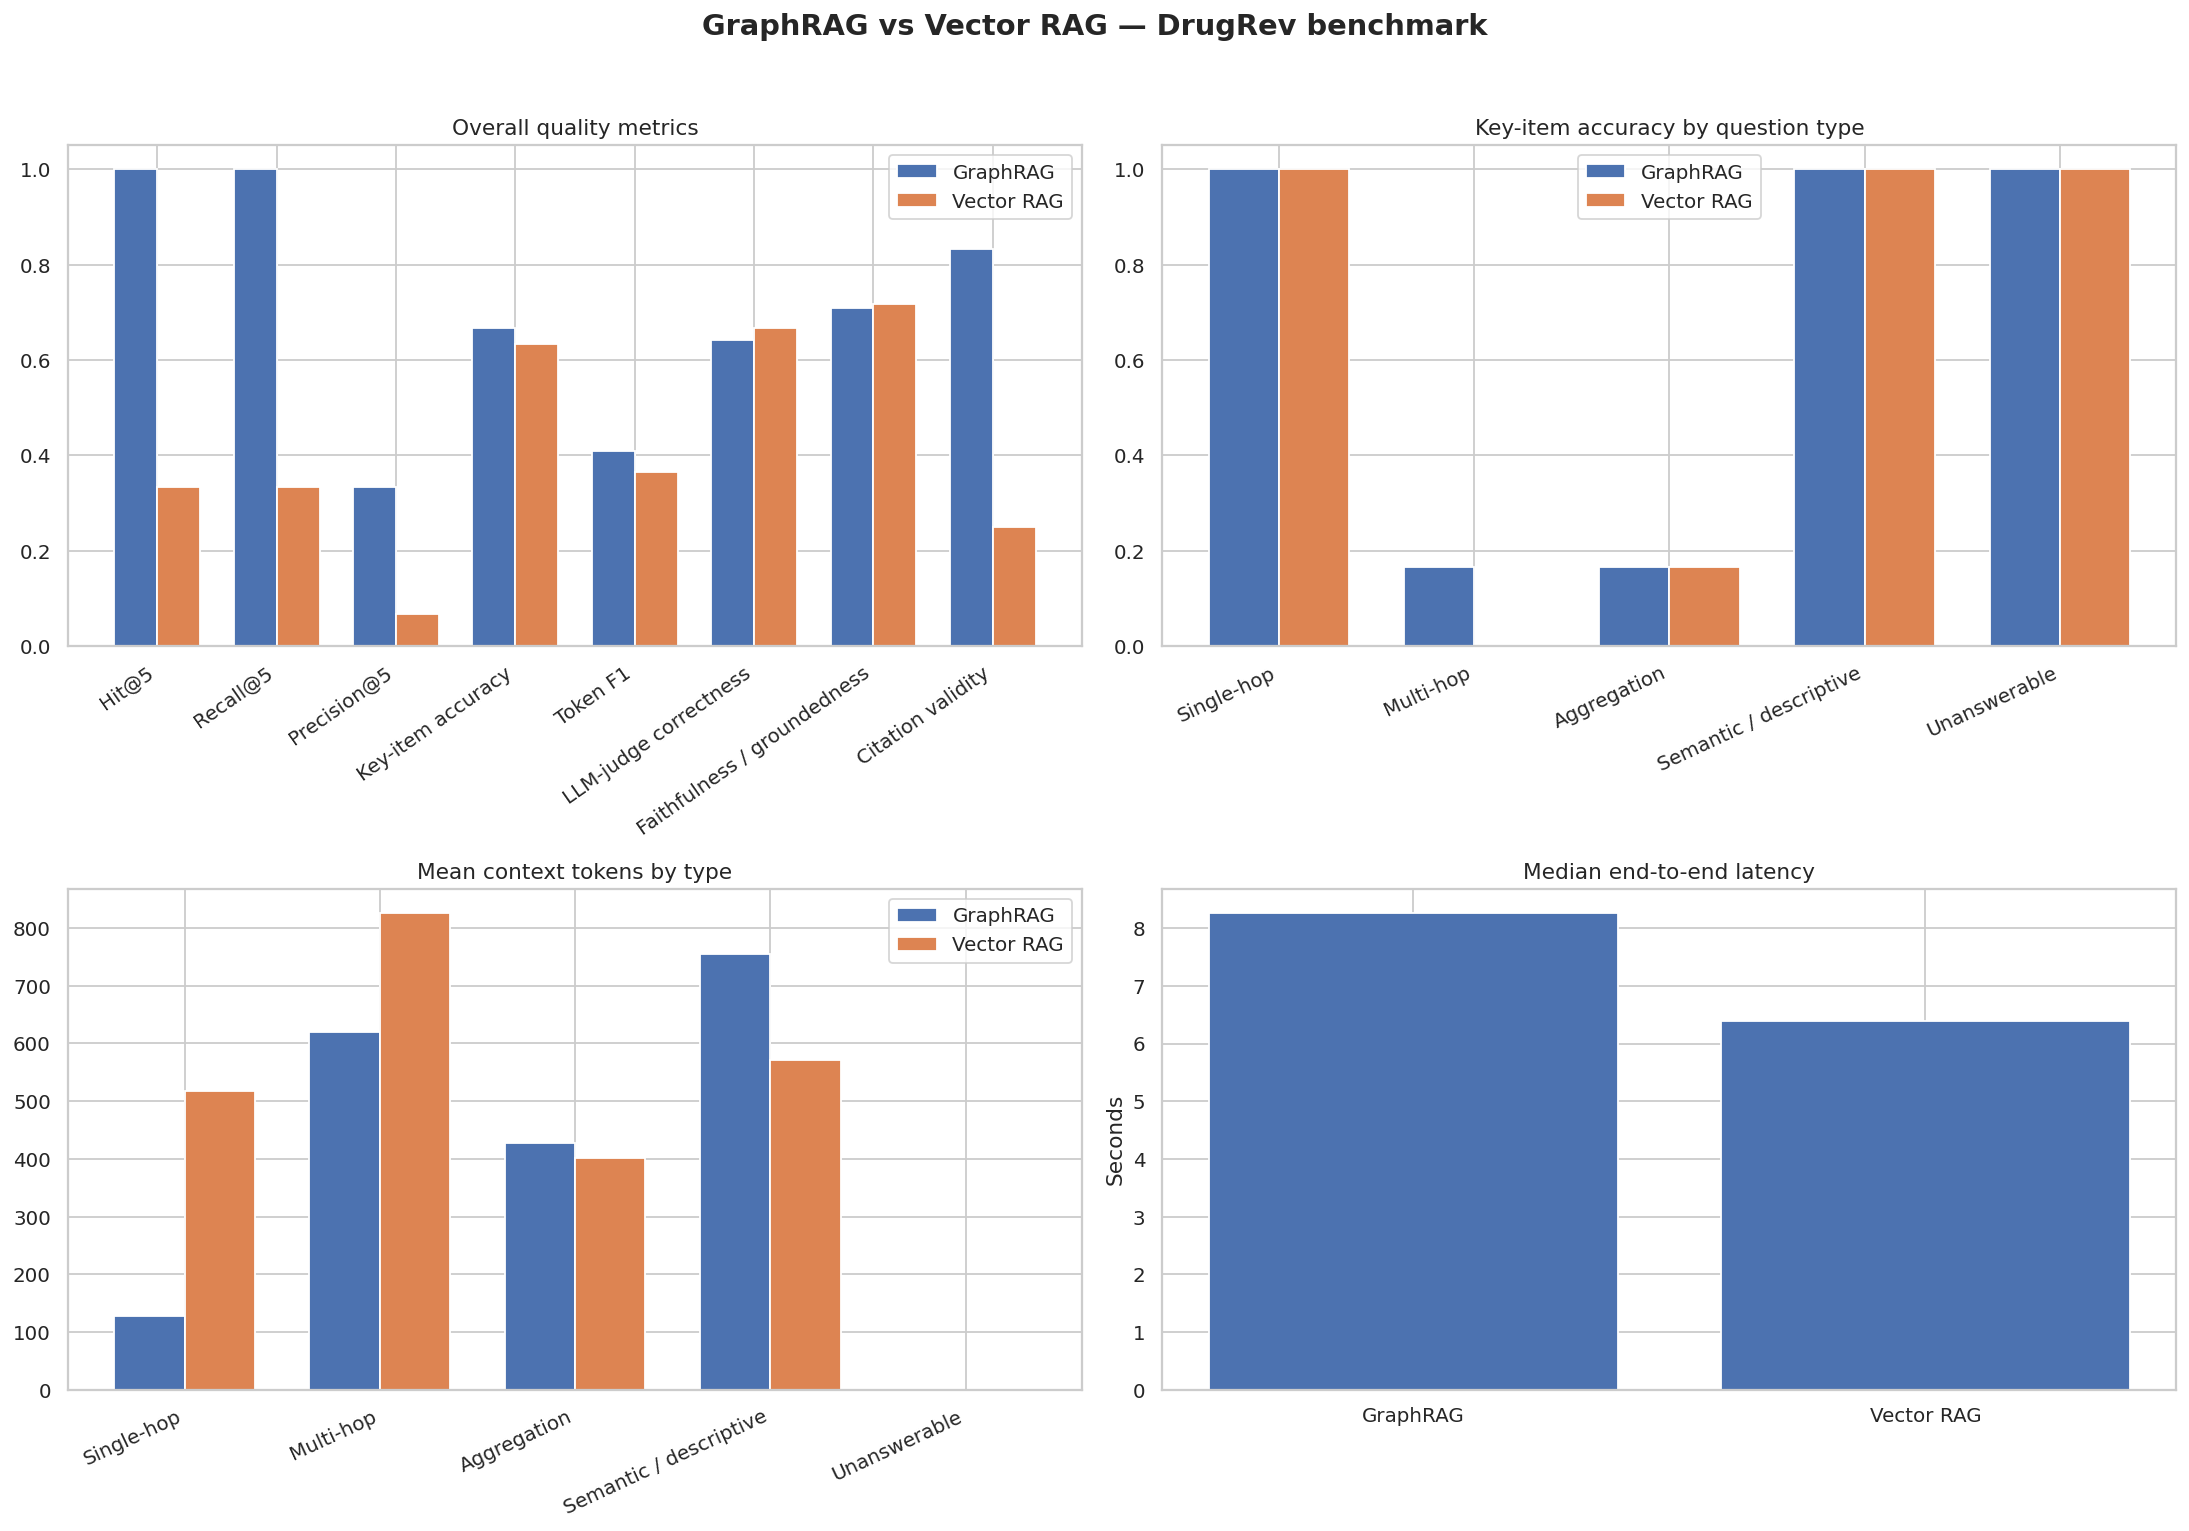

In [23]:
fig,axes=plt.subplots(2,2,figsize=(17,12))
fig.suptitle("GraphRAG vs Vector RAG — DrugRev benchmark",fontsize=16,fontweight="bold")
core=df_overall[df_overall["Metric"].isin(["Hit@5","Recall@5","Precision@5","Key-item accuracy","Token F1","LLM-judge correctness","Faithfulness / groundedness","Citation validity"])].copy()
x=np.arange(len(core)); w=.36
axes[0,0].bar(x-w/2,core["GraphRAG"],w,label="GraphRAG")
axes[0,0].bar(x+w/2,core["VectorRAG"],w,label="Vector RAG")
axes[0,0].set_xticks(x); axes[0,0].set_xticklabels(core["Metric"],rotation=35,ha="right"); axes[0,0].set_ylim(0,1.05); axes[0,0].set_title("Overall quality metrics"); axes[0,0].legend()
xt=np.arange(len(df_by_type)); axes[0,1].bar(xt-w/2,df_by_type["GraphRAG Key-item accuracy"],w,label="GraphRAG"); axes[0,1].bar(xt+w/2,df_by_type["VectorRAG Key-item accuracy"],w,label="Vector RAG")
axes[0,1].set_xticks(xt); axes[0,1].set_xticklabels(df_by_type["Question type"],rotation=25,ha="right"); axes[0,1].set_ylim(0,1.05); axes[0,1].set_title("Key-item accuracy by question type"); axes[0,1].legend()
axes[1,0].bar(xt-w/2,[df_g[df_g.type==t].context_tokens.mean() for t in df_by_type["Question type"]],w,label="GraphRAG")
axes[1,0].bar(xt+w/2,[df_v[df_v.type==t].context_tokens.mean() for t in df_by_type["Question type"]],w,label="Vector RAG")
axes[1,0].set_xticks(xt); axes[1,0].set_xticklabels(df_by_type["Question type"],rotation=25,ha="right"); axes[1,0].set_title("Mean context tokens by type"); axes[1,0].legend()
lat=[df_g["total_latency_sec"].median(),df_v["total_latency_sec"].median()]
axes[1,1].bar(["GraphRAG","Vector RAG"],lat); axes[1,1].set_title("Median end-to-end latency"); axes[1,1].set_ylabel("Seconds")
plt.tight_layout(rect=[0,0,1,.96]); plt.savefig(os.path.join(WORKING_DIR,"comparison_charts.png"),bbox_inches="tight"); plt.show()


## TASK 5 — Four-model ablation study

The main experiment uses Mistral 7B Instruct v0.3 for all 30 questions in both systems. The ablation uses one representative question from each of the five question categories and evaluates both retrieval systems under all four models. Mistral's five ablation observations are reused from the main run; Qwen, Zephyr, and Phi are run separately. This limits unnecessary repeated inference while still showing how generator choice changes both systems.


In [24]:
# Use five questions, one per required type, selected deterministically.
ablation_questions=[]
for qtype in ["Single-hop","Multi-hop","Aggregation","Semantic / descriptive","Unanswerable"]:
    ablation_questions.append(next(q for q in BENCHMARK if q["type"]==qtype))

# Reuse retrieved evidence from the main benchmark so only the generator changes in the ablation.
retrieval_cache={}
for _,row in df_main.iterrows():
    retrieval_cache[(row["question_id"],row["system"])]=row["retrieved_ids"]

def docs_for_ids(ids):
    return [DOC_LOOKUP[x] for x in ids if x in DOC_LOOKUP]

ablation_records=[]
# Mistral observations already exist in the primary run.
for q in ablation_questions:
    for system in ["GraphRAG","VectorRAG"]:
        row=df_main[(df_main.question_id==q["id"])&(df_main.system==system)].iloc[0]
        ablation_records.append({"model_key":"mistral_v03","model_name":MODEL_REGISTRY["mistral_v03"]["name"],"question_id":q["id"],"type":q["type"],"system":system,
            "answer":row["answer"],"accuracy_key_item":key_item_accuracy(row["answer"],q),"token_f1":token_f1(row["answer"],q["gold"]),"generation_latency_sec":row["generation_latency_sec"]})

# Qwen is already loaded as the independent judge; use it for its ablation answers.
for q in ablation_questions:
    for system in ["GraphRAG","VectorRAG"]:
        ids=retrieval_cache[(q["id"],system)]
        docs=docs_for_ids(ids)
        if q["type"]=="Unanswerable":
            ans="I cannot answer this question from the available data."; latency=0.0
        else:
            out=generate_with_loaded_model(judge_tokenizer,judge_model,q["question"],docs)
            ans=out["answer"]; latency=out["generation_latency"]
        ablation_records.append({"model_key":"qwen25_7b","model_name":MODEL_REGISTRY["qwen25_7b"]["name"],"question_id":q["id"],"type":q["type"],"system":system,
            "answer":ans,"accuracy_key_item":key_item_accuracy(ans,q),"token_f1":token_f1(ans,q["gold"]),"generation_latency_sec":latency})

del judge_model,judge_tokenizer
judge_model=None; judge_tokenizer=None
cleanup_model_cache(JUDGE_MODEL_KEY)

# Load remaining ablation models one at a time to control GPU memory.
for model_key in ["zephyr_7b","phi35_mini"]:
    tok,mdl=load_local_model(model_key)
    for q in ablation_questions:
        for system in ["GraphRAG","VectorRAG"]:
            ids=retrieval_cache[(q["id"],system)]
            docs=docs_for_ids(ids)
            if q["type"]=="Unanswerable":
                ans="I cannot answer this question from the available data."; latency=0.0
            else:
                out=generate_with_loaded_model(tok,mdl,q["question"],docs)
                ans=out["answer"]; latency=out["generation_latency"]
            ablation_records.append({"model_key":model_key,"model_name":MODEL_REGISTRY[model_key]["name"],"question_id":q["id"],"type":q["type"],"system":system,
                "answer":ans,"accuracy_key_item":key_item_accuracy(ans,q),"token_f1":token_f1(ans,q["gold"]),"generation_latency_sec":latency})
    del mdl,tok
    cleanup_model_cache(model_key)

df_ablation_detail=pd.DataFrame(ablation_records)
df_ablation_detail.to_csv(os.path.join(WORKING_DIR,"ablation_question_results.csv"),index=False)
df_ablation=(df_ablation_detail.groupby(["model_key","model_name","system"],as_index=False)
             .agg(n=("question_id","count"),key_item_accuracy=("accuracy_key_item","mean"),token_f1=("token_f1","mean"),median_generation_latency_sec=("generation_latency_sec","median")))
df_ablation.to_csv(os.path.join(WORKING_DIR,"ablation_results.csv"),index=False)
df_ablation_by_type=(df_ablation_detail.groupby(["model_key","model_name","type","system"],as_index=False)
    .agg(n=("question_id","count"),key_item_accuracy=("accuracy_key_item","mean"),token_f1=("token_f1","mean"),median_generation_latency_sec=("generation_latency_sec","median")))
df_ablation_by_type.to_csv(os.path.join(WORKING_DIR,"ablation_by_question_type.csv"),index=False)
display(df_ablation)
display(df_ablation_by_type)


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:628: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:633: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:650: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


Loading Zephyr 7B Beta (HuggingFaceH4/zephyr-7b-beta) in 4-bit NF4 mode...


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

... (28 outputs left out)

generation_config.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

The `seen_tokens` attribute is deprecated and will be removed in v4.41. Use the `cache_position` model input instead.
`get_max_cache()` is deprecated for all Cache classes. Use `get_max_cache_shape()` instead. Calling `get_max_cache()` will raise error from v4.48
You are not running the flash-attention implementation, expect numerical differences.


,model_key,model_name,system,n,key_item_accuracy,token_f1,median_generation_latency_sec
0,mistral_v03,Mistral 7B Instruct v0.3,GraphRAG,5,0.6,0.437207,8.458204
1,mistral_v03,Mistral 7B Instruct v0.3,VectorRAG,5,0.6,0.344825,6.472434
2,phi35_mini,Phi-3.5 Mini Instruct,GraphRAG,5,0.6,0.424066,13.268945
3,phi35_mini,Phi-3.5 Mini Instruct,VectorRAG,5,0.6,0.357810,8.847209
4,qwen25_7b,Qwen 2.5 7B Instruct,GraphRAG,5,0.6,0.395850,8.086626
5,qwen25_7b,Qwen 2.5 7B Instruct,VectorRAG,5,0.6,0.328955,4.942620
6,zephyr_7b,Zephyr 7B Beta,GraphRAG,5,0.6,0.446731,11.108082
7,zephyr_7b,Zephyr 7B Beta,VectorRAG,5,0.6,0.328376,11.057970


,model_key,model_name,type,system,n,key_item_accuracy,token_f1,median_generation_latency_sec
0,mistral_v03,Mistral 7B Instruct v0.3,Aggregation,GraphRAG,1,0.0,0.448980,11.232105
1,mistral_v03,Mistral 7B Instruct v0.3,Aggregation,VectorRAG,1,0.0,0.226415,11.387854
2,mistral_v03,Mistral 7B Instruct v0.3,Multi-hop,GraphRAG,1,0.0,0.366667,8.040779
3,mistral_v03,Mistral 7B Instruct v0.3,Multi-hop,VectorRAG,1,0.0,0.337349,10.522969
4,mistral_v03,Mistral 7B Instruct v0.3,Semantic / descriptive,GraphRAG,1,1.0,0.245902,10.560070
5,mistral_v03,Mistral 7B Instruct v0.3,Semantic / descriptive,VectorRAG,1,1.0,0.164835,6.164300
6,mistral_v03,Mistral 7B Instruct v0.3,Single-hop,GraphRAG,1,1.0,0.705882,8.458204
7,mistral_v03,Mistral 7B Instruct v0.3,Single-hop,VectorRAG,1,1.0,0.576923,6.472434
8,mistral_v03,Mistral 7B Instruct v0.3,Unanswerable,GraphRAG,1,1.0,0.418605,0.000000
9,mistral_v03,Mistral 7B Instruct v0.3,Unanswerable,VectorRAG,1,1.0,0.418605,0.000000


## TASK 7 — Fairness, cost, failure analysis, and recommendation

### 7.1 Fairness controls

The main comparison holds the source sample, evidence corpus, benchmark, gold answers, primary generator, system prompt, temperature, decoding strategy, maximum output tokens, context budget, and retrieval depth constant. The intended difference is retrieval: Neo4j graph queries and graph traversal versus ChromaDB dense vector similarity search. The graph system does not use dense embeddings; the vector system does.


In [25]:
fairness_rows=[
    {"Factor":"Source data and sample","GraphRAG":"Same selected DrugRev sample","Vector RAG":"Same selected DrugRev sample","Treatment":"Held constant"},
    {"Factor":"Evidence corpus","GraphRAG":"Same stable-ID summary and review documents represented in graph nodes/edges","Vector RAG":"Same stable-ID summary and review documents in ChromaDB","Treatment":"Held constant at source/evidence level"},
    {"Factor":"Primary generator","GraphRAG":MODEL_REGISTRY[PRIMARY_MODEL_KEY]["name"],"Vector RAG":MODEL_REGISTRY[PRIMARY_MODEL_KEY]["name"],"Treatment":"Held constant"},
    {"Factor":"Prompt and refusal policy","GraphRAG":"Same system prompt and shared out-of-scope gate","Vector RAG":"Same system prompt and shared out-of-scope gate","Treatment":"Held constant"},
    {"Factor":"Decoding","GraphRAG":"Temperature 0; greedy; max 160 new tokens","Vector RAG":"Temperature 0; greedy; max 160 new tokens","Treatment":"Held constant"},
    {"Factor":"Context budget","GraphRAG":f"{MAX_CONTEXT_TOKENS} input-context tokens","Vector RAG":f"{MAX_CONTEXT_TOKENS} input-context tokens","Treatment":"Held constant"},
    {"Factor":"Retrieval depth","GraphRAG":f"Up to {TOP_K} evidence items","Vector RAG":f"Top-{TOP_K} nearest documents","Treatment":"Held constant"},
    {"Factor":"Retrieval mechanism","GraphRAG":"Parameterized Cypher, graph paths, aggregate facts, full-text fallback","Vector RAG":"MiniLM-L6-v2 dense embeddings and cosine distance","Treatment":"Intended experimental difference"},
    {"Factor":"Vector embedding","GraphRAG":"Not used for graph retrieval","Vector RAG":"Default Chroma ONNX MiniLM-L6-v2 (384 dimensions)","Treatment":"Different by design"}
]
df_fairness=pd.DataFrame(fairness_rows)
df_fairness.to_csv(os.path.join(WORKING_DIR,"fairness_table.csv"),index=False)
display(df_fairness)


,Factor,GraphRAG,Vector RAG,Treatment
0,Source data and sample,Same selected DrugRev sample,Same selected DrugRev sample,Held constant
1,Evidence corpus,Same stable-ID summary and review documents represented in graph nodes/edges,Same stable-ID summary and review documents in ChromaDB,Held constant at source/evidence level
2,Primary generator,Mistral 7B Instruct v0.3,Mistral 7B Instruct v0.3,Held constant
3,Prompt and refusal policy,Same system prompt and shared out-of-scope gate,Same system prompt and shared out-of-scope gate,Held constant
4,Decoding,Temperature 0; greedy; max 160 new tokens,Temperature 0; greedy; max 160 new tokens,Held constant
5,Context budget,1800 input-context tokens,1800 input-context tokens,Held constant
6,Retrieval depth,Up to 5 evidence items,Top-5 nearest documents,Held constant
7,Retrieval mechanism,"Parameterized Cypher, graph paths, aggregate facts, full-text fallback",MiniLM-L6-v2 dense embeddings and cosine distance,Intended experimental difference
8,Vector embedding,Not used for graph retrieval,Default Chroma ONNX MiniLM-L6-v2 (384 dimensions),Different by design


### 7.2 Measured cost and efficiency comparison


In [26]:
cost_rows=[
    {"Dimension":"Implementation effort (qualitative)","GraphRAG":"Higher: schema design, six node labels, seven relationship types, constraints, provenance, batched Cypher, and query templates","Vector RAG":"Moderate: document serialization, embedding generation, and ChromaDB indexing","Measurement":"Qualitative engineering-effort assessment; not person-hours"},
    {"Dimension":"Graph build / load time (seconds)","GraphRAG":graph_build_time,"Vector RAG":np.nan,"Measurement":"Measured Neo4j Aura load time"},
    {"Dimension":"Vector indexing time (seconds)","GraphRAG":np.nan,"Vector RAG":vector_indexing_time,"Measurement":"Measured ChromaDB embedding and indexing time"},
    {"Dimension":"Median retrieval latency (seconds)","GraphRAG":df_g["retrieval_latency_sec"].median(),"Vector RAG":df_v["retrieval_latency_sec"].median(),"Measurement":"Median over benchmark questions"},
    {"Dimension":"Median generation latency (seconds)","GraphRAG":df_g["generation_latency_sec"].median(),"Vector RAG":df_v["generation_latency_sec"].median(),"Measurement":"Same generator; median over benchmark questions"},
    {"Dimension":"Median end-to-end latency (seconds)","GraphRAG":df_g["total_latency_sec"].median(),"Vector RAG":df_v["total_latency_sec"].median(),"Measurement":"Retrieval plus generation"},
    {"Dimension":"Mean context tokens","GraphRAG":df_g["context_tokens"].mean(),"Vector RAG":df_v["context_tokens"].mean(),"Measurement":"Primary generator tokenizer"},
    {"Dimension":"Evidence corpus documents","GraphRAG":len(ALL_DOC_RECORDS),"Vector RAG":collection.count(),"Measurement":"Same evidence corpus; graph and vector representations differ"},
    {"Dimension":"Sampled source reviews","GraphRAG":len(df),"Vector RAG":len(df),"Measurement":"Same sample size"}
]
df_cost=pd.DataFrame(cost_rows)
df_cost.to_csv(os.path.join(WORKING_DIR,"cost_comparison.csv"),index=False)
display(df_cost)


,Dimension,GraphRAG,Vector RAG,Measurement
0,Implementation effort (qualitative),"Higher: schema design, six node labels, seven relationship types, constraints, provenance, batched Cypher, and query templates","Moderate: document serialization, embedding generation, and ChromaDB indexing",Qualitative engineering-effort assessment; not person-hours
1,Graph build / load time (seconds),12.80816,NaN,Measured Neo4j Aura load time
2,Vector indexing time (seconds),NaN,292.898855,Measured ChromaDB embedding and indexing time
3,Median retrieval latency (seconds),0.466308,0.05642,Median over benchmark questions
4,Median generation latency (seconds),7.745914,6.324448,Same generator; median over benchmark questions
5,Median end-to-end latency (seconds),8.265056,6.390782,Retrieval plus generation
6,Mean context tokens,385.8,463.333333,Primary generator tokenizer
7,Evidence corpus documents,5584,5584,Same evidence corpus; graph and vector representations differ
8,Sampled source reviews,4500,4500,Same sample size


### 7.3 Evidence-based error analysis — at least five cases

The notebook selects the five weakest observed system-question cases using retrieval recall, key-item accuracy, judge correctness, and groundedness. It records the actual retrieved evidence IDs, model answer, gold answer, and a diagnostic root-cause category. If fewer than five genuine failures occur, remaining rows are explicitly labelled as lowest-scoring near-misses rather than fabricated failures.


In [27]:
# Select five weakest cases across both systems; preserve actual answers and retrieved evidence.
fail_frame=df_eval.copy()
fail_frame["retrieval_recall_for_rank"]=fail_frame["recall_at_5"].fillna(1.0)
fail_frame["failure_score"]=(1-fail_frame["accuracy_key_item"].fillna(1.0))+(1-fail_frame["llm_judge_correctness"].fillna(1.0))+(1-fail_frame["faithfulness_groundedness"].fillna(1.0))+(1-fail_frame["retrieval_recall_for_rank"])
fail_frame=fail_frame.sort_values(["failure_score","total_latency_sec"],ascending=[False,False]).head(5)
failures=[]
for rank,(_,r) in enumerate(fail_frame.iterrows(),1):
    if r["type"]=="Unanswerable" and float(r["accuracy_key_item"] or 0)<1:
        cause="Refusal failure: the answer did not clearly decline an out-of-scope request."
    elif pd.notna(r["recall_at_5"]) and r["recall_at_5"]<1:
        cause="Retrieval miss: one or more gold evidence IDs were absent from the top-five ranked results."
    elif float(r["accuracy_key_item"] or 0)<1:
        cause="Generation/key-item mismatch: retrieved evidence did not translate into all required answer items."
    elif float(r["faithfulness_groundedness"] or 0)<0.75:
        cause="Grounding concern: the independent judge found one or more answer claims insufficiently supported."
    else:
        cause="Lowest-scoring observed case; no major failure detected by the measured criteria. Treat as a near-miss for qualitative review."
    failures.append({"rank":rank,"system":r["system"],"question_id":r["question_id"],"question":r["question"],
        "retrieved_evidence_ids":"; ".join(r["retrieved_ids"]),"retrieved_evidence_text":r["retrieved_context"],"answer":r["answer"],"gold_answer":r["gold"],
        "retrieval_recall_at_5":r["recall_at_5"],"key_item_accuracy":r["accuracy_key_item"],
        "judge_correctness":r["llm_judge_correctness"],"faithfulness":r["faithfulness_groundedness"],"root_cause_diagnosis":cause,
        "failure_or_near_miss":"Observed failure" if r["failure_score"]>0 else "Near-miss / lowest-scoring case"})
df_failures=pd.DataFrame(failures)
df_failures.to_csv(os.path.join(WORKING_DIR,"failure_analysis.csv"),index=False)
display(df_failures)


,rank,system,question_id,question,retrieved_evidence_ids,retrieved_evidence_text,answer,gold_answer,retrieval_recall_at_5,key_item_accuracy,judge_correctness,faithfulness,root_cause_diagnosis,failure_or_near_miss
0,1,VectorRAG,AG1,What are the top three highest-rated medications for High Blood Pressure with at least five sampled reviews?,COND_57827261A660; PAIR_4910985CE9D4; DRUG_4F3D5BBC4CE4; PAIR_3D25F91CA7CF; DRUG_756DCC00F40D,"[EVIDENCE_ID: COND_57827261A660]\nCondition High Blood Pressure. In the selected DrugRev sample it appears in 450 reviews, across 70 dis...","From the provided data, we can see that the medications Toprol-XL and Bystolic are both reviewed for High Blood Pressure. However, Topro...",The top three are Azor for High Blood Pressure (8.67/10; 6 reviews); Atenolol for High Blood Pressure (7.64/10; 11 reviews); Diovan for ...,0.0,0.0,0.00,0.00,Retrieval miss: one or more gold evidence IDs were absent from the top-five ranked results.,Observed failure
1,2,VectorRAG,AG4,Which medication has the largest number of reviews in the selected sample?,COND_2C4C6516EBBB; DRUG_20ED5DE4904C; COND_E25D80DE16B2; DRUG_AACF9EBB7BCB; DRUG_06629D853932,"[EVIDENCE_ID: COND_2C4C6516EBBB]\nCondition Diabetes, Type 2. In the selected DrugRev sample it appears in 450 reviews, across 45 distin...","The medication with the largest number of reviews in the selected sample is Orlistat, with 7 reviews.\n\nSources: [EVIDENCE_ID: DRUG_066...",Phentermine has the largest number of reviews (100).,0.0,0.0,0.00,0.00,Retrieval miss: one or more gold evidence IDs were absent from the top-five ranked results.,Observed failure
2,3,VectorRAG,AG2,What are the three most frequently mentioned adverse-reaction terms across the selected review sample?,ADR_5A10D1B73C01; ADR_2DE845E8C2A4; ADR_54CAAB2E437E; ADR_CEE0B2BD1970; ADR_04938C149897,[EVIDENCE_ID: ADR_5A10D1B73C01]\nAdverse-reaction term agitation (Psychiatric) appears in 16 distinct sampled reviews and is associated ...,The three most frequently mentioned adverse-reaction terms across the selected review sample are:\n\n1. agitation (Psychiatric) - appear...,"The leading lexicon-matched terms are insomnia (223 reviews); nausea (187 reviews); weight loss (106 reviews). These are mentions, not c...",0.0,0.0,0.25,0.75,Retrieval miss: one or more gold evidence IDs were absent from the top-five ranked results.,Observed failure
3,4,GraphRAG,MH6,Which medications used for Bipolar Disorder have patient reviews mentioning insomnia? List the leading medications in this sample.,PAIR_D754C2CA907A; PAIR_3C6BFE824F35; PAIR_180F0E50C8E7; PAIR_0DB469BDE9DB; PAIR_43B487E05887,[EVIDENCE_ID: PAIR_D754C2CA907A]\nMedication Abilify is reviewed for condition Bipolar Disorder. In this selected sample there are 29 re...,"The leading medications in the sample with patient reviews mentioning insomnia for Bipolar Disorder are Abilify, Seroquel, Latuda, Vrayl...",The leading medication-condition links with insomnia mentions for Bipolar Disorder are: Abilify (3 review mentions); Seroquel (3 review ...,1.0,0.0,0.00,0.00,Generation/key-item mismatch: retrieved evidence did not translate into all required answer items.,Observed failure
4,5,VectorRAG,AG3,Which condition has the largest number of reviews in the selected sample?,COND_E25D80DE16B2; COND_2C4C6516EBBB; COND_4582CD02EE9F; COND_5FD91ECC1EEC; COND_AD0053AB4F48,"[EVIDENCE_ID: COND_E25D80DE16B2]\nCondition Depression. In the selected DrugRev sample it appears in 450 reviews, across 65 distinct med...","The condition with the largest number of reviews in the selected sample is Pain, with 450 reviews. Sources: [COND_4582CD02EE9F], [COND_2...",ADHD has the largest number of reviews (450).,0.0,0.0,0.50,0.75,Retrieval miss: one or more gold evidence IDs were absent from the top-five ranked results.,Observed failure


### 7.4 Dynamic recommendation based on measured category results


In [28]:
graph_structural=df_by_type[df_by_type["Question type"].isin(["Multi-hop","Aggregation"])]["GraphRAG Key-item accuracy"].mean()
vector_structural=df_by_type[df_by_type["Question type"].isin(["Multi-hop","Aggregation"])]["VectorRAG Key-item accuracy"].mean()
vector_semantic=float(df_by_type.loc[df_by_type["Question type"]=="Semantic / descriptive","VectorRAG Key-item accuracy"].iloc[0])
graph_semantic=float(df_by_type.loc[df_by_type["Question type"]=="Semantic / descriptive","GraphRAG Key-item accuracy"].iloc[0])
if graph_structural>vector_structural:
    structural_text="GraphRAG performed better on average for the structural multi-hop and aggregation categories in this run."
else:
    structural_text="GraphRAG did not outperform Vector RAG on average for the structural multi-hop and aggregation categories in this run."
if vector_semantic>graph_semantic:
    semantic_text="Vector RAG performed better on semantic/descriptive accuracy in this run, supporting a hybrid design for narrative-heavy questions."
else:
    semantic_text="Vector RAG did not outperform GraphRAG on semantic/descriptive accuracy in this run; inspect the review-level evidence and failure cases before selecting an architecture."
recommendation=(structural_text+" "+semantic_text+" A production decision should also consider measured latency, data freshness, graph maintenance, evidence provenance, and the limitations of patient-reported data.")
print(recommendation)
with open(os.path.join(WORKING_DIR,"architectural_recommendation.txt"),"w",encoding="utf-8") as f: f.write(recommendation)


GraphRAG performed better on average for the structural multi-hop and aggregation categories in this run. Vector RAG did not outperform GraphRAG on semantic/descriptive accuracy in this run; inspect the review-level evidence and failure cases before selecting an architecture. A production decision should also consider measured latency, data freshness, graph maintenance, evidence provenance, and the limitations of patient-reported data.


## 7.5 Viva preparation checklist

Before the viva, be prepared to demonstrate and explain:

- why the DrugRev dataset and selected-condition sample were chosen, including the DOI, licence, sampling limitations, and dataset uniqueness relative to classmates;
- the six node labels, seven relationship types, composite uniqueness constraints, full-text indexes, and review-level provenance;
- one exploratory Cypher query and one multi-hop query, explaining each returned field;
- how ChromaDB serializes the same evidence corpus, how MiniLM embeddings and cosine distance work, and why top-k is five;
- why Mistral is the primary generator, why Qwen is the separate judge, and what 4-bit NF4 quantization changes;
- the definitions and calculations of Hit@5, Recall@5, Precision@5, MRR, key-item accuracy, Token F1, LLM-judge correctness, faithfulness, refusal accuracy, entity-linking P/R/F1, latency, and context tokens;
- one result where graph retrieval helps and one where dense retrieval helps, supported by the saved outputs;
- one actual failure case and its retrieved evidence, answer, gold answer, and diagnosed root cause.

The notebook prepares the reproducible evidence for the viva; the student must still practise and personally explain the design and code.

## 8. Submission artifacts and final verification

The notebook exports the benchmark, raw and aggregated results, schema tables, graph counts, Cypher outputs, EDA figures, ablation tables, fairness table, cost comparison, error analysis, and manual-audit templates to `/kaggle/working`. The report PDF and public Kaggle link are intentionally left for the report/submission stage.

### 8.1 AI-use statement template

Before submission, edit the AI-use statement below so it accurately reflects the tools you used. Do not claim that AI-generated code or analysis was independently verified unless you have checked it.


In [29]:
ai_use_statement = (
    "AI-use statement: AI assistance was used to support notebook restructuring, code debugging, "
    "documentation, and explanation of the GraphRAG/Vector RAG workflow. The student reviewed, "
    "tested, and takes responsibility for the submitted code, benchmark, interpretation, and results. "
    "Edit this statement to accurately describe the tools and assistance actually used."
)
with open(os.path.join(WORKING_DIR,"ai_use_statement_template.txt"),"w",encoding="utf-8") as f:
    f.write(ai_use_statement)
print(ai_use_statement)


AI-use statement: AI assistance was used to support notebook restructuring, code debugging, documentation, and explanation of the GraphRAG/Vector RAG workflow. The student reviewed, tested, and takes responsibility for the submitted code, benchmark, interpretation, and results. Edit this statement to accurately describe the tools and assistance actually used.


### 8.2 Check required result files and notebook completion status


In [30]:
expected_files=[
    "data_card.json","data_quality_report.csv","task1_eda.png","task1_eda_extended.png",
    "graph_schema.png","graph_node_schema.csv","graph_relationship_schema.csv",
    "neo4j_node_counts.csv","neo4j_relationship_counts.csv","exploratory_cypher_queries.csv",
    "drug_condition_summary.csv","adverse_reaction_summary.csv","condition_summary.csv","drug_summary.csv",
    "benchmark.csv","graphrag_results.csv","vectorrag_results.csv","results.csv","overall_results.csv",
    "results_by_type.csv","entity_linking_metrics.csv","llm_judge_scores.csv","judge_human_validation_template.csv",
    "adr_manual_validation_template.csv","ablation_results.csv","ablation_question_results.csv","ablation_by_question_type.csv","fairness_table.csv","cost_comparison.csv",
    "failure_analysis.csv","comparison_charts.png","architectural_recommendation.txt","ai_use_statement_template.txt"
]
verification=[]
for name in expected_files:
    path=os.path.join(WORKING_DIR,name)
    verification.append({"file":name,"exists":os.path.exists(path),"size_kb":round(os.path.getsize(path)/1024,2) if os.path.exists(path) else np.nan})
df_verification=pd.DataFrame(verification)
display(df_verification)
df_verification.to_csv(os.path.join(WORKING_DIR,"output_file_verification.csv"),index=False)

print("\n=== FINAL COMPUTATIONAL STATUS ===")
print("Sampled reviews:",len(df))
print("Benchmark questions:",len(BENCHMARK),"(6 per required category)")
print("Main benchmark answers:",len(df_eval),"(30 questions × 2 systems)")
print("Ablation rows:",len(df_ablation_detail),"(4 models × 5 questions × 2 systems)")
print("Graph build time (s):",round(graph_build_time,2))
print("Vector indexing time (s):",round(vector_indexing_time,2))
print("Manual ADR validation: pending human annotation unless adr_manual_validation_metrics.csv was produced")
print("Manual LLM-judge calibration: pending human annotation in judge_human_validation_template.csv")
print("Written report: not created in this notebook, as requested")
print("All computational outputs are saved in:",WORKING_DIR)

# Close Aura connection after all graph operations have finished.
driver.close()
print("Neo4j driver closed cleanly.")


,file,exists,size_kb
0,data_card.json,True,2.83
1,data_quality_report.csv,True,0.30
2,task1_eda.png,True,369.81
3,task1_eda_extended.png,True,400.20
4,graph_schema.png,True,149.39
5,graph_node_schema.csv,True,0.91
6,graph_relationship_schema.csv,True,1.04
7,neo4j_node_counts.csv,True,0.13
8,neo4j_relationship_counts.csv,True,0.14
9,exploratory_cypher_queries.csv,True,3.60



=== FINAL COMPUTATIONAL STATUS ===
Sampled reviews: 4500
Benchmark questions: 30 (6 per required category)
Main benchmark answers: 60 (30 questions × 2 systems)
Ablation rows: 40 (4 models × 5 questions × 2 systems)
Graph build time (s): 12.81
Vector indexing time (s): 292.9
Manual ADR validation: pending human annotation unless adr_manual_validation_metrics.csv was produced
Manual LLM-judge calibration: pending human annotation in judge_human_validation_template.csv
Written report: not created in this notebook, as requested
All computational outputs are saved in: /kaggle/working
Neo4j driver closed cleanly.
